# Paper materials regeneration — Multi-Representation Fusion for TDC ADMET Prediction

Single self-contained notebook that recomputes **every figure and table** from the released
source predictions (`recompute_data/`). One setup cell defines the recomputation once; the
figure cells write `figure1..6.png` + `figureS1.png`, the table cells write the per-table CSVs
and the consolidated `supplementary_tables.xlsx`.

- **Recomputed** (not hard-coded): all norm_scores, ranks, LOO/Shapley, correlations, the
  k-sweep, and the Wilcoxon statistics — from `recompute_data/predictions/*.parquet` and
  `recompute_data/leaderboards/*.csv`.
- **Fixed design metadata**: task groups / sizes / mechanism rationale and the final k=5
  ensemble composition are loaded from `recompute_data/task_metadata.json`.


In [1]:
# === Setup: figure/table regeneration for the ADMET multi-representation fusion paper ===
# Self-contained RECOMPUTATION from source predictions.
# Every figure/table quantity is recomputed here from raw per-seed per-molecule predictions
# (recompute_data/predictions/{model}.parquet), the per-model TDC leaderboard rankings
# (recompute_data/leaderboards/{model}.csv, direct training outputs), the 1023-subset uniform
# fusion sweep (recompute_data/clean_stage1_current.csv, all1023.csv), and the leaderboard
# ruler (recompute_data/tdc_leaderboard_snapshot.json). Nothing below is a hard-coded result;
# task metadata (ADMET group, training-set size, mechanism rationale) is loaded from
# recompute_data/task_metadata.json (fixed design labels, not recomputed). assert blocks verify the recomputed numbers against the
# manuscript values.
import os, json, io, itertools
from math import factorial
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import spearmanr, kendalltau, wilcoxon
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error
from statsmodels.stats.multitest import multipletests

HERE = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
RELDATA = os.path.join(HERE, "..", "data")          # release data/ dir (single canonical copy)
DATA = os.path.join(RELDATA, "recompute_data")
OUTDIR = os.path.join(HERE, "..", "figures"); os.makedirs(OUTDIR, exist_ok=True)  # write figures into release figures/ dir
META_GREY = "#888888"

def apply_figure_style(*, frame="open", font=None, sizes=(8, 7, 6), grid=False):
    import matplotlib as mpl
    if frame not in ("open", "boxed", "none"):
        raise ValueError(f"frame must be 'open'|'boxed'|'none', got {frame!r}")
    try:
        import os, sys, glob, matplotlib.font_manager as fm
        fdir = os.path.join(os.environ.get("CONDA_PREFIX") or sys.prefix, "fonts")
        if os.path.isdir(fdir):
            known = {f.fname for f in fm.fontManager.ttflist}
            for f in glob.glob(os.path.join(fdir, "*.ttf")):
                if f not in known:
                    fm.fontManager.addfont(f)
    except Exception:
        pass
    base, secondary, tick = sizes
    boxed = (frame == "boxed")
    rc = {
        "font.family": "sans-serif", "font.size": base, "axes.labelsize": base,
        "axes.titlesize": base, "legend.fontsize": secondary, "xtick.labelsize": tick,
        "ytick.labelsize": tick, "axes.linewidth": 0.6,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "axes.spines.top": boxed, "axes.spines.right": boxed,
        "axes.spines.left": frame != "none", "axes.spines.bottom": frame != "none",
        "axes.grid": bool(grid), "legend.frameon": False,
        "figure.dpi": 200, "savefig.dpi": 300, "savefig.bbox": "tight",
        "axes.titleweight": "normal", "axes.titlelocation": "left",
        "axes.labelweight": "normal", "lines.linewidth": 1.2, "patch.linewidth": 0.6,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    }
    if font:
        rc["font.sans-serif"] = [font, "DejaVu Sans"]
    mpl.rcParams.update(rc)

REG  = json.load(open(f"{DATA}/task_registry.json"))
SNAP = json.load(open(f"{DATA}/tdc_leaderboard_snapshot.json"))
MODELS = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer","mtl_map",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer","stl_map"]
TASKS  = [t for t in REG if t != "Bioavailability_Ma"]  # 21 evaluation tasks

def metric(name, y, p):
    """Compute a single TDC metric (mae/auroc/auprc/spearman) after dropping NaN labels."""
    y = np.asarray(y, float); p = np.asarray(p, float); m = ~np.isnan(y); y, p = y[m], p[m]
    if name == "mae":      return float(mean_absolute_error(y, p))
    if name == "auroc":    return float(roc_auc_score(y, p))
    if name == "auprc":    return float(average_precision_score(y, p))
    if name == "spearman": return float(spearmanr(y, p)[0])
    raise KeyError(name)

def norm_pct(score, task):
    """norm_score = fraction of TDC leaderboard models we beat (metric-direction aware)."""
    e = SNAP.get(task)
    if e is None or np.isnan(score): return np.nan
    s = [m["score"] for m in e["models"].values()]; met = REG[task]["metric"]
    worse = (sum(1 for x in s if x > score) if met == "mae" else sum(1 for x in s if x < score))
    return worse / len(s)

def rank_of(score, task):
    """Leaderboard rank of `score` for `task` (1 = best), metric-direction aware."""
    e = SNAP.get(task); met = REG[task]["metric"]
    s = [m["score"] for m in e["models"].values()]
    return (sum(1 for x in s if x < score) if met == "mae" else sum(1 for x in s if x > score)) + 1

# ---- load predictions (add replicate counter for exact merge keys) ----
PRED = {}
for m in MODELS:
    d = pd.read_parquet(f"{DATA}/predictions/{m}.parquet")
    PRED[m] = d.assign(rep=d.groupby(["seed","task","split","smiles"]).cumcount())

def merge_uniform(models, within):
    """Inner-join the given models' per-molecule predictions; add `yhat` = their uniform mean.
    within=True keeps the seed axis (matched-seed track); within=False averages predictions
    across seeds first (seed-averaged track). Returns the merged long DataFrame."""
    keys = ["seed","task","split","smiles","rep"] if within else ["task","split","smiles","rep"]
    if within:
        base = PRED[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(PRED[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    else:
        sm = {m: PRED[m].groupby(["task","split","smiles","rep"])
                       .agg(y_true=("y_true","first"), y_pred=("y_pred","mean")).reset_index() for m in models}
        base = sm[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(sm[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    base["yhat"] = base[[f"p_{m}" for m in models]].mean(axis=1)
    return base

def pertask_norm(models, within):
    """{task: norm_score} for the uniform-mean fusion of `models`, on the held-out test set.
    within=True: score each seed then average the per-seed norm; within=False: score once on
    the seed-averaged predictions."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            seed_sc = [metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]
            res[task] = norm_pct(float(np.mean(seed_sc)), task)
        else:
            res[task] = norm_pct(metric(met, t.y_true, t.yhat), task)
    return res

def pertask_raw(models, within):
    """{task: raw_score} for the uniform-mean fusion of `models`, held-out test set.
    Mirror of pertask_norm but returns the raw metric value (before leaderboard normalization).
    within=True: mean over the per-seed metric (matched-seed track)."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            res[task] = float(np.mean([metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]))
        else:
            res[task] = float(metric(met, t.y_true, t.yhat))
    return res

def subset_norm(models, within):
    """Mean of pertask_norm across the 21 evaluation tasks (one scalar per subset)."""
    return float(np.mean(list(pertask_norm(models, within).values())))

# ---- correlation matrices (exact XAI method) ----
def corr_matrices(within):
    """Mean off-diagonal |correlation| among the k=5 ensemble members, for both the
    standardized predictions and the standardized residuals (prediction - truth).

    Returns (pred_corr, resid_corr): how redundant the members' outputs / errors are.
    within=True  -> matched-seed track: correlate per (task, seed), average the matrices.
    within=False -> seed-averaged track: pool all test rows per task, correlate once.
    (This is the exact 'XAI' correlation recipe used in the analysis notebooks.)
    """
    pred_cols = [f"p_{m}" for m in ENSEMBLE]
    base = merge_uniform(ENSEMBLE, within)
    if not within:
        # seed-averaged: concatenate standardized vectors across all tasks, one corr matrix
        pred_z  = {m: [] for m in ENSEMBLE}   # standardized predictions per member
        resid_z = {m: [] for m in ENSEMBLE}   # standardized residuals per member
        for task in TASKS:
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            for j, m in enumerate(ENSEMBLE):
                p = preds[:, j]; pred_z[m].append((p - p.mean())/(p.std()+1e-9))
                resid = p - y_true; resid_z[m].append((resid - resid.mean())/(resid.std()+1e-9))
        pred_z  = {m: np.concatenate(v) for m, v in pred_z.items()}
        resid_z = {m: np.concatenate(v) for m, v in resid_z.items()}
        pred_corr_mat  = np.corrcoef([pred_z[m]  for m in ENSEMBLE])
        resid_corr_mat = np.corrcoef([resid_z[m] for m in ENSEMBLE])
    else:
        # matched-seed: one corr matrix per (task, seed), then average across all of them
        seeds = sorted(base.seed.unique()); pred_mats = []; resid_mats = []
        for task in TASKS:
            task_rows = base[base.task==task]
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows) < 3: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                pred_z_seed = []; resid_z_seed = []
                for j, m in enumerate(ENSEMBLE):
                    p = preds[:, j]
                    pred_z_seed.append((p - p.mean())/(p.std()+1e-9))
                    resid_z_seed.append((p - y_true) - (p - y_true).mean()/((p - y_true).std()+1e-9))
                pred_mats.append(np.corrcoef(pred_z_seed)); resid_mats.append(np.corrcoef(resid_z_seed))
        pred_corr_mat  = np.nanmean(pred_mats, 0)
        resid_corr_mat = np.nanmean(resid_mats, 0)
    upper = np.triu_indices(len(ENSEMBLE), 1)   # off-diagonal (unordered pairs)
    return float(np.abs(pred_corr_mat[upper]).mean()), float(np.abs(resid_corr_mat[upper]).mean())

# ---- winners + best-single mean rank ----
def winners_best(within):
    """Per-task winner counts among the k=5 members + the best single member's mean TDC rank.

    Returns (wins, best_model, best_mean_rank):
      wins           - {model: number of tasks where it is the single best member}
      best_model     - member with the lowest mean leaderboard rank across tasks
      best_mean_rank - that member's mean rank (the single-model baseline the ensemble beats)
    within=True  -> matched-seed: winner decided per (task, seed); rank from seed-mean score.
    within=False -> seed-averaged: winner decided once per task on the seed-averaged score.
    """
    from collections import Counter
    base = merge_uniform(ENSEMBLE, within); pred_cols = [f"p_{m}" for m in ENSEMBLE]
    if not within:
        wins = Counter(); member_ranks = {m: [] for m in ENSEMBLE}   # per-task leaderboard rank
        for task in TASKS:
            met = REG[task]["metric"]
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
            wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
            for m in ENSEMBLE: member_ranks[m].append(rank_of(member_score[m], task))
    else:
        seeds = sorted(base.seed.unique()); wins = Counter(); member_score_by_task = {m: [] for m in ENSEMBLE}
        for task in TASKS:
            met = REG[task]["metric"]; task_rows = base[base.task==task]; seed_scores = {m: [] for m in ENSEMBLE}
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows)==0: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
                wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
                for m in ENSEMBLE: seed_scores[m].append(member_score[m])
            for m in ENSEMBLE: member_score_by_task[m].append(np.mean(seed_scores[m]))
        member_ranks = {m: [rank_of(member_score_by_task[m][i], TASKS[i]) for i in range(len(TASKS))] for m in ENSEMBLE}
    best_model = min(ENSEMBLE, key=lambda m: np.mean(member_ranks[m]))
    return dict(wins), best_model, float(np.mean(member_ranks[best_model]))

# ---- ensemble mean TDC rank (Score-then-Rank), within + cross ----
def ensemble_mean_rank():
    """Mean TDC leaderboard rank of the k=5 ensemble across tasks (Score-then-Rank).
    Returns (mean_rank_within, mean_rank_cross)."""
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False)
    ranks_w = []; ranks_c = []
    for task in TASKS:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ranks_w.append(rank_of(float(np.mean(seed_sc)), task))
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        ranks_c.append(rank_of(metric(met, tc.y_true, tc.yhat), task))
    return float(np.mean(ranks_w)), float(np.mean(ranks_c))

# ---- LOO + Shapley (over all 31 non-empty subsets of ENSEMBLE) ----
def loo_shapley():
    """Leave-one-out and Shapley contribution of each k=5 member to the ensemble norm_score.

    Enumerates all 31 non-empty subsets of ENSEMBLE and scores each (within + cross track):
      loo_within/cross    = value(full) - value(full minus this member)  (removal effect)
      shapley_within/cross= mean marginal contribution over all coalitions (Shapley value)
    Returns (per_member_dict, value_full_within, value_full_cross).
    """
    value_within = {}; value_cross = {}
    for size in range(1, len(ENSEMBLE)+1):
        for combo in itertools.combinations(ENSEMBLE, size):
            key = tuple(sorted(combo))
            value_within[key] = subset_norm(list(combo), True)
            value_cross[key]  = subset_norm(list(combo), False)
    full = tuple(sorted(ENSEMBLE)); n_members = len(ENSEMBLE)
    def shapley(value):
        contrib = {m: 0.0 for m in ENSEMBLE}
        for m in ENSEMBLE:
            others = [x for x in ENSEMBLE if x != m]
            for size in range(len(others)+1):
                for coalition in itertools.combinations(others, size):
                    weight = factorial(len(coalition))*factorial(n_members-len(coalition)-1)/factorial(n_members)
                    with_m    = value[tuple(sorted(coalition+(m,)))]
                    without_m = value[tuple(sorted(coalition))] if coalition else 0.0
                    contrib[m] += weight*(with_m - without_m)
        return contrib
    shap_within = shapley(value_within); shap_cross = shapley(value_cross); out = {}
    for m in ENSEMBLE:
        out[m] = {
            "within_solo": value_within[(m,)],
            "loo_within":  value_within[full] - value_within[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "cross_solo":  value_cross[(m,)],
            "loo_cross":   value_cross[full]  - value_cross[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "shapley_within": shap_within[m], "shapley_cross": shap_cross[m]}
    return out, value_within[full], value_cross[full]

# ---- MAP vs mean/max aggregation (leaderboard.csv `ours` -> re-ranked) ----
def map_agg():
    """MAP (joint latent fusion) vs naive mean/best aggregation of the 3 shared backbones,
    per training regime (mtl/stl). Uses leaderboard.csv `ours` scores re-normalized against
    the TDC snapshot. Returns (summary_dict, long_leaderboard_df)."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    def to_norm(ds, score):
        e = SNAP.get(ds)
        if e is None or pd.isna(score): return np.nan
        met = REG[ds]["metric"]; s = [x["score"] for x in e["models"].values()]
        rank = (sum(1 for x in s if x < score) if met=="mae" else sum(1 for x in s if x > score))+1
        return (len(s)-rank+1)/len(s)
    BACKS = ["chemeleon","graphmvp","molformer"]; res = {}
    for train in ["mtl","stl"]:
        bm = [f"{train}_{b}" for b in BACKS]
        piv = LONG[LONG.model.isin(bm)].pivot_table(index=["dataset","metric"], columns="model", values="ours", aggfunc="first")
        mp = LONG[LONG.model==f"{train}_map"].set_index("dataset").apply(lambda r: to_norm(r.name, r["ours"]), axis=1)
        mn = {}; mx = {}
        for (ds,met),row in piv.iterrows():
            vals = row[bm].dropna()
            if vals.empty: continue
            direction = SNAP.get(ds,{}).get("direction","higher")
            mn[ds] = to_norm(ds, vals.mean()); mx[ds] = to_norm(ds, vals.max() if direction=="higher" else vals.min())
        common = [d for d in mp.index if d in mn]
        mpv = mp[common]; mnv = pd.Series(mn)[common]; mxv = pd.Series(mx)[common]
        res[train] = {"map":round(float(mpv.mean()),3),"mean":round(float(mnv.mean()),3),"best":round(float(mxv.mean()),3),
                      "map_gt_mean":f"{int((mpv>mnv).sum())}/{len(common)}",
                      "map_gt_best":f"{int((mpv>mxv).sum())}/{len(common)}","n":len(common)}
    return res, LONG

# ---- ensemble-size sweep (top-20 mean per k over 1023 uniform subsets) ----
def ksweep():
    # clean_stage1_current.csv: the Stage-1 ensemble-size selection sweep over all 1,023
    #   non-empty uniform-mean subsets of the 10 backbones, scored on VALIDATION only.
    #   One row per subset; columns: k, bases (comma-joined member list),
    #   simple_{within,cross}_{norm,rank,ntask} (uniform-mean blending).
    #   (The file also carries legacy weighted_*/ridge_* meta-learner columns from an
    #   earlier design; the paper uses uniform-mean only, so they are ignored here.)
    #   Feeds Figure 3 + Table S3 (validation top-20-mean norm_score per k -> elbow at k=5).
    #   NOTE: this is NOT a duplicate of all1023.csv - it holds validation-only scores under
    #   several blending rules, whereas all1023.csv holds uniform val AND test scores. The
    #   validation columns differ numerically (max abs diff ~0.038) because they come from
    #   different scoring passes, and only all1023.csv carries the test columns Figure 4a needs.
    s1 = pd.read_csv(f"{DATA}/clean_stage1_current.csv")
    s1["k"] = s1.bases.apply(lambda b: len(b.split(",")))
    def topN(col, N=20):
        return {k: round(s1[s1.k==k].nlargest(min(N,(s1.k==k).sum()), col)[col].mean(),4) for k in range(1,11)}
    tw = topN("simple_within_norm"); tc = topN("simple_cross_norm")
    rows = []
    for k in range(1,11):
        rows.append([k, tw[k], round(tw[k]-tw[k-1],4) if k>1 else None,
                        tc[k], round(tc[k]-tc[k-1],4) if k>1 else None])
    return rows

# ---- validation->test rank reliability (all 1023 subsets) ----
def val_test_corr():
    # all1023.csv: uniform-mean fusion scored on BOTH validation and the fixed TDC test set,
    #   for every one of the 1,023 non-empty subsets. One row per subset; columns:
    #   combo_key (member list), k, val_within, val_cross, test_within, test_cross,
    #   val_comb, test_comb. This is the source for Figure 4a's validation->test rank
    #   reliability scatter, which REQUIRES the test_* columns (absent from clean_stage1).
    #   Complementary to, not a duplicate of, clean_stage1_current.csv (see ksweep()).
    from scipy.stats import spearmanr as _sp, kendalltau as _kt
    a = pd.read_csv(f"{DATA}/all1023.csv"); out = {}
    for name,vc,tc in [("within","val_within","test_within"),("cross","val_cross","test_cross"),("combined","val_comb","test_comb")]:
        out[name] = {"rho": round(_sp(a[vc],a[tc])[0],4), "tau": round(_kt(a[vc],a[tc])[0],4)}
    out["n_configs"] = len(a); return out

# ---- statistical tests (ensemble vs deployable singles + per-task oracle) ----
def stat_tests():
    ens_w = pertask_norm(ENSEMBLE, True); ens_c = pertask_norm(ENSEMBLE, False)
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    LONG["norm"] = (LONG.n_total - LONG["rank"] + 1)/LONG.n_total
    lbp = LONG.pivot_table(index="dataset", columns="model", values="norm").loc[TASKS]
    baselines = {"CheMeleon\u00b7STL":"stl_chemeleon","MAP\u00b7STL":"stl_map","D-MPNN\u00b7MTL":"mtl_dmpnn"}
    dep = {}; ora = {}
    for track, ens in [("within", ens_w), ("cross", ens_c)]:
        e = np.array([ens[t] for t in TASKS])
        for disp, m in baselines.items():
            b = lbp[m].to_numpy(); de = e - b; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
            dep[f"{disp}|{track}"] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
                "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(b.mean())}
        oc = lbp.max(axis=1).to_numpy(); de = e - oc; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
        ora[track] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
            "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(oc.mean())}
    return {"deployable_single":dep, "per_task_oracle":ora, "n_tasks":len(TASKS),
            "ensemble_mean":{"within":float(np.mean(list(ens_w.values()))),"cross":float(np.mean(list(ens_c.values())))}}

# ---- per-task tables t1 (per-backbone), t3 (MAP/mean/max), t4 (ensemble) ----
def leaderboard_long():
    """Concatenate every model's leaderboard.csv into one long frame with a `norm` column."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    L = pd.concat(lbs, ignore_index=True)
    L["norm"] = (L.n_total - L["rank"] + 1)/L.n_total
    return L

def table_t1(meta):
    """per-backbone per-task raw+norm on the WITHIN-SEED (matched-seed) basis: each seed is
    scored separately, mapped to a per-seed norm_score, then averaged over seeds (identical
    basis to Figure 1a / Table 3). meta = {task:{group,n}}. norm rounded to 3 decimals."""
    BB = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
    raw = {b: pertask_raw([b], True)  for b in BB}
    nrm = {b: pertask_norm([b], True) for b in BB}
    rows = []
    for task, mrec in meta.items():
        e = {"group": mrec["group"], "dataset": task, "n": mrec["n"], "metric": REG[task]["metric"]}
        for b in BB:
            e[b] = {"raw": round(float(raw[b][task]),3), "norm": round(float(nrm[b][task]),3)}
        rows.append(e)
    return rows

def table_t3(meta3):
    """MAP / latent-mean / latent-best per-task raw+norm on the WITHIN-SEED basis. MAP is the
    joint-fusion model's own per-seed prediction; latent mean/best aggregate the three backbones'
    per-seed scores (mean or direction-aware best) per seed, then norm and average. meta3 = {task:{group}}."""
    BACKS = ["chemeleon","graphmvp","molformer"]
    def agg_within(train, task, how):  # returns (raw, norm) within-seed for score-space mean/best
        met = REG[task]["metric"]; per_raw = []; per_norm = []
        seeds = sorted(PRED[f"{train}_{BACKS[0]}"].seed.unique())
        for seed in seeds:
            sc = []
            for bb in BACKS:
                d = PRED[f"{train}_{bb}"]
                t = d[(d.task==task)&(d.split=="test")&(d.seed==seed)].dropna(subset=["y_true"])
                sc.append(metric(met, t.y_true, t.y_pred))
            agg = np.mean(sc) if how=="mean" else (min(sc) if met=="mae" else max(sc))
            per_raw.append(agg); per_norm.append(norm_pct(agg, task))
        return float(np.mean(per_raw)), float(np.mean(per_norm))
    map_raw = {tr: pertask_raw([f"{tr}_map"], True)  for tr in ["mtl","stl"]}
    map_nrm = {tr: pertask_norm([f"{tr}_map"], True) for tr in ["mtl","stl"]}
    rows = []
    for task, mrec in meta3.items():
        met = REG[task]["metric"]; e = {"group": mrec["group"], "dataset": task, "metric": met}
        for train in ["mtl","stl"]:
            e[f"{train}_map"]  = {"raw": round(float(map_raw[train][task]),3), "norm": round(float(map_nrm[train][task]),3)}
            mr, mn = agg_within(train, task, "mean"); br, bn = agg_within(train, task, "best")
            e[f"{train}_mean"] = {"raw": round(mr,3), "norm": round(mn,3)}
            e[f"{train}_best"] = {"raw": round(br,3), "norm": round(bn,3)}
        rows.append(e)
    return rows

def table_t4():
    """ensemble per-task within/cross score+norm+rank over ALL 22 tasks (incl Bioavailability_Ma)."""
    allt = list(REG)
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False); rows = []
    for task in allt:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ws = float(np.mean(seed_sc)); ws_std = float(np.std(seed_sc, ddof=0))  # ddof=0 matches TDC ours_std
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        cs = metric(met, tc.y_true, tc.yhat)
        def _n(x, nd=3):  # int for exact 0/1 (match hardcoded schema), else float rounded to nd
            return int(x) if float(x).is_integer() else round(float(x), nd)
        rows.append({"task":task, "metric":met,
                     "within_score":round(ws,6), "within_std":round(ws_std,6), "within_norm":_n(norm_pct(ws,task),3), "within_rank":rank_of(ws,task),
                     "cross_score":round(cs,6),  "cross_norm":_n(norm_pct(cs,task),3),  "cross_rank":rank_of(cs,task)})
    return rows

# ---- Figure-1 within-seed solo + per-task (predictions basis) ----
def fig1_data(groups):
    """Figure 1 inputs on the within-seed (matched-seed) basis: per-model solo norm_score
    (`solo`), per-model per-task norm (`pertask`), and the ADMET mechanism `groups`."""
    solo = {m: subset_norm([m], True) for m in MODELS}
    pertask = []
    for task in TASKS:
        rec = {"task": task}
        for m in MODELS:
            rec[m] = pertask_norm([m], True)[task]
        pertask.append(rec)
    return {"solo": solo, "pertask": pertask, "groups": groups}

# ---- assemble full _GT / _PT / _FIG1 / _ST ----
def build_all(meta1, meta3, groups, t2, const_gt):
    lo, ens_w, ens_c = loo_shapley()
    cw = corr_matrices(True); cc = corr_matrices(False)
    win_w, bs_w, bsr_w = winners_best(True); win_c, bs_c, bsr_c = winners_best(False)
    mag, _ = map_agg()
    GT = dict(const_gt)  # final_ensemble, headline, sota_tasks, etc (constants)
    GT["map_agg"] = {t: {k: mag[t][k] for k in ["map","mean","best","map_gt_mean","map_gt_best"]} for t in ["mtl","stl"]}
    GT["ksweep"] = ksweep()
    GT["corr"] = {"within": {"pred_offdiag": round(cw[0],3), "resid_offdiag": round(cw[1],3)},
                  "cross":  {"pred_offdiag": round(cc[0],3), "resid_offdiag": round(cc[1],3)}}
    # ens_rank = mean TDC rank of the k=5 uniform ensemble across the 21 tasks (Score-then-Rank),
    # recomputed here (NOT a literal): within uses per-seed→mean→rank, cross uses seed-meaned→rank.
    ens_rank_w, ens_rank_c = ensemble_mean_rank()
    GT["best_single"] = {"within": {"model": bs_w, "mean_rank": round(bsr_w,3), "ens_rank": round(ens_rank_w,3)},
                         "cross":  {"model": bs_c, "mean_rank": round(bsr_c,3), "ens_rank": round(ens_rank_c,3)}}
    # per member -> [0]=within_solo  [1]=loo_within  [2]=cross_solo
    #                [3]=loo_cross    [4]=shapley_within  [5]=shapley_cross
    GT["loo_shapley"] = {b: [round(lo[b]["within_solo"],4), round(lo[b]["loo_within"],4),
                             round(lo[b]["cross_solo"],4), round(lo[b]["loo_cross"],4),
                             round(lo[b]["shapley_within"],4), round(lo[b]["shapley_cross"],4)] for b in ENSEMBLE}
    GT["winners"] = {"cross": {m: win_c.get(m,0) for m in ENSEMBLE},
                     "within_taskseed": {m: win_w.get(m,0) for m in ENSEMBLE}}
    GT["full_ensemble_norm"] = {"within": round(ens_w,4), "cross": round(ens_c,4)}
    PT = {"t1": table_t1(meta1), "t3": table_t3(meta3), "t4": table_t4(), "t2": t2}
    FIG1 = fig1_data(groups)
    ST = stat_tests()
    return GT, PT, FIG1, ST


# --- task metadata (fixed design labels, not recomputed): loaded from recompute_data/task_metadata.json ---
_TASK_META = json.load(open(f"{DATA}/task_metadata.json"))
_META1   = _TASK_META["meta1"]                                   # {task: {group, n}}
_META3   = {t: {"group": v["group"]} for t, v in _META1.items()} # meta1 without training-set size
_GROUPS  = _TASK_META["groups"]                                  # {mechanism group: [tasks]}
_T2      = _TASK_META["t2"]                                      # [{group, tasks, rationale}]
_CONST_GT = _TASK_META["const_gt"]                               # final_ensemble / final_composition / ...
ENSEMBLE  = list(_CONST_GT["final_ensemble"])                    # final k=5 members (single source of truth)


# --- recompute everything from source ---
_GT, _PT, _FIG1, _ST = build_all(_META1, _META3, _GROUPS, _T2, _CONST_GT)

# --- solo per-task within/cross norm (recomputed from predictions+leaderboards; replaces solo_pertask_within_cross.csv / fig1_within_pertask.csv) ---
# Per-(model, task) solo within/cross norm_score, recomputed from source predictions +
# leaderboard rankings. Replaces the released solo_pertask_within_cross.csv and
# fig1_within_pertask.csv (values verified identical to 1e-16).
# Row order matters ONLY for Figure 4d's winner-per-task argmax under exact norm ties
# (several tasks tie to the 4th decimal); we emit rows in the exact model/task order of
# the original fig1_within_pertask.csv so idxmax tie-breaking reproduces the published
# Figure 4d winner distribution (8/5/4/3/1). The norm values themselves are order-independent.
_SOLO_MODEL_ORDER = ["mtl_dmpnn","stl_dmpnn","stl_map","stl_chemeleon","stl_graphmvp",
                     "stl_molformer","mtl_graphmvp","mtl_molformer","mtl_chemeleon","mtl_map"]
_SOLO_TASK_ORDER  = ["HIA_Hou","Pgp_Broccatelli","BBB_Martins","CYP2C9_Veith","CYP2D6_Veith",
                     "CYP3A4_Veith","CYP2C9_Substrate_CarbonMangels","CYP2D6_Substrate_CarbonMangels",
                     "CYP3A4_Substrate_CarbonMangels","hERG","AMES","DILI","Caco2_Wang",
                     "Lipophilicity_AstraZeneca","Solubility_AqSolDB","PPBR_AZ","VDss_Lombardo",
                     "Half_Life_Obach","Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ","LD50_Zhu"]
def _solo_pertask_frame():
    per_model_within = {m: pertask_norm([m], True)  for m in _SOLO_MODEL_ORDER}
    per_model_cross  = {m: pertask_norm([m], False) for m in _SOLO_MODEL_ORDER}
    rows = []
    for m in _SOLO_MODEL_ORDER:
        for t in _SOLO_TASK_ORDER:
            rows.append({"model": m, "task": t,
                         "group":  _META1.get(t, {}).get("group", ""),
                         "metric": REG[t]["metric"],
                         "within_norm": per_model_within[m][t],
                         "cross_norm":  per_model_cross[m][t]})
    return pd.DataFrame(rows)
_SOLO_PT = _solo_pertask_frame()   # 210 rows = 10 backbones x 21 evaluation tasks

# --- assert recomputed values reproduce the manuscript (tolerance = rounding) ---
assert abs(_FIG1["solo"]["stl_chemeleon"] - 0.6331) < 0.002, _FIG1["solo"]["stl_chemeleon"]
assert abs(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8539) < 0.002
assert abs(np.mean([e["cross_norm"]  for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8971) < 0.002
assert _GT["winners"]["cross"]["mtl_dmpnn"] == 6 and _GT["winners"]["within_taskseed"]["mtl_dmpnn"] == 36
assert abs(_GT["map_agg"]["mtl"]["map"] - 0.621) < 0.002 and abs(_GT["map_agg"]["stl"]["map"] - 0.609) < 0.002
assert abs(_GT["corr"]["cross"]["pred_offdiag"] - 0.878) < 0.002 and abs(_GT["corr"]["within"]["pred_offdiag"] - 0.767) < 0.002
assert abs(_GT["ksweep"][4][1] - 0.7877) < 0.002 and abs(_GT["ksweep"][3][1] - 0.7825) < 0.002
assert abs(_GT["best_single"]["cross"]["mean_rank"] - 5.476) < 0.01 and abs(_GT["best_single"]["within"]["mean_rank"] - 8.429) < 0.01
assert len(_PT["t1"]) == 21 and len(_PT["t3"]) == 21 and len(_PT["t4"]) == 22

print("setup ok | recomputed from source | tasks:", len(_PT["t1"]),
      "| final ensemble:", _GT["final_ensemble"],
      "| ens within/cross norm:", round(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4),
      round(np.mean([e["cross_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4))


# --- consolidated-workbook helpers (from tables notebook) ---
OUT = "../tables"; os.makedirs(OUT, exist_ok=True)
TABLES = {}
def register(name, df, index=False):
    TABLES[name] = (df, index)
    df.to_csv(os.path.join(OUT, name + ".csv"), index=index)
    return df

BACKBONES = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
             "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
BB_LABEL  = {"mtl_dmpnn":"D-MPNN MTL","mtl_chemeleon":"CheMeleon MTL","mtl_graphmvp":"GraphMVP MTL",
             "mtl_molformer":"MoLFormer MTL","stl_dmpnn":"D-MPNN STL","stl_chemeleon":"CheMeleon STL",
             "stl_graphmvp":"GraphMVP STL","stl_molformer":"MoLFormer STL"}
def cell(d):  # "raw (norm_score)" — norm shown to 3 decimals (unified precision)
    return f'{d["raw"]:g} ({d["norm"]:.3f})'
print("recomputed pertask + ground_truth from source; backbones:", len(BACKBONES),
      "| S1 tasks:", len(_PT["t1"]), "| ksweep k:", len(_GT["ksweep"]))


setup ok | recomputed from source | tasks: 21 | final ensemble: ['mtl_dmpnn', 'mtl_molformer', 'stl_chemeleon', 'stl_graphmvp', 'stl_map'] | ens within/cross norm: 0.854 0.8971
recomputed pertask + ground_truth from source; backbones: 8 | S1 tasks: 21 | ksweep k: 10


## Table 1. Positioning of Tetra-Fuse relative to representative prior molecular-encoder fusion studies.

In [2]:
# --- Table 1: positioning of Tetra-Fuse relative to representative prior fusion studies ---
# Editorial comparison table (not computed). Prior-work characterizations follow the cited
# reports (MolPROP [19], FusionCLM [15], DCPM-ADMET [20]); Tetra-Fuse row describes this work.
T1_rows=[
 ["MolPROP [19]",
  "Language model (ChemBERTa-2) + graph (GCN/GATv2); 2 modalities",
  "Feature-level (token->node concatenation); single jointly-trained model",
  "Joint training; no ensemble selection; no meta-learner",
  "MoleculeNet (7 tasks)"],
 ["FusionCLM [15]",
  "Three homogeneous SMILES language models (ChemBERTa-2, MoLFormer, MolBERT)",
  "Two-level prediction/feature stacking",
  "Trained meta-learners (RF / NN) on losses+predictions",
  "MoleculeNet (5 tasks)"],
 ["DCPM-ADMET [20]",
  "Dual-channel pre-trained model + molecular fingerprints",
  "Feature-level fusion",
  "Jointly-trained fusion head",
  "ADMET (own split)"],
 ["Tetra-Fuse (this work)",
  "Heterogeneous: SMILES transformer, descriptor- and 3D-pretrained GNNs, from-scratch "
  "D-MPNN, and a feature-fusion MAP model; 0D-3D, pretrained+scratch, STL+MTL",
  "Both feature-level and prediction-level late fusion, compared in one framework",
  "Parameter-free uniform mean; no meta-learner; no additional cross-modal pre-training",
  "21 TDC ADMET (leaderboard-native) + external Polaris; validation-only exhaustive subset selection"],
]
T1=pd.DataFrame(T1_rows, columns=["Method","Encoder pool / heterogeneity","Fusion level",
    "Combination & training","Benchmark & selection"])
register("table1_positioning", T1)
assert len(T1)==4 and T1.iloc[3]["Method"]=="Tetra-Fuse (this work)"
print("Table 1 OK", T1.shape); T1


Table 1 OK (4, 5)


,Method,Encoder pool / heterogeneity,Fusion level,Combination & training,Benchmark & selection
0,MolPROP [19],Language model (ChemBERTa-2) + graph (GCN/GATv...,Feature-level (token->node concatenation); sin...,Joint training; no ensemble selection; no meta...,MoleculeNet (7 tasks)
1,FusionCLM [15],Three homogeneous SMILES language models (Chem...,Two-level prediction/feature stacking,Trained meta-learners (RF / NN) on losses+pred...,MoleculeNet (5 tasks)
2,DCPM-ADMET [20],Dual-channel pre-trained model + molecular fin...,Feature-level fusion,Jointly-trained fusion head,ADMET (own split)
3,Tetra-Fuse (this work),"Heterogeneous: SMILES transformer, descriptor-...",Both feature-level and prediction-level late f...,Parameter-free uniform mean; no meta-learner; ...,21 TDC ADMET (leaderboard-native) + external P...


*Table 1. Positioning of Tetra-Fuse relative to representative prior molecular-encoder fusion studies. For each method we summarize the encoder pool and its heterogeneity, the level at which representations are fused, how the members are combined and trained, and the benchmark and model-selection protocol. Unlike prior work that fuses a fixed pair of representations or an ensemble of homogeneous chemical language models, Tetra-Fuse draws on a heterogeneous 0D–3D pool (SMILES transformer, descriptor- and 3D-pretrained GNNs, a from-scratch D-MPNN, and a feature-fusion MAP model, under both STL and MTL) and contrasts feature-level and prediction-level fusion in one framework, combined by a parameter-free uniform mean with validation-only subset selection. Prior-work characterizations follow the cited reports.*

## Table S5 — Reproducibility summary

Architectural, parameter-efficient-fine-tuning, and optimization settings for every component of the pipeline, given separately for STL and MTL where they differ (e.g. adapter rank, head structure, learning rate, batch size, precision). All numbers are the actual node02 training recipes used for the 21-task TDC results.

In [3]:
# --- Table S5: reproducibility summary (architectures / PEFT / optimization, STL vs MTL) ---
# Hyperparameters below are taken from the actual node02 training recipes; STL and MTL differ
# in adapter bottleneck (CheMeleon), prediction head, batch size, base lr, and precision.
S5_rows = [['Data split & seeds', 'TDC ADMET Benchmark Group scaffold split. The fixed benchmark test set is held out; for each seed the remaining development data is split 0.875/0.125 into training/validation by scaffold (all 22 training tasks), five seeds (0-4) per model type, giving seed-specific held-out validation partitions. Prediction-level late-fusion candidate selection uses only these held-out validation predictions (no re-partitioning of the underlying data).'], ['D-MPNN backbone (STL & MTL)', 'chemprop D-MPNN trained from scratch (no pretrained prior); message-passing depth=3, hidden d_h=300, backbone dropout=0.0. Identical architecture for STL and MTL; they differ only in the prediction head and optimization (see below).'], ['CheMeleon backbone (STL & MTL)', 'Frozen chemeleon_mp.pt; hidden d_h=2048; AdapterGNN [23] (paper variant), adapter dropout=0.0. Adapter bottleneck differs by regime: STL r=128, MTL r=256 (the MTL trunk carries more shared capacity).'], ['GraphMVP backbone (STL & MTL)', 'Frozen graphmvp_hybrid.pth (regression variant), 5-layer GIN, emb_dim=300, JK=last, mean pooling; AdapterGNN [23] (paper variant), bottleneck r=64, adapter dropout=0.0. Same bottleneck for STL and MTL.'], ['MoLFormer backbone (STL & MTL)', 'MoLFormer-XL (ibm/MoLFormer-XL-both-10pct), precomputed tokens, max_len=202; LoRA [24] on query/value projections: rank=16, alpha=32, dropout=0.1. Same LoRA configuration for STL and MTL (LoRA dropout is raised to 0.2 only inside the MAP joint-fusion model).'], ['MAP joint-fusion module (MTL & STL)', 'Robust attention pooling (robust_attention) over the CheMeleon + GraphMVP + MoLFormer encoders; output_dim=300, entropy-regularization weight=0.01, attention-temperature annealing over 15 epochs, modality_dropout=0.2, residual + pre-norm. Constituent encoders use the same frozen priors / PEFT settings as above (MoLFormer LoRA dropout=0.2 here).'], ['MTL prediction head', 'GroupedHead over taskset_grouping (6 causal-chain mechanism groups, identical to the Table 1 grouping); trunk_hidden=128, head dropout=0.4; mixed Kendall task-uncertainty weighting [25].'], ['STL prediction head', 'Single-task bottleneck head (one head per endpoint, single-task loss); no cross-task weighting.'], ['Optimization', 'AdamW with early stopping on validation, max_epochs=100, patience=15 for all models. STL base models: base lr=1e-3, batch size 32, precision 32-true. MTL and MAP joint-fusion: base lr=5e-4, batch size 16, precision bf16-mixed. LoRA parameter group lr=5e-5 (MoLFormer and the MAP module); MAP fusion-module lr_fusion=1e-4.'], ['Leaderboard snapshot', 'TDC ADMET leaderboard snapshot 2026-04-29 08:18 UTC; per-task normalization denominator = 16-26 registered leaderboard models.']]
S5=pd.DataFrame(S5_rows, columns=["Component","Setting"])
register("tableS5_reproducibility", S5)
assert len(S5)==10 and S5.iloc[0]["Component"]=="Data split & seeds"
print("S5 OK", S5.shape); S5[["Component"]]


S5 OK (10, 2)


,Component
0,Data split & seeds
1,D-MPNN backbone (STL & MTL)
2,CheMeleon backbone (STL & MTL)
3,GraphMVP backbone (STL & MTL)
4,MoLFormer backbone (STL & MTL)
5,MAP joint-fusion module (MTL & STL)
6,MTL prediction head
7,STL prediction head
8,Optimization
9,Leaderboard snapshot


In [4]:
S5

,Component,Setting
0,Data split & seeds,TDC ADMET Benchmark Group scaffold split. The ...
1,D-MPNN backbone (STL & MTL),chemprop D-MPNN trained from scratch (no pretr...
2,CheMeleon backbone (STL & MTL),Frozen chemeleon_mp.pt; hidden d_h=2048; Adapt...
3,GraphMVP backbone (STL & MTL),Frozen graphmvp_hybrid.pth (regression variant...
4,MoLFormer backbone (STL & MTL),"MoLFormer-XL (ibm/MoLFormer-XL-both-10pct), pr..."
5,MAP joint-fusion module (MTL & STL),Robust attention pooling (robust_attention) ov...
6,MTL prediction head,GroupedHead over taskset_grouping (6 causal-ch...
7,STL prediction head,Single-task bottleneck head (one head per endp...
8,Optimization,"AdamW with early stopping on validation, max_e..."
9,Leaderboard snapshot,TDC ADMET leaderboard snapshot 2026-04-29 08:1...


## Table 2. Mechanism-informed grouping of the 22 TDC ADMET endpoints used by the grouped-head MTL model.

In [5]:
# --- Table 2: mechanism-informed grouping of the 22 TDC ADMET endpoints (grouped-head MTL) ---
# Editorial grouping (6 causal-chain mechanism groups). Group membership matches the
# GroupedHead taskset_grouping used in training; rationale text is from the manuscript.
T2_rows=[
 ["Oral uptake","Solubility_AqSolDB; Caco2_Wang; HIA_Hou; Bioavailability_Ma",
  "Solubility to intestinal absorption and systemic availability"],
 ["Distribution / CNS","Lipophilicity_AstraZeneca; PPBR_AZ; BBB_Martins; VDss_Lombardo",
  "Physicochemical distribution and CNS exposure"],
 ["Interaction liabilities","Pgp_Broccatelli; hERG; CYP(2C9/2D6/3A4)_Veith",
  "Transporter, ion-channel, and enzyme interaction risks"],
 ["Metabolic turnover","CYP(2C9/2D6/3A4)_Substrate_CarboMangels; Clearance_(Hepatocyte/Microsome)_AZ",
  "Substrate recognition and hepatic elimination"],
 ["Distal safety","AMES; DILI; LD50_Zhu",
  "Mutagenicity, organ toxicity, and acute toxicity"],
 ["Composite exposure","Half_Life_Obach",
  "Composite endpoint isolated to reduce gradient conflict"],
]
T2=pd.DataFrame(T2_rows, columns=["Mechanism group","TDC tasks","Rationale"])
register("table2_mechanism_grouping", T2)
# 22 endpoints across the 6 groups (count ';'-separated task tokens, expanding CYP(...)/Clearance_(...))
assert len(T2)==6
print("Table 2 OK", T2.shape); T2

Table 2 OK (6, 3)


,Mechanism group,TDC tasks,Rationale
0,Oral uptake,Solubility_AqSolDB; Caco2_Wang; HIA_Hou; Bioav...,Solubility to intestinal absorption and system...
1,Distribution / CNS,Lipophilicity_AstraZeneca; PPBR_AZ; BBB_Martin...,Physicochemical distribution and CNS exposure
2,Interaction liabilities,Pgp_Broccatelli; hERG; CYP(2C9/2D6/3A4)_Veith,"Transporter, ion-channel, and enzyme interacti..."
3,Metabolic turnover,CYP(2C9/2D6/3A4)_Substrate_CarboMangels; Clear...,Substrate recognition and hepatic elimination
4,Distal safety,AMES; DILI; LD50_Zhu,"Mutagenicity, organ toxicity, and acute toxicity"
5,Composite exposure,Half_Life_Obach,Composite endpoint isolated to reduce gradient...


*Table 2. Mechanism-informed grouping of the 22 TDC ADMET endpoints used for grouped-head multi-task learning. All 22 endpoints are used as MTL training tasks, but benchmark and ensemble evaluation use the 21 endpoints with valid leaderboard rankings; Bioavailability_Ma is retained as an MTL auxiliary task and excluded from evaluation because its TDC leaderboard ranking is unreliable (Supplementary Note S1). Dataset provenance and original source publications for all 22 endpoints are provided in Supplementary Table S7.*

## Table S7 — Dataset provenance for all 22 TDC ADMET endpoints

Provenance of all 22 TDC ADMET endpoints: the TDC task name, its ADMET category, the original dataset or data source, and the primary literature reference for each endpoint.

In [6]:
# --- Table S7: dataset provenance for all 22 TDC ADMET endpoints ---
S7_rows = [["Solubility_AqSolDB", "Absorption", "AqSolDB curated aqueous solubility", "Sorkun et al., Sci Data 2019, 6:143 (doi:10.1038/s41597-019-0151-1)"], ["Caco2_Wang", "Absorption", "Caco-2 cell permeability", "Wang et al., J Chem Inf Model 2016, 56(4):763–773 (doi:10.1021/acs.jcim.5b00642)"], ["HIA_Hou", "Absorption", "Human intestinal absorption", "Hou et al., J Chem Inf Model 2007, ADME evaluation 7 (doi:10.1021/ci600343x)"], ["Bioavailability_Ma", "Absorption", "Oral bioavailability", "Ma et al. 2008 (as attributed by TDC)"], ["Lipophilicity_AstraZeneca", "Absorption", "Lipophilicity (logD 7.4)", "AstraZeneca 2016 (ChEMBL deposit; as attributed by TDC)"], ["PPBR_AZ", "Distribution", "Plasma protein binding rate", "AstraZeneca 2016 (ChEMBL deposit; as attributed by TDC)"], ["VDss_Lombardo", "Distribution", "Volume of distribution at steady state", "Lombardo & Jing, J Chem Inf Model 2016, 56(10):2042–2052 (doi:10.1021/acs.jcim.6b00044)"], ["BBB_Martins", "Distribution", "Blood–brain barrier penetration", "Martins et al., J Chem Inf Model 2012, 52(6):1686–1697 (doi:10.1021/ci300124c)"], ["CYP2C9_Veith", "Metabolism", "CYP2C9 inhibition", "Veith et al., Nat Biotechnol 2009, 27(11):1050–1055 (doi:10.1038/nbt.1581)"], ["CYP2D6_Veith", "Metabolism", "CYP2D6 inhibition", "Veith et al., Nat Biotechnol 2009, 27(11):1050–1055 (doi:10.1038/nbt.1581)"], ["CYP3A4_Veith", "Metabolism", "CYP3A4 inhibition", "Veith et al., Nat Biotechnol 2009, 27(11):1050–1055 (doi:10.1038/nbt.1581)"], ["CYP2C9_Substrate_CarbonMangels", "Metabolism", "CYP2C9 substrate", "Carbon-Mangels & Hutter, Mol Inform 2011, 30(10):885–895 (doi:10.1002/minf.201100069)"], ["CYP2D6_Substrate_CarbonMangels", "Metabolism", "CYP2D6 substrate", "Carbon-Mangels & Hutter, Mol Inform 2011, 30(10):885–895 (doi:10.1002/minf.201100069)"], ["CYP3A4_Substrate_CarbonMangels", "Metabolism", "CYP3A4 substrate", "Carbon-Mangels & Hutter, Mol Inform 2011, 30(10):885–895 (doi:10.1002/minf.201100069)"], ["Clearance_Hepatocyte_AZ", "Excretion", "Hepatocyte intrinsic clearance", "AstraZeneca 2016 (ChEMBL deposit; as attributed by TDC)"], ["Clearance_Microsome_AZ", "Excretion", "Microsomal intrinsic clearance", "AstraZeneca 2016 (ChEMBL deposit; as attributed by TDC)"], ["Half_Life_Obach", "Excretion", "Drug half-life / IV PK", "Obach et al., Drug Metab Dispos 2008, 36(7):1385–1405 (doi:10.1124/dmd.108.020479)"], ["Pgp_Broccatelli", "Absorption", "P-glycoprotein inhibition", "Broccatelli et al., J Med Chem 2011, 54(6):1740–1751 (doi:10.1021/jm101421d)"], ["hERG", "Toxicity", "hERG channel blockade", "Wang et al. 2016 (as attributed by TDC)"], ["AMES", "Toxicity", "Ames mutagenicity", "Xu et al., J Chem Inf Model 2012, 52(11):2840–2847 (doi:10.1021/ci300400a)"], ["DILI", "Toxicity", "Drug-induced liver injury", "Xu et al. 2015 (as attributed by TDC)"], ["LD50_Zhu", "Toxicity", "Acute oral toxicity (LD50)", "Zhu et al., Chem Res Toxicol 2009, 22(12):1913–1921 (doi:10.1021/tx900189p)"]]
S7=pd.DataFrame(S7_rows, columns=["TDC task","TDC category","Original dataset / source","Primary reference"])
register("tableS7_dataset_provenance", S7)
assert len(S7)==22 and S7.iloc[0]["TDC task"]=="Solubility_AqSolDB"
print("S7 OK", S7.shape); S7[["TDC task","TDC category"]].head(5)


S7 OK (22, 4)


,TDC task,TDC category
0,Solubility_AqSolDB,Absorption
1,Caco2_Wang,Absorption
2,HIA_Hou,Absorption
3,Bioavailability_Ma,Absorption
4,Lipophilicity_AstraZeneca,Absorption


# 3.1 Molecular backbones show multi-dimensional complementarity

## Fig. 1 Complementarity across the 10 base models.

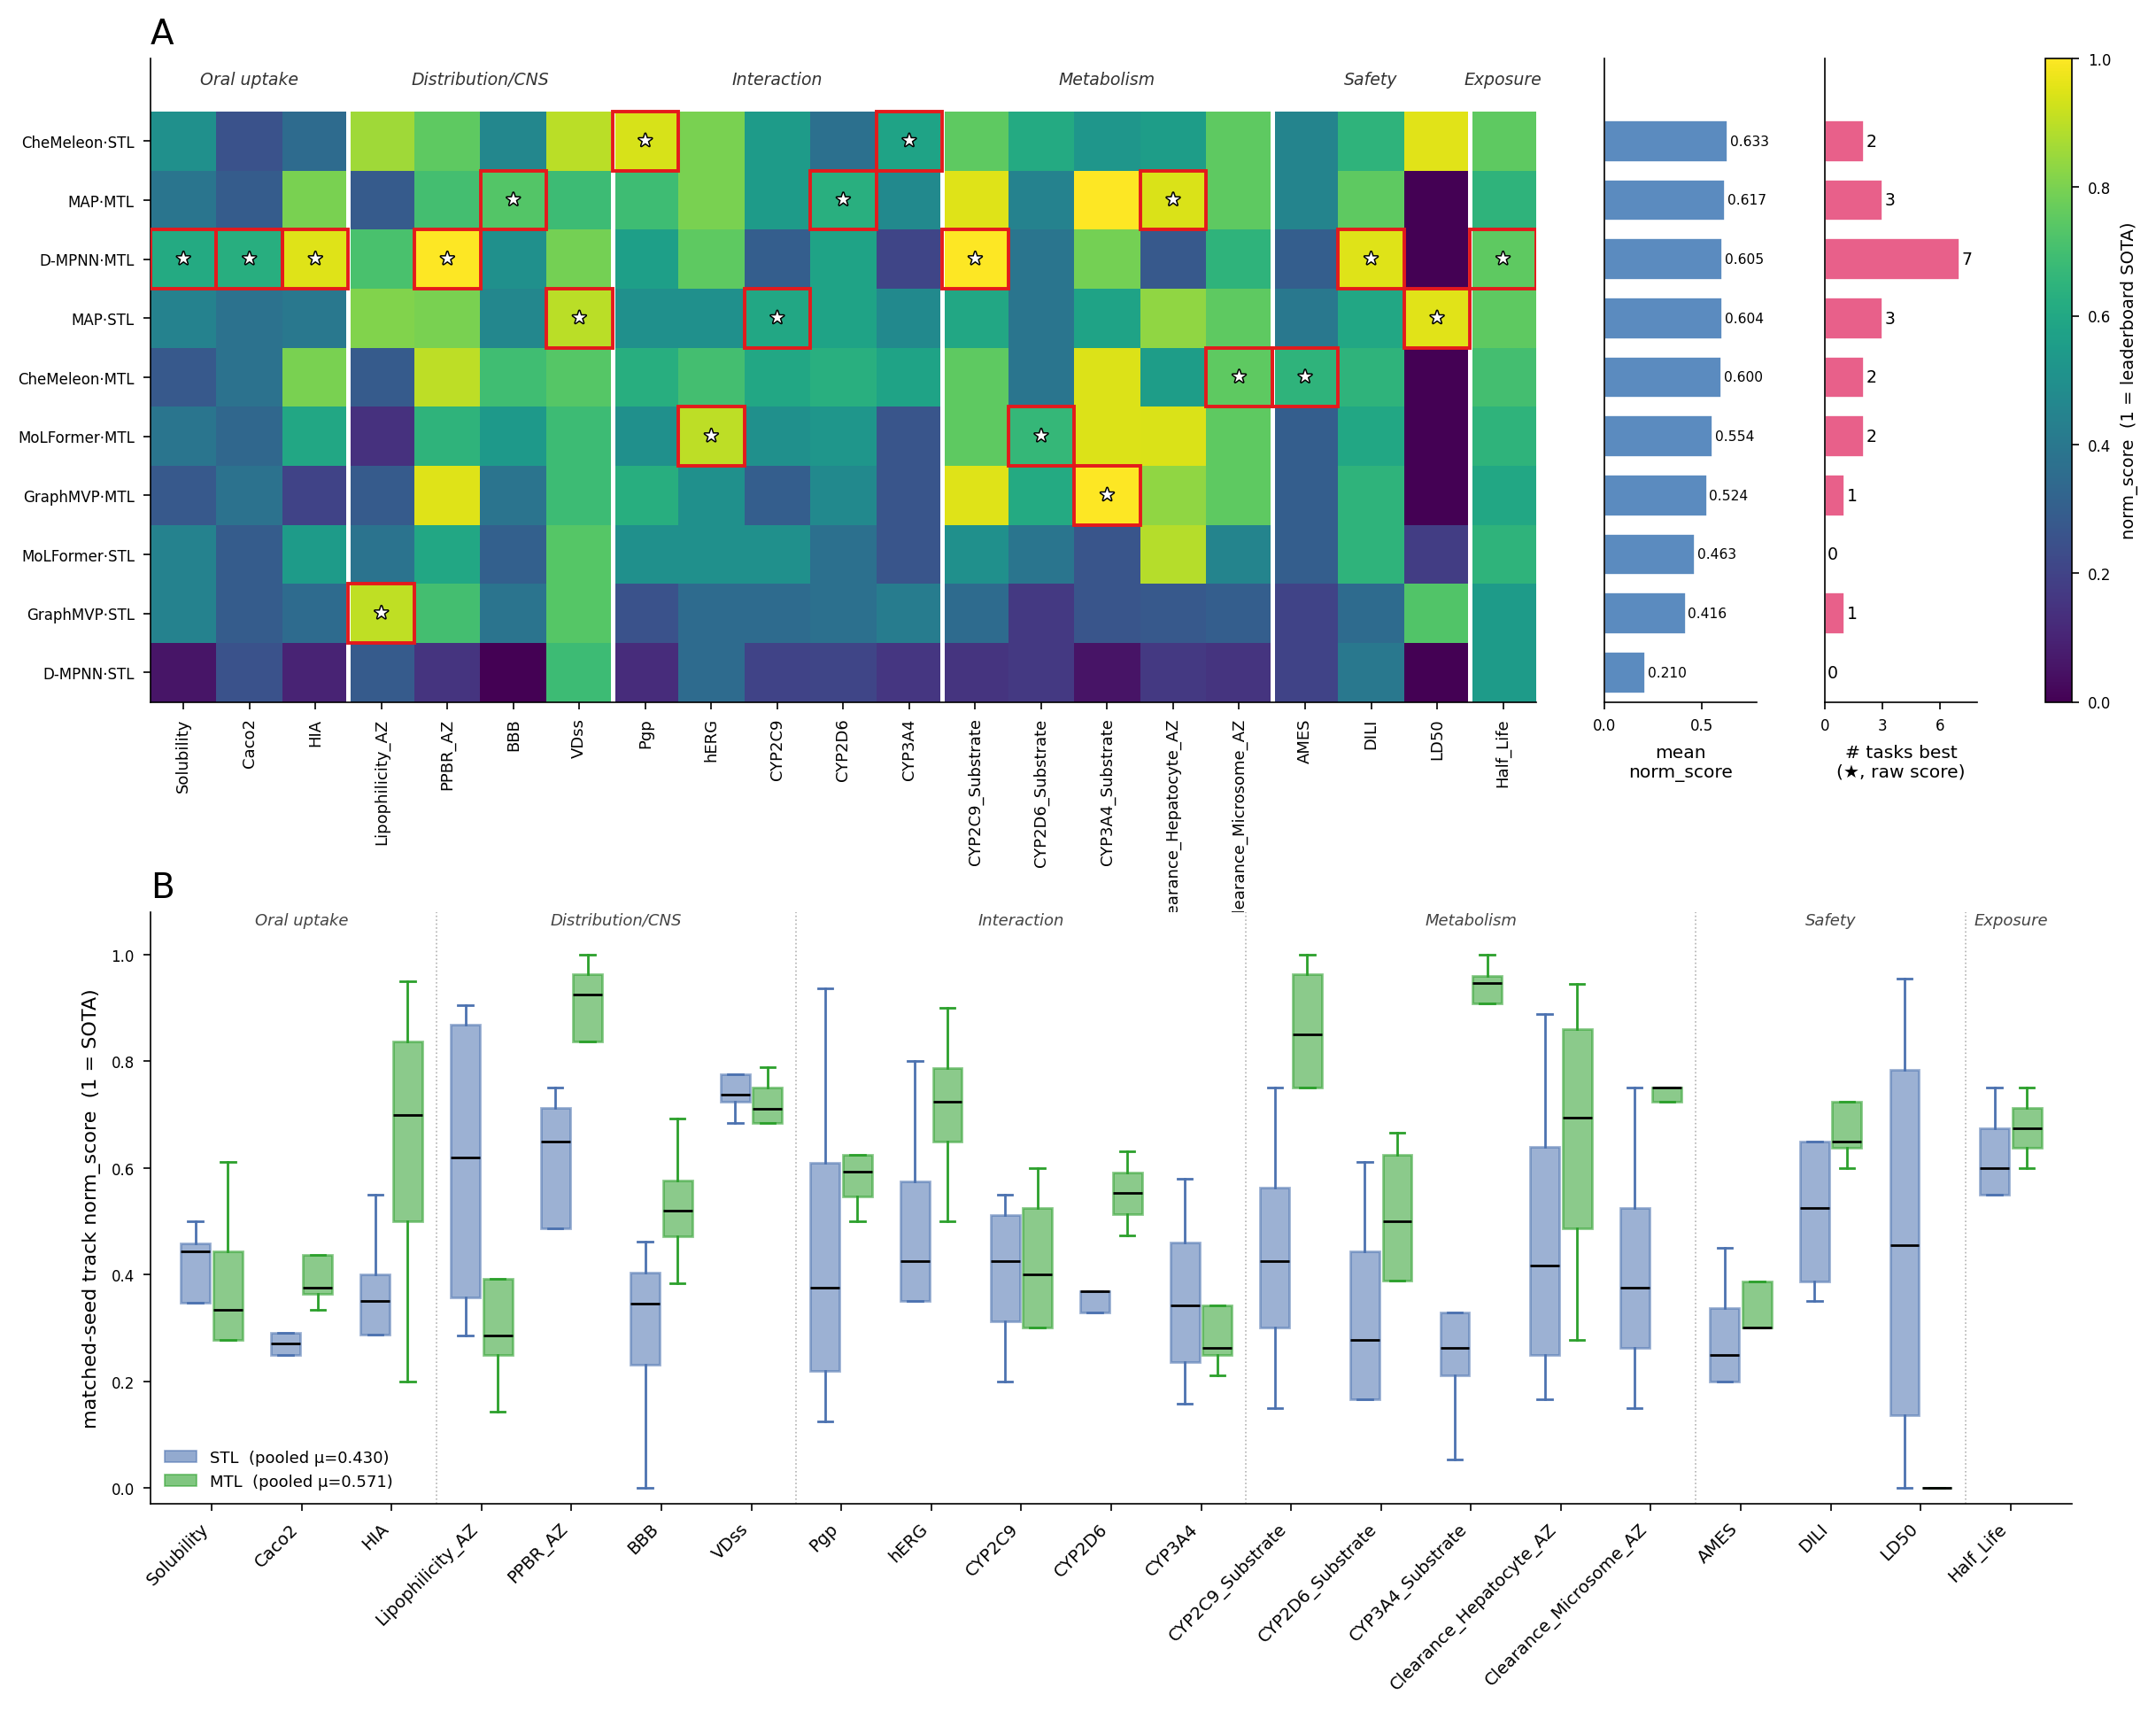

In [7]:
# === figure1.png (within-seed / matched-seed track basis) ===
import json, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch, Rectangle
from matplotlib.gridspec import GridSpec
apply_figure_style(sizes=(8,7,6))

# _FIG1 recomputed in setup cell (solo/pertask within-seed basis + groups constant)

PRETTY = {"stl_chemeleon":"CheMeleon\u00b7STL","mtl_chemeleon":"CheMeleon\u00b7MTL",
 "stl_map":"MAP\u00b7STL","mtl_map":"MAP\u00b7MTL","stl_dmpnn":"D-MPNN\u00b7STL","mtl_dmpnn":"D-MPNN\u00b7MTL",
 "stl_graphmvp":"GraphMVP\u00b7STL","mtl_graphmvp":"GraphMVP\u00b7MTL","stl_molformer":"MoLFormer\u00b7STL","mtl_molformer":"MoLFormer\u00b7MTL"}
SHORT = {"Solubility_AqSolDB":"Solubility","Caco2_Wang":"Caco2","HIA_Hou":"HIA","Lipophilicity_AstraZeneca":"Lipophilicity_AZ",
 "PPBR_AZ":"PPBR_AZ","BBB_Martins":"BBB","VDss_Lombardo":"VDss","Pgp_Broccatelli":"Pgp","hERG":"hERG",
 "CYP2C9_Veith":"CYP2C9","CYP2D6_Veith":"CYP2D6","CYP3A4_Veith":"CYP3A4","CYP2C9_Substrate_CarbonMangels":"CYP2C9_Substrate",
 "CYP2D6_Substrate_CarbonMangels":"CYP2D6_Substrate","CYP3A4_Substrate_CarbonMangels":"CYP3A4_Substrate",
 "Clearance_Hepatocyte_AZ":"Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ":"Clearance_Microsome_AZ",
 "AMES":"AMES","DILI":"DILI","LD50_Zhu":"LD50","Half_Life_Obach":"Half_Life"}
FINAL5 = {"mtl_dmpnn","mtl_molformer","stl_chemeleon","stl_graphmvp","stl_map"}
STLc,MTLc = "#4c72b0","#2ca02c"
GROUPS = _FIG1["groups"]

# ---- panel a data: 10-model x 21-task per-task norm_score heatmap ----
solo = _FIG1["solo"]; pt = {e["task"]:e for e in _FIG1["pertask"]}
row_models = [m for m,_ in sorted(solo.items(), key=lambda kv:-kv[1])]  # rows: descending mean solo norm
task_order = [t for g in GROUPS.values() for t in g]                    # cols: mechanism-group order
Mmat = np.array([[pt[t][m] for t in task_order] for m in row_models])
# Star / red box = per-task BEST model by RAW score (direction-aware: mae -> min, else max),
# NOT by norm_score. norm_score is a step function (fraction of leaderboard beaten), so many
# models land on the same norm rung and would tie spuriously; raw score gives one true winner
# per task (matches the Figure 5b raw-score ranking). Heatmap colour still shows norm_score.
_rawpt = {m: pertask_raw([m], True) for m in row_models}                # within-seed raw per task
best_mask = np.zeros_like(Mmat, dtype=bool)                            # best per task (col), raw-score
for j, t in enumerate(task_order):
    met = REG[t]["metric"]
    vals = np.array([_rawpt[m][t] for m in row_models])
    tgt = vals.min() if met == "mae" else vals.max()
    best_mask[np.abs(vals - tgt) <= 1e-9, j] = True
avg_norm  = np.array([solo[m] for m in row_models])                    # per-model mean norm_score
ntask_best= best_mask.sum(axis=1)                                      # per-model # tasks best
n_rows, n_cols = Mmat.shape

# ---- panel b data: per-task STL vs MTL norm (boxplots, no raw points) ----
bb = ["dmpnn","chemeleon","graphmvp","molformer"]
stl_by_task = [[pt[t]["stl_"+b] for b in bb] for t in task_order]
mtl_by_task = [[pt[t]["mtl_"+b] for b in bb] for t in task_order]
stl_all = np.array([v for r in stl_by_task for v in r]); mtl_all = np.array([v for r in mtl_by_task for v in r])

plt.close('all')
fig = plt.figure(figsize=(14.0,10.6))
outer = GridSpec(2,1,height_ratios=[1.0,0.92],hspace=0.34)
# --- panel a: heatmap + two side bars ---
gsA = outer[0].subgridspec(1,4,width_ratios=[n_cols,2.3,2.3,0.4],wspace=0.16)
axH = fig.add_subplot(gsA[0]); axV = fig.add_subplot(gsA[1]); axN = fig.add_subplot(gsA[2]); axC = fig.add_subplot(gsA[3])
star_pe=[pe.withStroke(linewidth=1.1, foreground="black")]

im = axH.imshow(Mmat, aspect="auto", cmap="viridis", vmin=0, vmax=1)
axH.set_yticks(range(n_rows)); axH.set_yticklabels([PRETTY[m] for m in row_models])
axH.set_xticks(range(n_cols)); axH.set_xticklabels([SHORT[t] for t in task_order], rotation=90, fontsize=6.5)
for i in range(n_rows):
    for j in range(n_cols):
        if best_mask[i,j]:
            axH.add_patch(Rectangle((j-0.5,i-0.5),1,1,fill=False,edgecolor="#e41a1c",lw=1.4,zorder=4))
            axH.text(j,i,"\u2605",ha="center",va="center",color="white",fontsize=6.8,zorder=5,path_effects=star_pe)
acc=0
for gname,tasks in GROUPS.items():
    st,en=acc,acc+len(tasks); acc=en
    if st>0: axH.axvline(st-0.5,color="white",lw=1.8)
    axH.text((st+en-1)/2,-0.9,gname,ha="center",va="bottom",fontsize=6.8,style="italic",color="#333")
axH.set_ylim(n_rows-0.5,-1.4)
axH.set_title("A", fontsize=14)
# axH.set_title("a  No single model dominates all tasks \u2014 per-task norm_score (21 TDC ADMET tasks)",
#               loc="left",fontweight="bold",fontsize=9.5)

y=np.arange(n_rows)
axV.barh(y, avg_norm, color="#5b8bbf", height=0.7, edgecolor="white")
for yi,v in zip(y,avg_norm): axV.text(v+0.012,yi,f"{v:.3f}",va="center",ha="left",fontsize=5.6)
axV.set_ylim(n_rows-0.5,-1.4); axV.set_yticks([]); axV.set_xlim(0,0.78); axV.set_xticks([0,0.5])
axV.set_xlabel("mean\nnorm_score", fontsize=7.3)

axN.barh(y, ntask_best, color="#e8608a", height=0.7, edgecolor="white")
for yi,v in zip(y,ntask_best): axN.text(v+0.12,yi,str(int(v)),va="center",ha="left",fontsize=6.8)
axN.set_ylim(n_rows-0.5,-1.4); axN.set_yticks([]); axN.set_xlim(0,ntask_best.max()+0.9); axN.set_xticks([0,3,6])
axN.set_xlabel("# tasks best\n(\u2605, raw score)", fontsize=7.3)
cb=fig.colorbar(im, cax=axC)
cb.set_label("norm_score  (1 = leaderboard SOTA)", fontsize=7)

# --- panel b: MTL vs STL per-task boxplots (no raw points) ---
axB = fig.add_subplot(outer[1])
n=len(task_order); xpos=np.arange(n); w=0.36
bpS=axB.boxplot(stl_by_task,positions=xpos-w/2,widths=w*0.9,patch_artist=True,showfliers=False,medianprops=dict(color="black",lw=1))
bpM=axB.boxplot(mtl_by_task,positions=xpos+w/2,widths=w*0.9,patch_artist=True,showfliers=False,medianprops=dict(color="black",lw=1))
for b in bpS["boxes"]: b.set(facecolor=STLc,alpha=0.55,edgecolor=STLc)
for b in bpM["boxes"]: b.set(facecolor=MTLc,alpha=0.55,edgecolor=MTLc)
for bp,cc in [(bpS,STLc),(bpM,MTLc)]:
    for wk in bp["whiskers"]: wk.set(color=cc)
    for cap in bp["caps"]: cap.set(color=cc)
axB.set_xticks(xpos); axB.set_xticklabels([SHORT[t] for t in task_order],rotation=45,ha="right",fontsize=7)
axB.set_ylabel("matched-seed track norm_score  (1 = SOTA)"); axB.set_ylim(-0.03,1.08)
axB.set_title("B", fontsize=14)
# axB.set_title("b  MTL vs STL: neither wins every task",loc="left",fontweight="bold",fontsize=9)
axB.legend(handles=[Patch(color=STLc,alpha=0.6,label=f"STL  (pooled \u03bc={stl_all.mean():.3f})"),Patch(color=MTLc,alpha=0.6,label=f"MTL  (pooled \u03bc={mtl_all.mean():.3f})")],loc="lower left",fontsize=6.5,frameon=False)
acc=0
for gname,tasks in GROUPS.items():
    st,en=acc,acc+len(tasks); acc=en
    if st>0: axB.axvline(st-0.5,color="grey",ls=":",lw=0.6,alpha=0.6)
    axB.text((st+en-1)/2,1.05,gname,ha="center",va="bottom",fontsize=6.5,style="italic",color="#444")
fig.savefig(os.path.join(OUTDIR,"figure1.png"), dpi=300, bbox_inches="tight")
plt.show()


*Fig. 1 Complementarity across the 10 base models. (a) Per-task matched-seed held-out-test norm_score (1 = leaderboard SOTA) for all 10 base models—the four backbones (D-MPNN, CheMeleon, GraphMVP, MoLFormer) and the joint-fusion MAP model, each under STL and MTL—across the 21 TDC ADMET tasks, grouped by mechanism (Table 2). Cell colour encodes norm_score, and the first right-hand bar ("mean norm_score") gives each model's average norm_score over the 21 tasks, so that rows are ordered from the strongest overall model at the top to the weakest at the bottom. Because norm_score is a discrete leaderboard-rank score on which several models often share the same value, the per-task winner is instead determined on the underlying raw metric (with direction handled appropriately): on each task the single best-performing model is outlined in red and marked with an asterisk, and the second right-hand bar ("# tasks best") counts, for each model, the number of tasks on which it is that winner. MAP is shown here because it is itself a candidate late-fusion member (Section 2.4), so the panel displays the full candidate pool from which the 1,023 subsets of Section 3.2 are formed. (b) Per-task matched-seed norm_score distributions for MTL versus STL, restricted to the four backbones (same matched-seed basis as panel a) and grouped by ADMET mechanism. MAP is excluded from this panel because it aggregates three of the backbones, so its STL/MTL contrast would be confounded by the fusion module and its inclusion would double-count those encoders; the pooled averages quoted in the text (μ = 0.571 for MTL vs 0.430 for STL) are computed over the four backbones only.*


## Table S1. Per-task held-out-test performance for all 10 base models

The four backbones (D-MPNN, CheMeleon, GraphMVP, MoLFormer) and the joint-fusion MAP model, each under MTL and STL. Each cell: raw metric (rank-normalized score). Norm_score 1 = leaderboard SOTA. MAP is a feature-level joint fusion over three of the backbones (Section 2.3) and is included here because it is one of the 10 candidates from which the 1,023 subsets are formed.

In [8]:
# Table S1
_t3_by_ds = {e["dataset"]: e for e in _PT["t3"]}
rows=[]
for e in _PT["t1"]:
    m = _t3_by_ds[e["dataset"]]
    base_cells = [cell(e[b]) for b in BACKBONES]
    map_cells  = [cell(m["mtl_map"]), cell(m["stl_map"])]
    rows.append([e["group"], e["dataset"], e["n"], e["metric"]] + base_cells + map_cells)
cols=["Group","Dataset","N","Metric"] + [BB_LABEL[b] for b in BACKBONES] + ["MAP MTL","MAP STL"]
S1=pd.DataFrame(rows, columns=cols)
S1 = S1[['Group', 'Dataset', 'N', 'Metric',
 'D-MPNN MTL', 'CheMeleon MTL', 'GraphMVP MTL', 'MoLFormer MTL', 'MAP MTL',
 'D-MPNN STL', 'CheMeleon STL', 'GraphMVP STL', 'MoLFormer STL', 'MAP STL']]
register("tableS1_per_backbone_pertask", S1)
# verify against manuscript SI (Caco2_Wang, D-MPNN MTL = 0.322 (0.62)); MAP columns match leaderboard basis
assert S1.iloc[0]["Dataset"]=="Caco2_Wang" and S1.iloc[0]["D-MPNN MTL"]=="0.322 (0.625)", S1.iloc[0].to_dict()
assert S1.iloc[0]["MAP MTL"]=="0.443 (0.292)", S1.iloc[0]["MAP MTL"]
assert len(S1)==21 and S1.shape[1]==4+8+2
print("S1 OK", S1.shape); S1.head(3)


S1 OK (21, 14)


,Group,Dataset,N,Metric,D-MPNN MTL,CheMeleon MTL,GraphMVP MTL,MoLFormer MTL,MAP MTL,D-MPNN STL,CheMeleon STL,GraphMVP STL,MoLFormer STL,MAP STL
0,oral_uptake,Caco2_Wang,910,mae,0.322 (0.625),0.36 (0.375),0.392 (0.375),0.401 (0.333),0.443 (0.292),0.463 (0.250),0.461 (0.250),0.431 (0.292),0.419 (0.292),0.37 (0.375)
1,oral_uptake,HIA_Hou,578,auroc,0.991 (0.950),0.988 (0.800),0.929 (0.200),0.981 (0.600),0.987 (0.800),0.851 (0.100),0.958 (0.350),0.953 (0.350),0.977 (0.550),0.97 (0.400)
2,oral_uptake,Solubility_AqSolDB,9982,mae,0.822 (0.611),0.95 (0.278),0.983 (0.278),0.916 (0.389),0.931 (0.389),1.102 (0.056),0.828 (0.500),0.897 (0.444),0.868 (0.444),0.844 (0.444)


# 3.2 Prediction-level late fusion outperforms feature-level joint fusion

## Fig. 2 The joint-fusion model (MAP) is benchmarked against single-backbone reference points and against prediction-level late fusion.

figure2.png written (3-panel). Late-3 within: STL=0.7233 MTL=0.7528 | MAP within: STL=0.6045 MTL=0.6173 | Tetra=0.8540


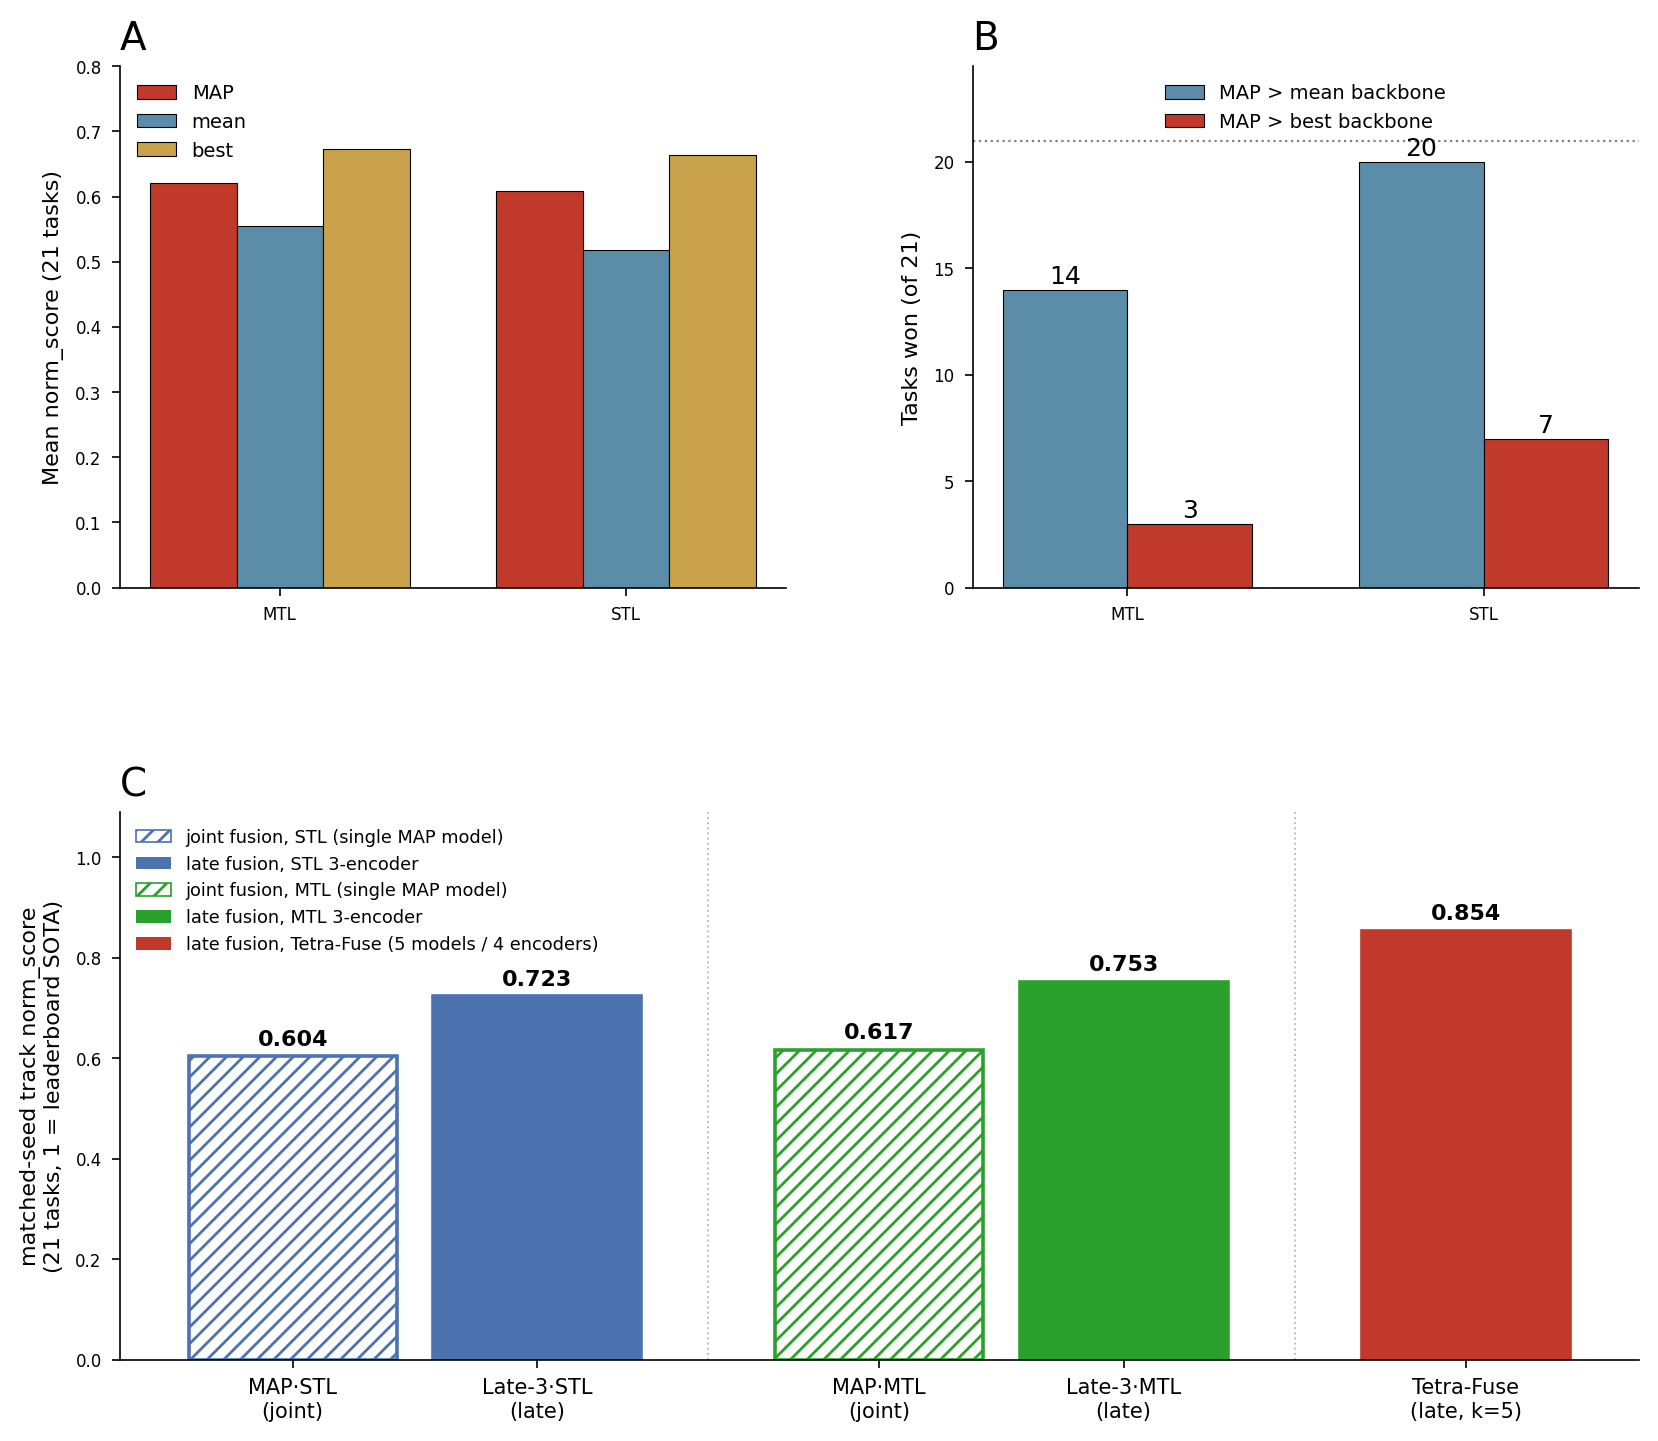

In [9]:
# === figure2.png (representation-level fusion: aggregation + fusion-level comparison) ===
import numpy as np, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
apply_figure_style(sizes=(8,7,6))

magg = _GT["map_agg"]        # {'mtl':{...}, 'stl':{...}}
RED = "#c0392b"

# ---- panel c data: matched-seed (within-seed) norm, recomputed like Tetra-Fuse ----
# MAP is a single joint-fusion model -> its within norm == solo within norm of {stl,mtl}_map
map_stl = pertask_norm(["stl_map"], True); map_stl = float(np.mean(list(map_stl.values())))
map_mtl = pertask_norm(["mtl_map"], True); map_mtl = float(np.mean(list(map_mtl.values())))
# Late-3 = same 3 encoders as MAP (chemeleon, graphmvp, molformer), prediction-level uniform mean
late3_stl = float(np.mean(list(pertask_norm(["stl_chemeleon","stl_graphmvp","stl_molformer"], True).values())))
late3_mtl = float(np.mean(list(pertask_norm(["mtl_chemeleon","mtl_graphmvp","mtl_molformer"], True).values())))
# Tetra-Fuse matched-seed = final ensemble within norm (== Table 3 within, 0.854)
tetra = float(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]))

fig = plt.figure(figsize=(9.8, 8.4))
gs = GridSpec(2, 2, height_ratios=[1.0, 1.05], hspace=0.42, wspace=0.28)
axA = fig.add_subplot(gs[0,0]); axB = fig.add_subplot(gs[0,1]); axC = fig.add_subplot(gs[1,:])

# (a) mean norm_score for map / mean / max, MTL & STL
groups = ["mtl","stl"]; aggs=["map","mean","best"]
x = np.arange(len(groups)); w=0.25
aggcol={"map":RED,"mean":"#5b8ca8","best":"#c9a24b"}
for i,a in enumerate(aggs):
    axA.bar(x+(i-1)*w, [magg[g][a] for g in groups], w, label=a.upper() if a=="map" else a,
            color=aggcol[a], edgecolor="black", linewidth=0.4)
axA.set_xticks(x); axA.set_xticklabels(["MTL","STL"]); axA.set_ylim(0, 0.8)
axA.set_ylabel("Mean norm_score (21 tasks)")
axA.set_title("A", fontsize=14)
# axA.set_title("a  MAP vs single-backbone reference points", loc="left", fontweight="bold")
axA.legend(frameon=False)

# (b) win-counts: MAP > mean vs MAP > per-task-best, on the RAW-score matched-seed basis
# (panel a keeps norm_score; panel b counts direction-aware raw wins so norm-step ties do not
# distort the count). Per task: MAP raw (within-seed mean) vs the 3 shared backbones' per-seed
# mean / best raw, averaged over seeds (matched-seed track throughout).
labels=["MTL","STL"]
_B3=["chemeleon","graphmvp","molformer"]; _TKb=[t for t in REG if t!="Bioavailability_Ma"]
def _agg_raw(train, task, how):
    met=REG[task]["metric"]; per=[]
    for seed in sorted(PRED[f"{train}_{_B3[0]}"].seed.unique()):
        sc=[]
        for bb in _B3:
            d=PRED[f"{train}_{bb}"]; t=d[(d.task==task)&(d.split=="test")&(d.seed==seed)].dropna(subset=["y_true"])
            sc.append(metric(met,t.y_true,t.y_pred))
        per.append(np.mean(sc) if how=="mean" else (min(sc) if met=="mae" else max(sc)))
    return float(np.mean(per))
def _mapwins(train, how):
    n=0
    for t in _TKb:
        met=REG[t]["metric"]; mp=pertask_raw([f"{train}_map"], True)[t]; ref=_agg_raw(train,t,how)
        if (mp<ref) if met=="mae" else (mp>ref): n+=1
    return n
mgt_mean=[_mapwins(g,"mean") for g in groups]
mgt_max =[_mapwins(g,"best") for g in groups]
x2=np.arange(len(labels)); w2=0.35
axB.bar(x2-w2/2, mgt_mean, w2, label="MAP > mean backbone", color="#5b8ca8", edgecolor="black", linewidth=0.4)
axB.bar(x2+w2/2, mgt_max,  w2, label="MAP > best backbone", color=RED, edgecolor="black", linewidth=0.4)
axB.axhline(21, ls=":", color="grey", lw=0.8)
for xx,v in zip(x2-w2/2, mgt_mean): axB.text(xx,v+0.3,str(v),ha="center",fontsize=9)
for xx,v in zip(x2+w2/2, mgt_max):  axB.text(xx,v+0.3,str(v),ha="center",fontsize=9)
axB.set_xticks(x2); axB.set_xticklabels(labels); axB.set_ylim(0,24.5)
axB.set_ylabel("Tasks won (of 21)")
axB.set_title("B", fontsize=14)
# axB.set_title("b  MAP raises the floor, rarely tops the best", loc="left", fontweight="bold")
axB.legend(frameon=False, loc="upper center")

# (c) fusion level, same encoders: joint (MAP, hatched) vs late (uniform-mean, solid), then Tetra-Fuse
STLc="#4c72b0"; MTLc="#2ca02c"; TFc=RED
xc=[0,1, 2.4,3.4, 4.8]
vc=[map_stl, late3_stl, map_mtl, late3_mtl, tetra]
lblc=["MAP\u00b7STL\n(joint)","Late-3\u00b7STL\n(late)","MAP\u00b7MTL\n(joint)","Late-3\u00b7MTL\n(late)","Tetra-Fuse\n(late, k=5)"]
# colour = paradigm (STL blue / MTL green / Tetra red); fill = fusion level (joint hatched, late solid)
specs=[(STLc,"////"),(STLc,None),(MTLc,"////"),(MTLc,None),(TFc,None)]
for xi,vi,(c,h) in zip(xc,vc,specs):
    axC.bar(xi,vi,width=0.85,color=(c if h is None else "white"),edgecolor=c,linewidth=1.3,hatch=h)
    axC.text(xi,vi+0.014,f"{vi:.3f}",ha="center",va="bottom",fontsize=8,fontweight="bold")
axC.axvline(1.7,color="grey",ls=":",lw=0.7,alpha=0.5); axC.axvline(4.1,color="grey",ls=":",lw=0.7,alpha=0.5)
axC.set_xticks(xc); axC.set_xticklabels(lblc,fontsize=7.5)
axC.set_ylabel("matched-seed track norm_score\n(21 tasks, 1 = leaderboard SOTA)",fontsize=8)
axC.set_ylim(0,1.09)
axC.set_title("C", fontsize=14)
# axC.set_title("c  Fusion level alone (same 3 encoders), then ensemble expansion",
#               loc="left",fontweight="bold",fontsize=9.3)
axC.legend(handles=[
    Patch(facecolor="white",edgecolor=STLc,hatch="////",label="joint fusion, STL (single MAP model)"),
    Patch(facecolor=STLc,label="late fusion, STL 3-encoder"),
    Patch(facecolor="white",edgecolor=MTLc,hatch="////",label="joint fusion, MTL (single MAP model)"),
    Patch(facecolor=MTLc,label="late fusion, MTL 3-encoder"),
    Patch(facecolor=TFc,label="late fusion, Tetra-Fuse (5 models / 4 encoders)")],
    loc="upper left",fontsize=6.4,frameon=False)

fig.savefig(os.path.join(OUTDIR,"figure2.png"), dpi=300, bbox_inches="tight")
# plt.close(fig)
print(f"figure2.png written (3-panel). Late-3 within: STL={late3_stl:.4f} MTL={late3_mtl:.4f} | "
      f"MAP within: STL={map_stl:.4f} MTL={map_mtl:.4f} | Tetra={tetra:.4f}")
plt.show()



*Fig. 2 The joint-fusion model (MAP) is benchmarked against single-backbone reference points and against prediction-level late fusion. (a) Mean norm_score over 21 tasks for MAP, for the mean of the three fused backbones' per-task scores, and for the best backbone on each task, under MTL and STL; MAP exceeds the mean backbone but not the per-task best. (b) Per-task win counts on the raw metric (direction handled appropriately): MAP beats the mean of its three backbones on 14/21 tasks (MTL) and 20/21 (STL), but beats the single best backbone on only 3/21 (MTL) and 7/21 (STL). The per-task best is an oracle reference—identifying it requires the test labels—and is reported only as an upper bound. (c) Matched-seed comparison isolating fusion level. Within each learning paradigm, MAP (feature-level, hatched) is compared with a prediction-level uniform mean over exactly the same three backbones (Late-3, solid), holding encoders, paradigm and seeds fixed; late fusion is higher in both (+0.119 STL, +0.136 MTL). Tetra-Fuse (right) additionally draws on a fourth encoder (the from-scratch D-MPNN, excluded from joint fusion, Section 2.3) and combines five models, so its further gain over Late-3·MTL reflects ensemble expansion rather than fusion level alone; MAP·STL is itself one of its five members. Late-3 is composition-matched to MAP rather than validation-selected, and is reported as a post-hoc analysis (Section 2.4). All values are held-out-test, matched-seed. Full per-task values in Supplementary Table S2; heatmap in Supplementary Fig. S1.*

## Fig. S1 Detailed per-task performance of feature-level joint fusion (MAP) compared to base backbones.

The heatmap displays the rank-based normalized scores (norm_score) across all 21 evaluable ADMET tasks. For both Single-Task Learning (STL) and Multi-Task Learning (MTL) paradigms, the performance of the joint-fusion model (MAP) is compared against two references: (1) the Mean score of its three constituent backbones (CheMeleon, MoLFormer, and GraphMVP), and (2) the Best single backbone (Oracle) for each specific task. This figure provides the fine-grained, per-task breakdown corresponding to the aggregated results presented in Fig. 2a.

figureS1.png written (SI heatmap, landscape)


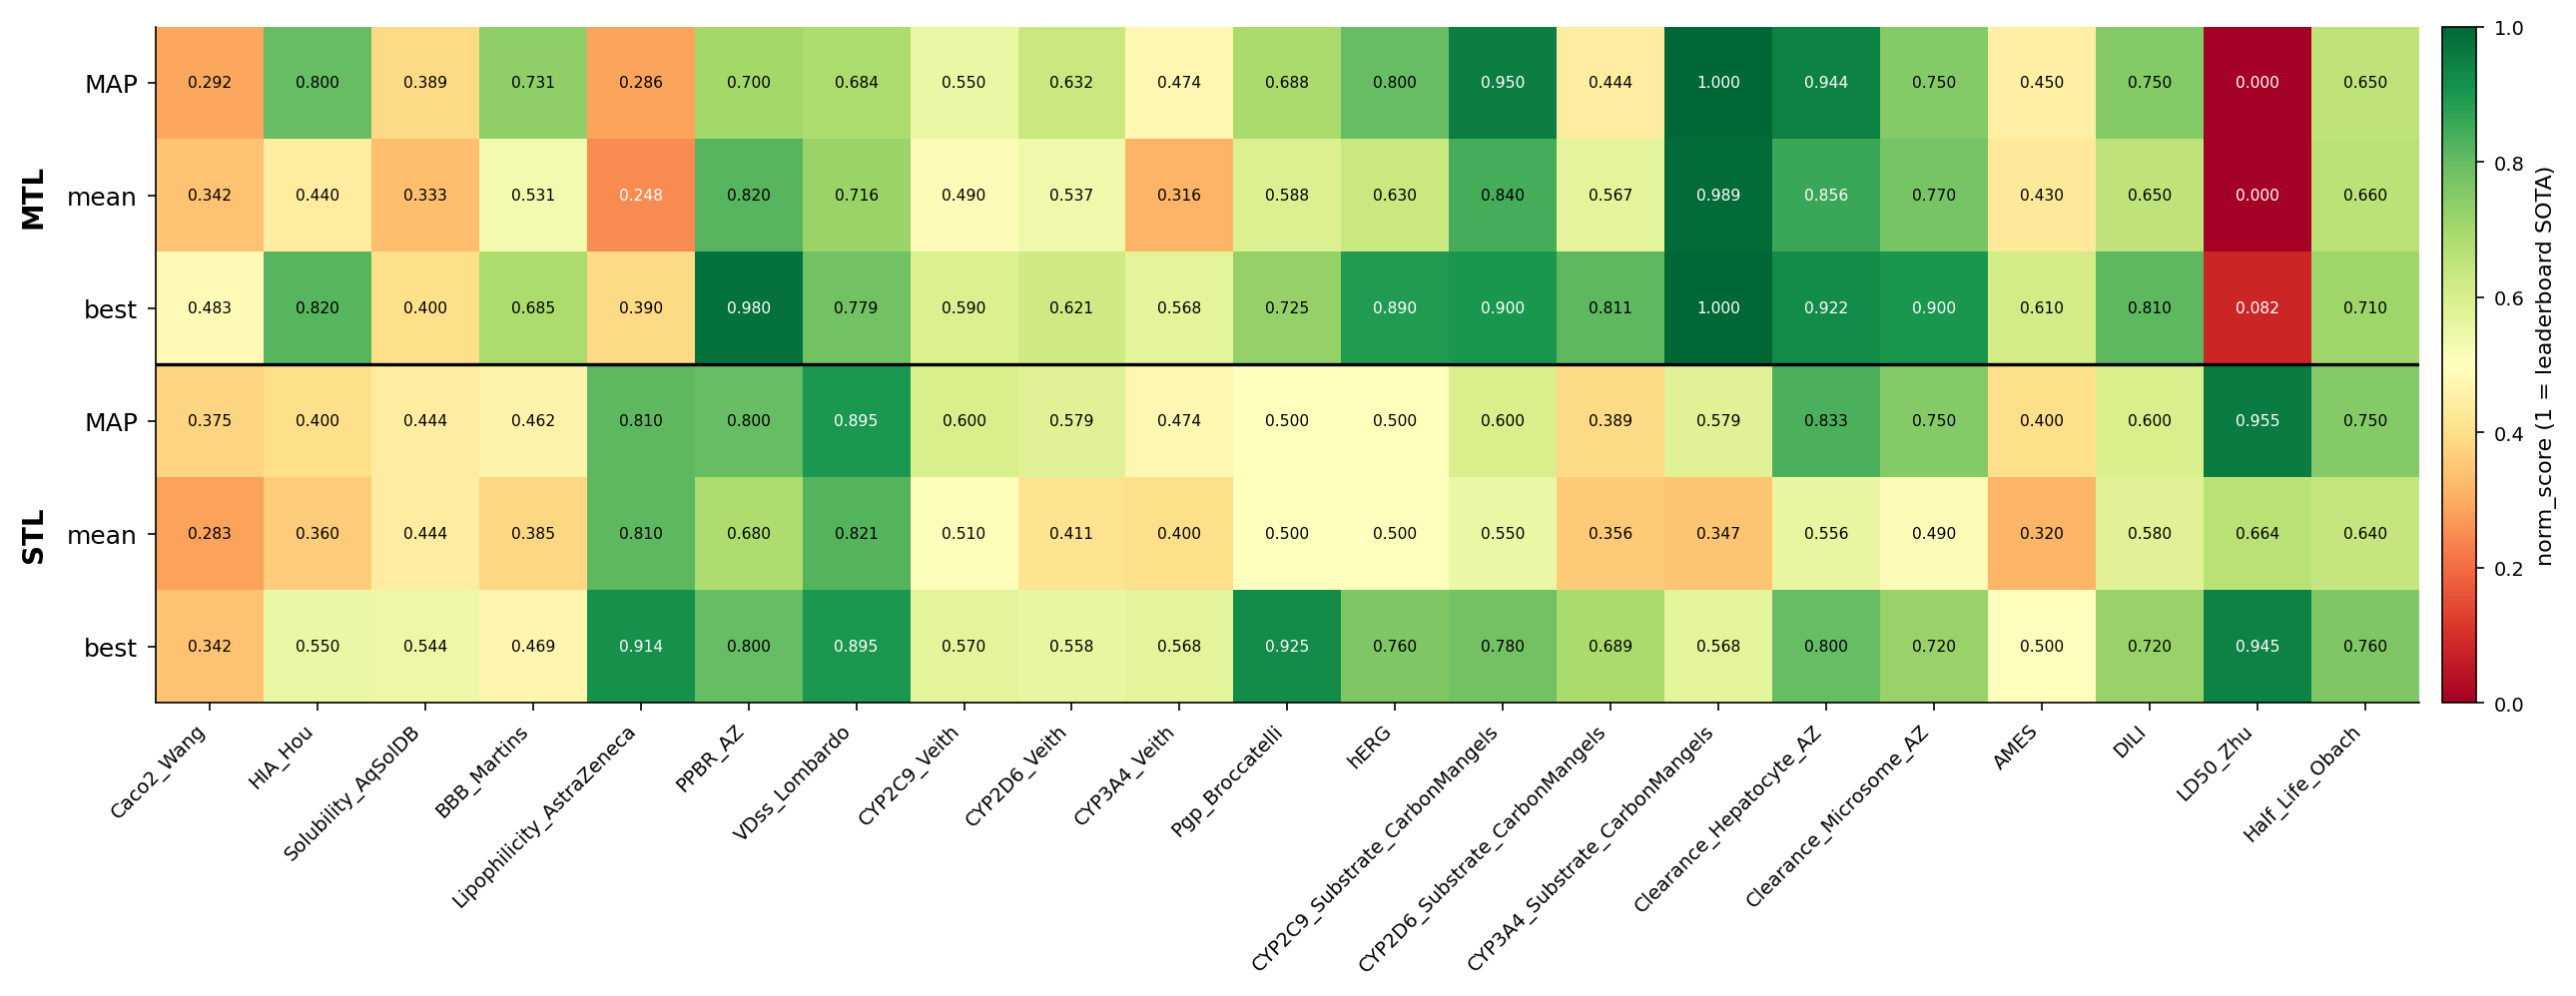

In [10]:
# === figureS1.png (Supplementary: per-task norm_score by aggregation rule) ===
# Landscape orientation: aggregation rules on the y-axis, the 21 tasks along the x-axis
# (transpose of the portrait version; identical values).
import numpy as np, matplotlib.pyplot as plt
apply_figure_style(sizes=(9,8,7))

PT = _PT
t3=PT["t3"]
tasks3=[e["dataset"] for e in t3]
cols3=["mtl_map","mtl_mean","mtl_best","stl_map","stl_mean","stl_best"]
collab=["MAP","mean","best","MAP","mean","best"]
M=np.array([[e[c]["norm"] for c in cols3] for e in t3])  # tasks x 6

fig, axH = plt.subplots(figsize=(15.0, 4.4))
im=axH.imshow(M.T, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1)   # 6 x tasks (landscape)
axH.set_yticks(range(6)); axH.set_yticklabels(collab, fontsize=9)
axH.set_xticks(range(len(tasks3))); axH.set_xticklabels(tasks3, rotation=45, ha="right", fontsize=7)
axH.axhline(2.5, color="black", lw=1.2)                            # MTL (rows 0-2) | STL (rows 3-5)
axH.text(-1.5, 1.0, "MTL", va="center", ha="right", fontweight="bold", fontsize=10, rotation=90)
axH.text(-1.5, 4.0, "STL", va="center", ha="right", fontweight="bold", fontsize=10, rotation=90)
for c in range(len(tasks3)):
    for r in range(6):
        v=M[c,r]
        axH.text(c,r,f"{v:.3f}", ha="center", va="center", fontsize=5.6,
                 color="black" if 0.25<v<0.85 else "white")
# axH.set_title("Per-task held-out test norm_score by aggregation rule", loc="center", fontweight="bold", fontsize=10, pad=10)
cbar=fig.colorbar(im, ax=axH, fraction=0.015, pad=0.01)
cbar.set_label("norm_score (1 = leaderboard SOTA)", fontsize=8); cbar.ax.tick_params(labelsize=7)
fig.savefig(os.path.join(OUTDIR,"figureS1.png"), dpi=300, bbox_inches="tight")
print("figureS1.png written (SI heatmap, landscape)")


## Table S2. Detailed per-task performance comparison of fusion strategies and the final Tetra-Fuse ensemble.

This table presents the evaluation metrics across all 21 ADMET tasks under both Single-Task Learning (STL) and Multi-Task Learning (MTL) paradigms. It directly compares the 3-backbone feature-level joint fusion (MAP) against the prediction-level late fusion (Late-3) utilizing the exact same three backbones (CheMeleon, MoLFormer, and GraphMVP). For comprehensive benchmarking, the average performance (Mean) and the optimal single-backbone performance (Best) of the three constituent models on each task are also provided. Additionally, the table includes the performance of the final optimal ensemble, Tetra-Fuse, demonstrating its overall superiority over the 3-backbone baselines. This table provides the precise numerical data corresponding to the aggregated results in Fig. 2.

In [11]:
# --- Table S2: representation-level aggregation (MAP vs latent mean vs latent best),
#     plus prediction-level late-fusion columns for direct fusion-level comparison ---
# Late-3 = the same three encoders as MAP (CheMeleon, GraphMVP, MoLFormer) combined by uniform-mean
#   prediction-level fusion (composition-matched to MAP, NOT validation-selected). Tetra-Fuse = the
#   final k=5 ensemble. All three fusion columns are matched-seed (within=True) per-task raw (norm).
AGG=["mtl_map","mtl_mean","mtl_best","stl_map","stl_mean","stl_best"]
AGG_LAB=["MAP MTL","mean MTL","best MTL","MAP STL","mean STL","best STL"]

_LATE3_STL=["stl_chemeleon","stl_graphmvp","stl_molformer"]
_LATE3_MTL=["mtl_chemeleon","mtl_graphmvp","mtl_molformer"]
_TETRA=list(_GT["final_ensemble"])   # k=5
_fuse_specs=[("Late-3 STL",_LATE3_STL),("Late-3 MTL",_LATE3_MTL),("Tetra-Fuse",_TETRA)]
# per-task matched-seed raw + norm for each fusion (computed once here from source predictions)
_fuse_raw ={lab: pertask_raw(ms, True)  for lab,ms in _fuse_specs}
_fuse_norm={lab: pertask_norm(ms, True) for lab,ms in _fuse_specs}
def _fcell(lab, task):
    return f"{_fuse_raw[lab][task]:.3f} ({_fuse_norm[lab][task]:.3f})"

rows=[]
for e in _PT["t3"]:
    tk=e["dataset"]
    r=[e["group"], tk, e["metric"]] + [cell(e[a]) for a in AGG] + [_fcell(lab, tk) for lab,_ in _fuse_specs]
    rows.append(r)
cols=["Group","Dataset","Metric"]+AGG_LAB+["Late-3 STL","Late-3 MTL","Tetra-Fuse"]
S2=pd.DataFrame(rows, columns=cols)
S2 = S2[['Group', 'Dataset', 'Metric',
 'MAP MTL', 'mean MTL', 'best MTL', 'Late-3 MTL', 
 'MAP STL', 'mean STL', 'best STL', 'Late-3 STL', 'Tetra-Fuse']]
register("tableS2_representation_aggregation", S2)
assert S2.iloc[0]["Dataset"]=="Caco2_Wang" and S2.iloc[0]["MAP MTL"]=="0.443 (0.292)", S2.iloc[0].to_dict()
assert len(S2)==21 and {"Late-3 STL","Late-3 MTL","Tetra-Fuse"}.issubset(S2.columns)
print("S2 OK", S2.shape); S2.head(3)


S2 OK (21, 12)


,Group,Dataset,Metric,MAP MTL,mean MTL,best MTL,Late-3 MTL,MAP STL,mean STL,best STL,Late-3 STL,Tetra-Fuse
0,oral_uptake,Caco2_Wang,mae,0.443 (0.292),0.384 (0.342),0.342 (0.483),0.332 (0.542),0.37 (0.375),0.437 (0.283),0.388 (0.342),0.323 (0.625),0.308 (0.667)
1,oral_uptake,HIA_Hou,auroc,0.987 (0.800),0.966 (0.440),0.988 (0.820),0.989 (0.900),0.97 (0.400),0.963 (0.360),0.977 (0.550),0.978 (0.550),0.992 (0.950)
2,oral_uptake,Solubility_AqSolDB,mae,0.931 (0.389),0.95 (0.333),0.911 (0.400),0.872 (0.444),0.844 (0.444),0.864 (0.444),0.828 (0.544),0.787 (0.778),0.775 (0.889)


## Fig. 3 Prediction-level late fusion, ensemble-size sweep.

*Figure 3. Prediction-level late fusion, ensemble-size sweep. (a) Validation norm_score (mean of the top-20 combinations at each size) versus ensemble size k, for the matched-seed and seed-averaged tracks; performance saturates at k = 5 (dashed line). (b) Marginal validation gain from adding the k-th model, shown separately for each track, with the combined (matched + seed-averaged) gain annotated. The combined gain falls from +0.0104 at k = 4→5 to +0.0029 at k = 5→6 — crossing below the ε = 0.01 saturation threshold — and is negative for k = 7–9 (a marginal +0.005 reappears only at k = 10), so k = 5 is taken as the elbow. The corresponding numerical values are provided in Supplementary Table S3.*

saved figure3.png


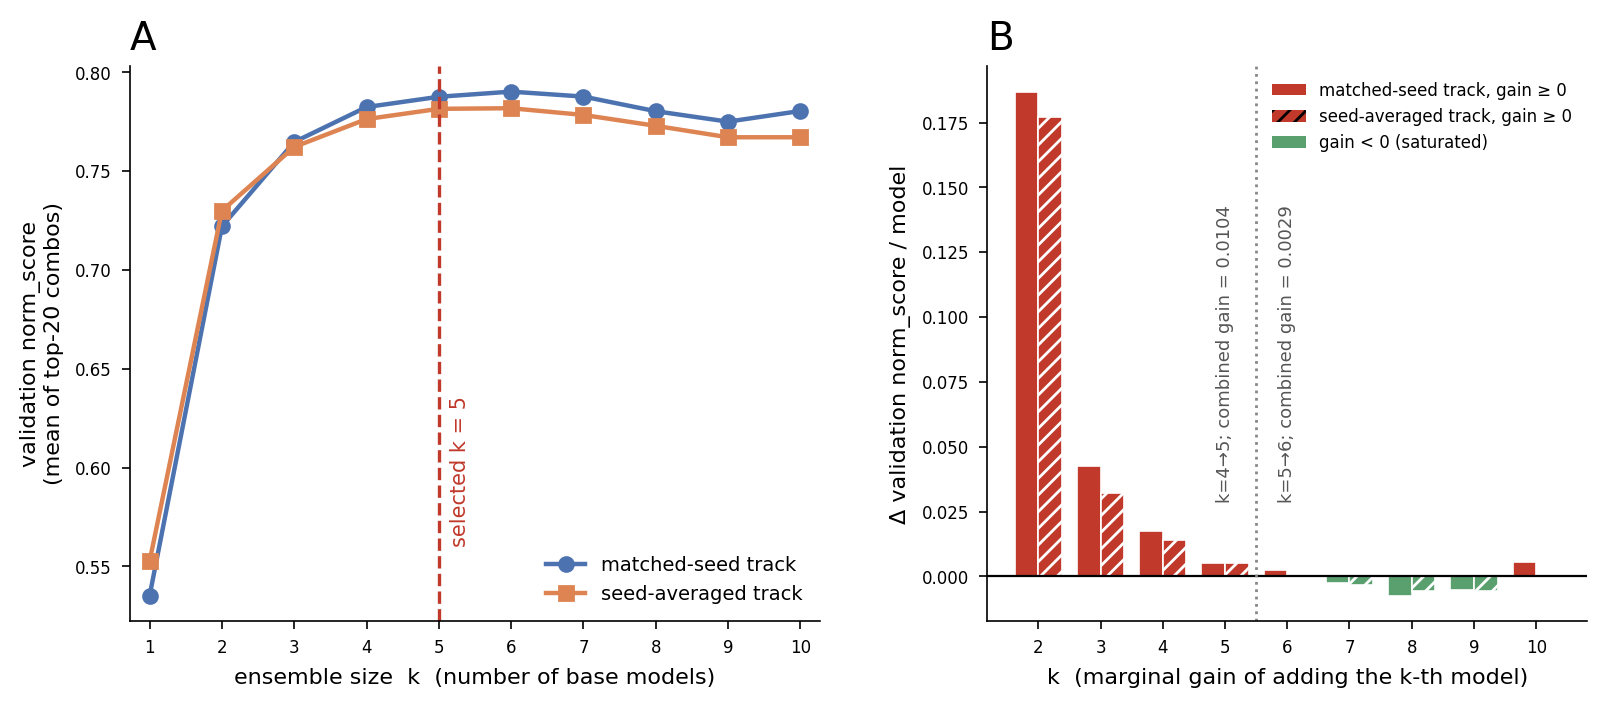

In [12]:
# === figure3.png ===
import json
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# skill:figure-style kernel.py (auto-injected on skill load)
META_GREY = "#888888"




apply_figure_style(sizes=(8, 7, 6))

GT = _GT

ks = GT["ksweep"]
kk = [r[0] for r in ks]
w_top = [r[1] for r in ks]; w_marg = [r[2] for r in ks]
c_top = [r[3] for r in ks]; c_marg = [r[4] for r in ks]

plt.close('all')
fig = plt.figure(figsize=(9.4,3.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1], wspace=0.26)
axL = fig.add_subplot(gs[0, 0]); axR = fig.add_subplot(gs[0, 1])
axL.plot(kk, w_top, "-o", color="#4c72b0", label="matched-seed track", markersize=5, lw=1.6)
axL.plot(kk, c_top, "-s", color="#dd8452", label="seed-averaged track", markersize=5, lw=1.6)
axL.axvline(5, color="#c0392b", ls="--", lw=1.2)
axL.text(5.15, 0.56, "selected k = 5", color="#c0392b", fontsize=7.5, rotation=90, va="bottom")
axL.set_xlabel("ensemble size  k  (number of base models)")
axL.set_ylabel("validation norm_score\n(mean of top-20 combos)")
axL.set_xticks(kk)
axL.set_title("A", fontsize=14)
# axL.set_title("a  Validation performance saturates at k=5", loc="left", fontweight="bold", fontsize=9)
axL.legend(fontsize=7, frameon=False, loc="lower right"); axL.margins(x=0.03)

# Panel B sign-based, separate within & cross bars
xb = np.array(kk[1:])
gw = w_marg[1:]; gc = c_marg[1:]
bw = 0.38
def sc(g): return "#c0392b" if g >= 0 else "#5aa06f"
axR.bar(xb - bw/2, gw, width=bw, color=[sc(g) for g in gw], edgecolor="white")
axR.bar(xb + bw/2, gc, width=bw, color=[sc(g) for g in gc], edgecolor="white", hatch="////")
axR.axhline(0, color="black", lw=0.8)
axR.axvline(5.5, color="#888", ls=":", lw=1)
axR.text(5, 0.03, f"k=4→5; combined gain = {[r[2] for r in ks][4] + [r[4] for r in ks][4]}", fontsize=6.5, rotation=90, color="#555", ha="center")
axR.text(6, 0.03, f"k=5→6; combined gain = {[r[2] for r in ks][5] + [r[4] for r in ks][5]}", fontsize=6.5, rotation=90, color="#555", ha="center")
axR.set_xlabel("k  (marginal gain of adding the k-th model)")
axR.set_ylabel("Δ validation norm_score / model")
axR.set_xticks(xb)
axR.set_title("B", fontsize=14)
# axR.set_title("b  Diminishing returns beyond k=5", loc="left", fontweight="bold", fontsize=9)
axR.legend(handles=[Patch(facecolor="#c0392b", label="matched-seed track, gain ≥ 0"),
                    Patch(facecolor="#c0392b", hatch="////", label="seed-averaged track, gain ≥ 0"),
                    Patch(facecolor="#5aa06f", label="gain < 0 (saturated)")],
           fontsize=6, frameon=False, loc="upper right")
fig.savefig(os.path.join(OUTDIR,"figure3.png"), dpi=300, bbox_inches="tight")
print("saved figure3.png")

## Table S3. Validation-based combined scores and marginal gains for ensemble size optimization.

Detailed numerical data corresponding to the ensemble size analysis in Fig. 3a,b. The table tracks matched-seed, cross-seed, and combined scores on the validation set for ensemble sizes $k = 1$ through 10. The combined gain column highlights the plateau effect, showing the exact point where adding a sixth member yields an increment below the $\epsilon = 0.01$ threshold, leading to the selection of the optimal $k=5$ ensemble.

In [13]:
# --- Table S3: ensemble-size sweep (top-20 mean validation norm_score, both tracks + combined) ---
# ksweep rows: [k, within_top20mean, within_marg, cross_top20mean, cross_marg]
# Combined = matched-seed + seed-averaged (sum); the combined marginal is the basis on which
# Figure 3b defines the k=5 elbow (k4->5 above eps=0.01, k5->6 below).
ks=_GT["ksweep"]
def fmt(x): return "\u2014" if x is None else f"{x:+.4f}"
rows=[]
for k, wtop, wmarg, ctop, cmarg in ks:
    comb_top = wtop + ctop
    comb_marg = None if (wmarg is None or cmarg is None) else (wmarg + cmarg)
    rows.append([k, f"{wtop:.4f}", fmt(wmarg), f"{ctop:.4f}", fmt(cmarg),
                 f"{comb_top:.4f}", fmt(comb_marg)])
S3=pd.DataFrame(rows, columns=["k","Matched-seed top-20 mean","Matched-seed marginal",
                               "Seed-averaged top-20 mean","Seed-averaged marginal",
                               "Combined top-20 mean","Combined marginal"])
register("tableS3_ksweep", S3)
assert S3.iloc[0]["Matched-seed top-20 mean"]=="0.5352", S3.iloc[0].to_dict()
# combined-marginal elbow check: k4->5 above eps=0.01, k5->6 below (manuscript Figure 3 basis)
comb_k5 = (ks[4][2]+ks[4][4])   # within_marg + cross_marg at k=5
comb_k6 = (ks[5][2]+ks[5][4])
assert comb_k5 > 0.01 and comb_k6 < 0.01, (comb_k5, comb_k6)
# Combined columns consistency: combined top-20 = matched + seed-averaged
assert abs(float(S3.iloc[4]["Combined top-20 mean"]) - (ks[4][1]+ks[4][3])) < 1e-9
assert S3.iloc[4]["Combined marginal"]==fmt(comb_k5) and S3.iloc[5]["Combined marginal"]==fmt(comb_k6)
assert len(S3)==10 and S3.shape[1]==7
print("S3 OK", S3.shape, "| k4->5 combined marg", round(comb_k5,4), "k5->6", round(comb_k6,4)); S3


S3 OK (10, 7) | k4->5 combined marg 0.0104 k5->6 0.0029


,k,Matched-seed top-20 mean,Matched-seed marginal,Seed-averaged top-20 mean,Seed-averaged marginal,Combined top-20 mean,Combined marginal
0,1,0.5352,—,0.5527,—,1.0879,—
1,2,0.7221,+0.1869,0.7300,+0.1773,1.4521,+0.3642
2,3,0.7648,+0.0427,0.7623,+0.0323,1.5271,+0.0750
3,4,0.7825,+0.0177,0.7764,+0.0141,1.5589,+0.0318
4,5,0.7877,+0.0052,0.7816,+0.0052,1.5693,+0.0104
5,6,0.7903,+0.0026,0.7819,+0.0003,1.5722,+0.0029
6,7,0.7878,-0.0025,0.7785,-0.0034,1.5663,-0.0059
7,8,0.7804,-0.0074,0.7730,-0.0055,1.5534,-0.0129
8,9,0.7751,-0.0053,0.7672,-0.0058,1.5423,-0.0111
9,10,0.7805,+0.0054,0.7672,+0.0000,1.5477,+0.0054


## Fig. S2 Comprehensive per-task performance heatmap and win counts across all fusion and aggregation rules.

*This figure provides a visual breakdown of the performance metrics across the 21 ADMET tasks for all evaluated aggregation rules, including feature-level joint fusion (MAP), theoretical baselines (mean and best single-backbone), prediction-level late fusion (Late-3), and the final optimal ensemble (Tetra-Fuse) under both MTL and STL paradigms. The top panel shows a heatmap of the rank-normalized scores, with stars ($\star$) indicating the raw-score winner for each task. The bottom panels summarize the mean normalized score and the total number of tasks won by each rule. Notably, Tetra-Fuse achieves the highest mean score (0.854) and dominates the per-task win counts (11 out of 21 tasks), visually demonstrating its overarching superiority over all other baselines.*

figureS2.png written (landscape) | Tetra mean 0.854 | # tasks best {'MAP MTL': 0, 'mean MTL': 0, 'best MTL': 2, 'Late-3 MTL': 5, 'MAP STL': 1, 'mean STL': 0, 'best STL': 1, 'Late-3 STL': 1, 'Tetra-Fuse': 11}


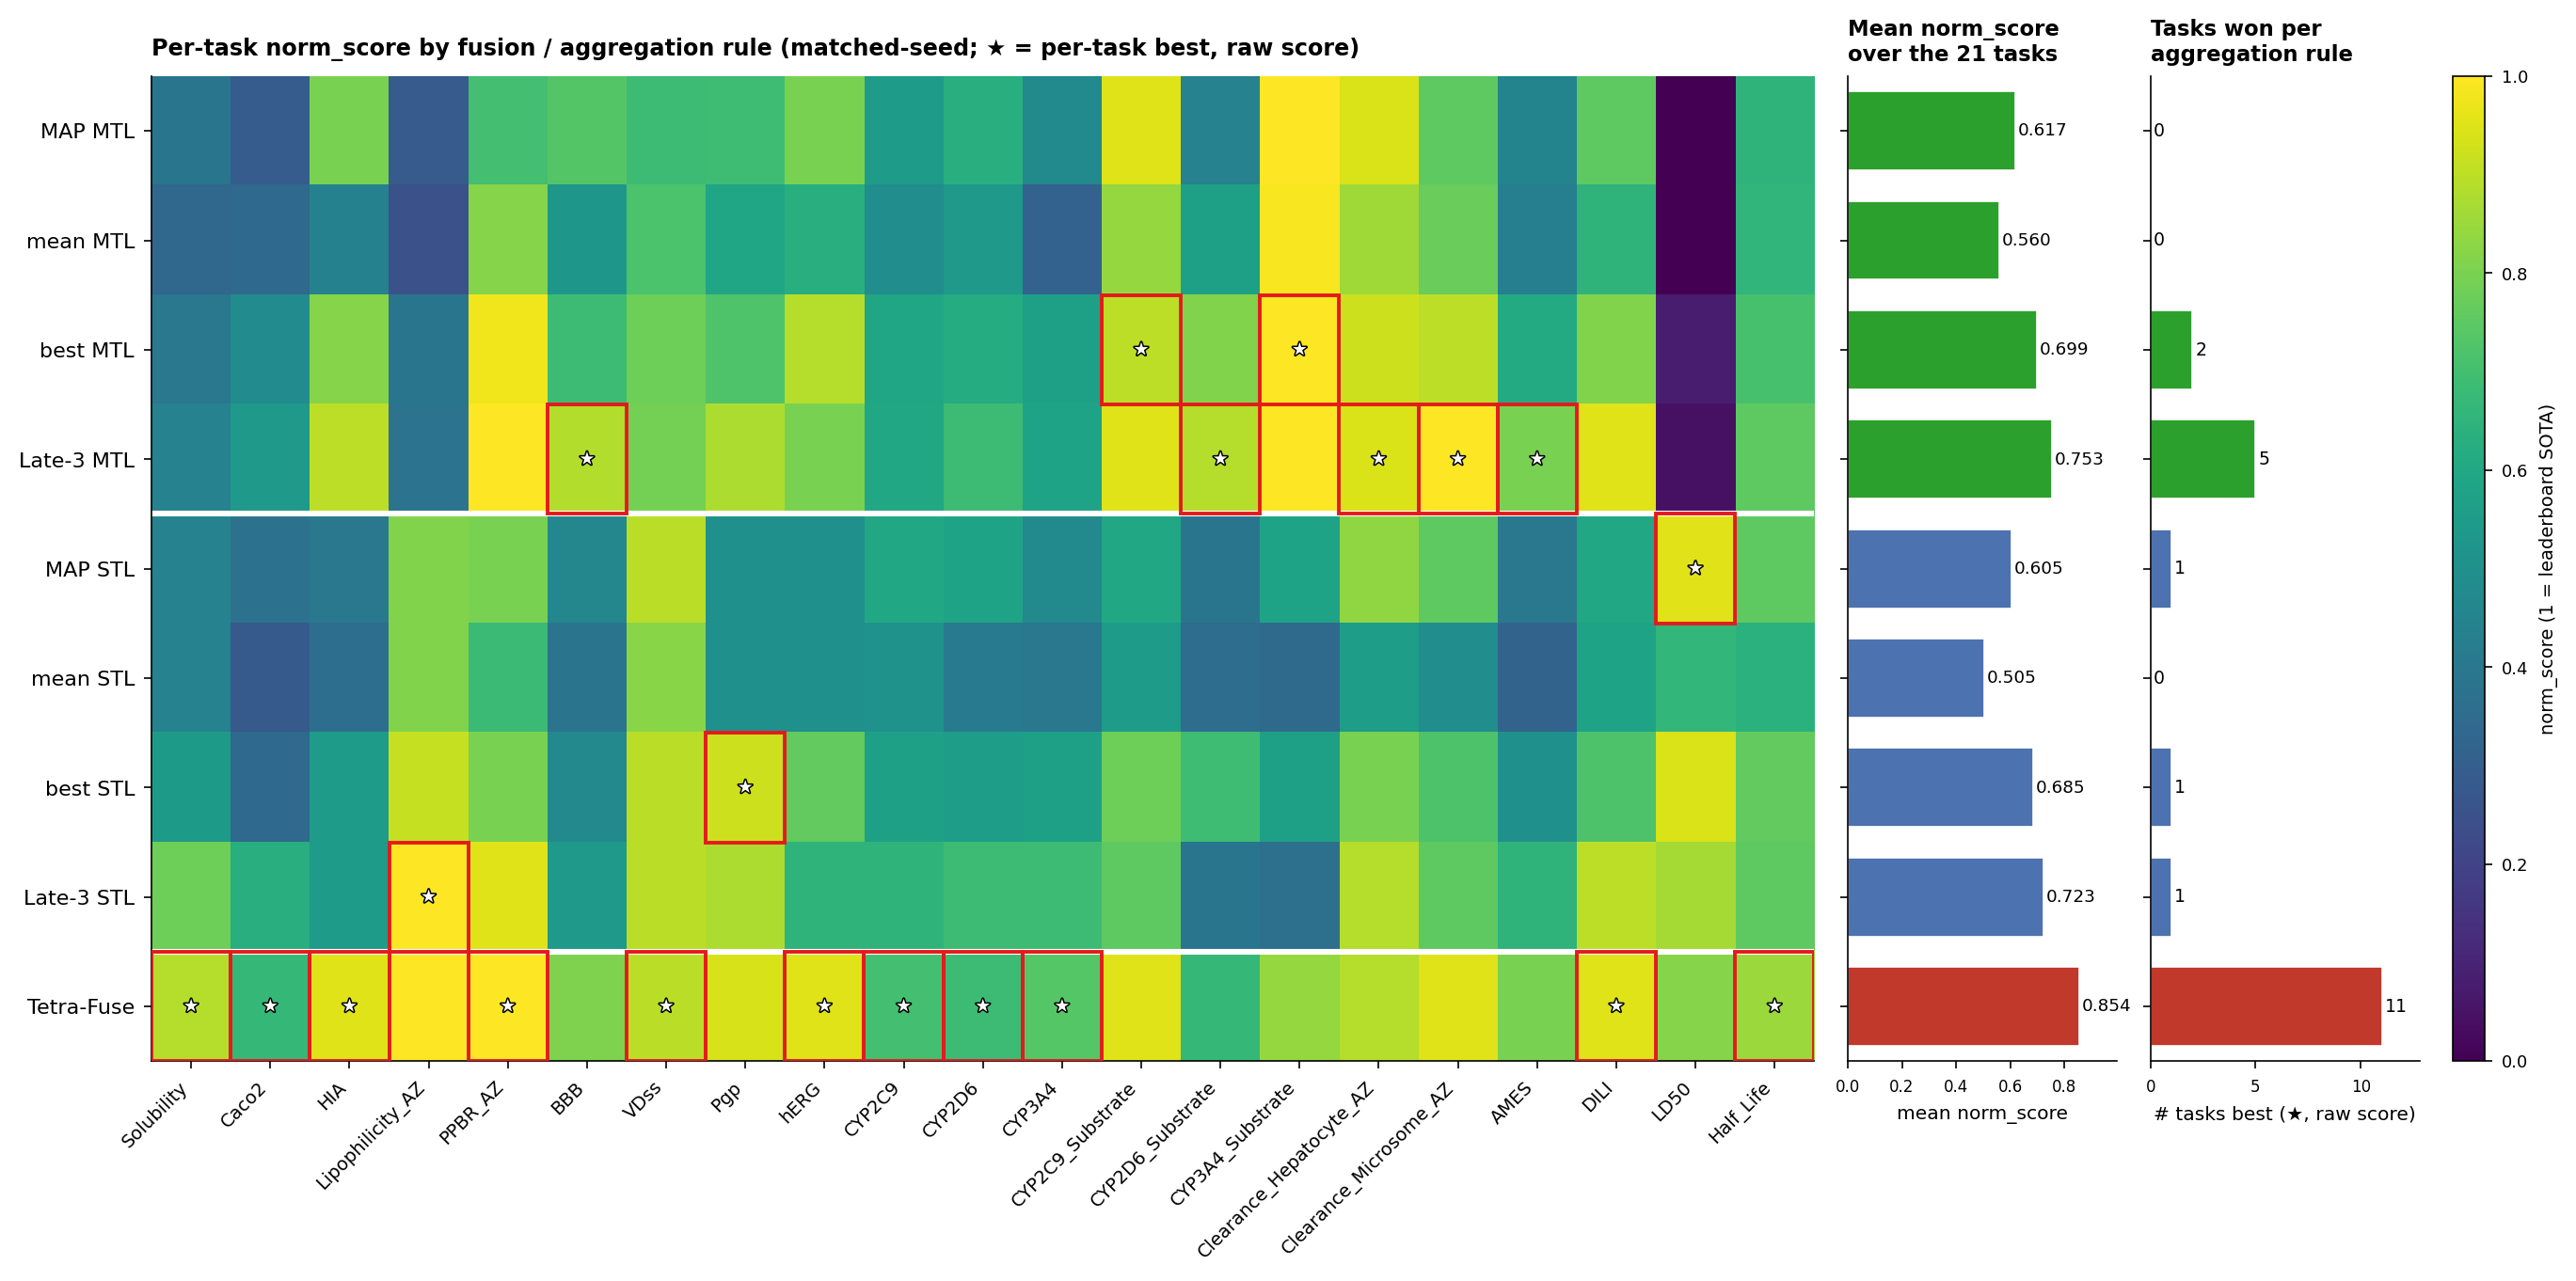

In [14]:
# === figureS2.png (Supplementary: per-task aggregation comparison, Fig.1a style) ===
# Same visual grammar as Figure 1a but for the representation-level aggregation columns of
# Table S2: a task x aggregation heatmap of matched-seed norm_score, with the per-task best
# column marked by a red box + star (chosen on the underlying RAW metric, direction-aware,
# exactly as in Fig.1a so ties do not spuriously multiply). Two summary bars beneath the
# heatmap give, for each aggregation, its mean norm_score over the 21 tasks and the number of
# tasks on which it is the per-task raw-score winner ("# tasks best"). Columns follow Table S2
# order (MTL block, then STL block, then Tetra-Fuse).
import numpy as np, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
apply_figure_style(sizes=(8,7,6))

# --- columns (same set/order as Table S2) ---
_S3_SPECS=[("MAP MTL",["mtl_map"]),("mean MTL","AGG:mtl_mean"),("best MTL","AGG:mtl_best"),
           ("Late-3 MTL",["mtl_chemeleon","mtl_graphmvp","mtl_molformer"]),
           ("MAP STL",["stl_map"]),("mean STL","AGG:stl_mean"),("best STL","AGG:stl_best"),
           ("Late-3 STL",["stl_chemeleon","stl_graphmvp","stl_molformer"]),
           ("Tetra-Fuse",list(_GT["final_ensemble"]))]
_S3_LABELS=[s[0] for s in _S3_SPECS]
_t3={e["dataset"]:e for e in _PT["t3"]}                       # MAP/mean/best per-task {raw,norm}
_task_order=[t for g in _FIG1["groups"].values() for t in g]  # mechanism-group task order (21)

def _col_norm_raw(spec):
    """Return {task:(raw,norm)} for one aggregation column."""
    kind=spec[1]
    if isinstance(kind,str) and kind.startswith("AGG:"):        # mtl_mean/mtl_best/... from _PT['t3']
        key=kind.split(":")[1]
        return {t:(_t3[t][key]["raw"], _t3[t][key]["norm"]) for t in _task_order}
    if spec[0] in ("MAP MTL","MAP STL"):                         # single MAP model from _PT['t3']
        key="mtl_map" if spec[0]=="MAP MTL" else "stl_map"
        return {t:(_t3[t][key]["raw"], _t3[t][key]["norm"]) for t in _task_order}
    ms=kind                                                      # Late-3 / Tetra: uniform-mean fusion
    raw=pertask_raw(ms,True); nrm=pertask_norm(ms,True)
    return {t:(raw[t],nrm[t]) for t in _task_order}

_cols_data=[_col_norm_raw(s) for s in _S3_SPECS]
Nmat=np.array([[_cols_data[j][t][1] for j in range(len(_S3_SPECS))] for t in _task_order])  # norm, tasks x cols
Rmat=np.array([[_cols_data[j][t][0] for j in range(len(_S3_SPECS))] for t in _task_order])  # raw
n_t,n_c=Nmat.shape
mean_norm=Nmat.mean(axis=0)                                     # per-column mean norm

# per-task best column by RAW (direction-aware; single winner, matches Fig.1a)
best_mask=np.zeros_like(Nmat,dtype=bool)
for i,t in enumerate(_task_order):
    met=REG[t]["metric"]; vals=Rmat[i,:]
    tgt=vals.min() if met=="mae" else vals.max()
    best_mask[i, np.abs(vals-tgt)<=1e-9]=True
ntask_best=best_mask.sum(axis=0)                               # per-column # tasks best (sum=21)

SHORT={"Solubility_AqSolDB":"Solubility","Caco2_Wang":"Caco2","HIA_Hou":"HIA","Lipophilicity_AstraZeneca":"Lipophilicity_AZ",
 "PPBR_AZ":"PPBR_AZ","BBB_Martins":"BBB","VDss_Lombardo":"VDss","Pgp_Broccatelli":"Pgp","hERG":"hERG",
 "CYP2C9_Veith":"CYP2C9","CYP2D6_Veith":"CYP2D6","CYP3A4_Veith":"CYP3A4","CYP2C9_Substrate_CarbonMangels":"CYP2C9_Substrate",
 "CYP2D6_Substrate_CarbonMangels":"CYP2D6_Substrate","CYP3A4_Substrate_CarbonMangels":"CYP3A4_Substrate",
 "Clearance_Hepatocyte_AZ":"Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ":"Clearance_Microsome_AZ",
 "AMES":"AMES","DILI":"DILI","LD50_Zhu":"LD50","Half_Life_Obach":"Half_Life"}
_bcol=["#2ca02c","#2ca02c","#2ca02c","#2ca02c","#4c72b0","#4c72b0","#4c72b0","#4c72b0","#c0392b"]

plt.close('all')
# landscape: tasks along x, aggregation columns along y; two summary bars to the right share the y-axis
fig=plt.figure(figsize=(16.0,6.8))
outer=GridSpec(1,4,width_ratios=[n_t,3.4,3.4,0.4],wspace=0.06)
axH=fig.add_subplot(outer[0])
axM=fig.add_subplot(outer[1], sharey=axH)   # mean norm_score (horizontal)
axN=fig.add_subplot(outer[2], sharey=axH)   # # tasks best (horizontal)
axC=fig.add_subplot(outer[3])               # colorbar (vertical, far right)
star_pe=[pe.withStroke(linewidth=1.1,foreground="black")]

im=axH.imshow(Nmat.T,aspect="auto",cmap="viridis",vmin=0,vmax=1)   # cols x tasks
axH.set_yticks(range(n_c)); axH.set_yticklabels(_S3_LABELS,fontsize=8)
axH.set_xticks(range(n_t)); axH.set_xticklabels([SHORT[t] for t in _task_order],rotation=45,ha="right",fontsize=7)
for i in range(n_t):
    for j in range(n_c):
        if best_mask[i,j]:
            axH.add_patch(Rectangle((i-0.5,j-0.5),1,1,fill=False,edgecolor="#e41a1c",lw=1.4,zorder=4))
            axH.text(i,j,"\u2605",ha="center",va="center",color="white",fontsize=6.8,zorder=5,path_effects=star_pe)
axH.axhline(3.5,color="white",lw=2.2)   # MTL | STL block divider (4 MTL rows, 4 STL rows)
axH.axhline(7.5,color="white",lw=2.2)   # STL | Tetra-Fuse divider
cb=fig.colorbar(im,cax=axC); cb.set_label("norm_score (1 = leaderboard SOTA)",fontsize=7); cb.ax.tick_params(labelsize=6.5)
axH.set_title("Per-task norm_score by fusion / aggregation rule (matched-seed; \u2605 = per-task best, raw score)",
              loc="left",fontweight="bold",fontsize=8.6,pad=8)

y=np.arange(n_c)
axM.barh(y,mean_norm,color=_bcol,edgecolor="white",height=0.72)
for yi,v in zip(y,mean_norm): axM.text(v+0.01,yi,f"{v:.3f}",va="center",ha="left",fontsize=6.6)
axM.set_xlim(0,max(mean_norm)+0.14); axM.tick_params(labelleft=False)
axM.set_xlabel("mean norm_score",fontsize=7.3)
axM.set_title("Mean norm_score\nover the 21 tasks",loc="left",fontweight="bold",fontsize=8.2)
axN.barh(y,ntask_best,color=_bcol,edgecolor="white",height=0.72)
for yi,v in zip(y,ntask_best): axN.text(v+0.15,yi,str(int(v)),va="center",ha="left",fontsize=6.8)
axN.set_xlim(0,ntask_best.max()+1.8); axN.tick_params(labelleft=False)
axN.set_xlabel("# tasks best (\u2605, raw score)",fontsize=7.3)
axN.set_title("Tasks won per\naggregation rule",loc="left",fontweight="bold",fontsize=8.2)

fig.savefig(os.path.join(OUTDIR,"figureS2.png"),dpi=300,bbox_inches="tight")
assert abs(mean_norm[-1]-0.854)<0.01, mean_norm[-1]
assert int(ntask_best.sum())==21, int(ntask_best.sum())
print("figureS2.png written (landscape) | Tetra mean", round(float(mean_norm[-1]),3),
      "| # tasks best", dict(zip(_S3_LABELS,[int(v) for v in ntask_best])))
plt.show()


## Fig. S3 Per-task performance heatmap and win counts comparing Tetra-Fuse against feature-level joint fusion and single-backbone baselines.

*This figure presents a focused comparison by excluding the 3-backbone late fusion (Late-3) baselines from the analysis shown in Fig. S2. This allows for a direct evaluation of the final Tetra-Fuse ensemble against the feature-level joint fusion (MAP) and the single-backbone baselines (mean and oracle best). The heatmap displays the rank-normalized scores (stars denote raw-score winners), while the bottom panels show the overall mean scores and task win counts. In this restricted setting, Tetra-Fuse's dominance is even more pronounced, securing first place in 14 out of the 21 tasks, decisively outperforming both the joint fusion approach and the oracle best individual backbones.*

figureS3.png written (landscape) | cols ['MAP MTL', 'mean MTL', 'best MTL', 'MAP STL', 'mean STL', 'best STL', 'Tetra-Fuse'] | Tetra mean 0.854 | # tasks best {'MAP MTL': 1, 'mean MTL': 0, 'best MTL': 4, 'MAP STL': 1, 'mean STL': 0, 'best STL': 1, 'Tetra-Fuse': 14}


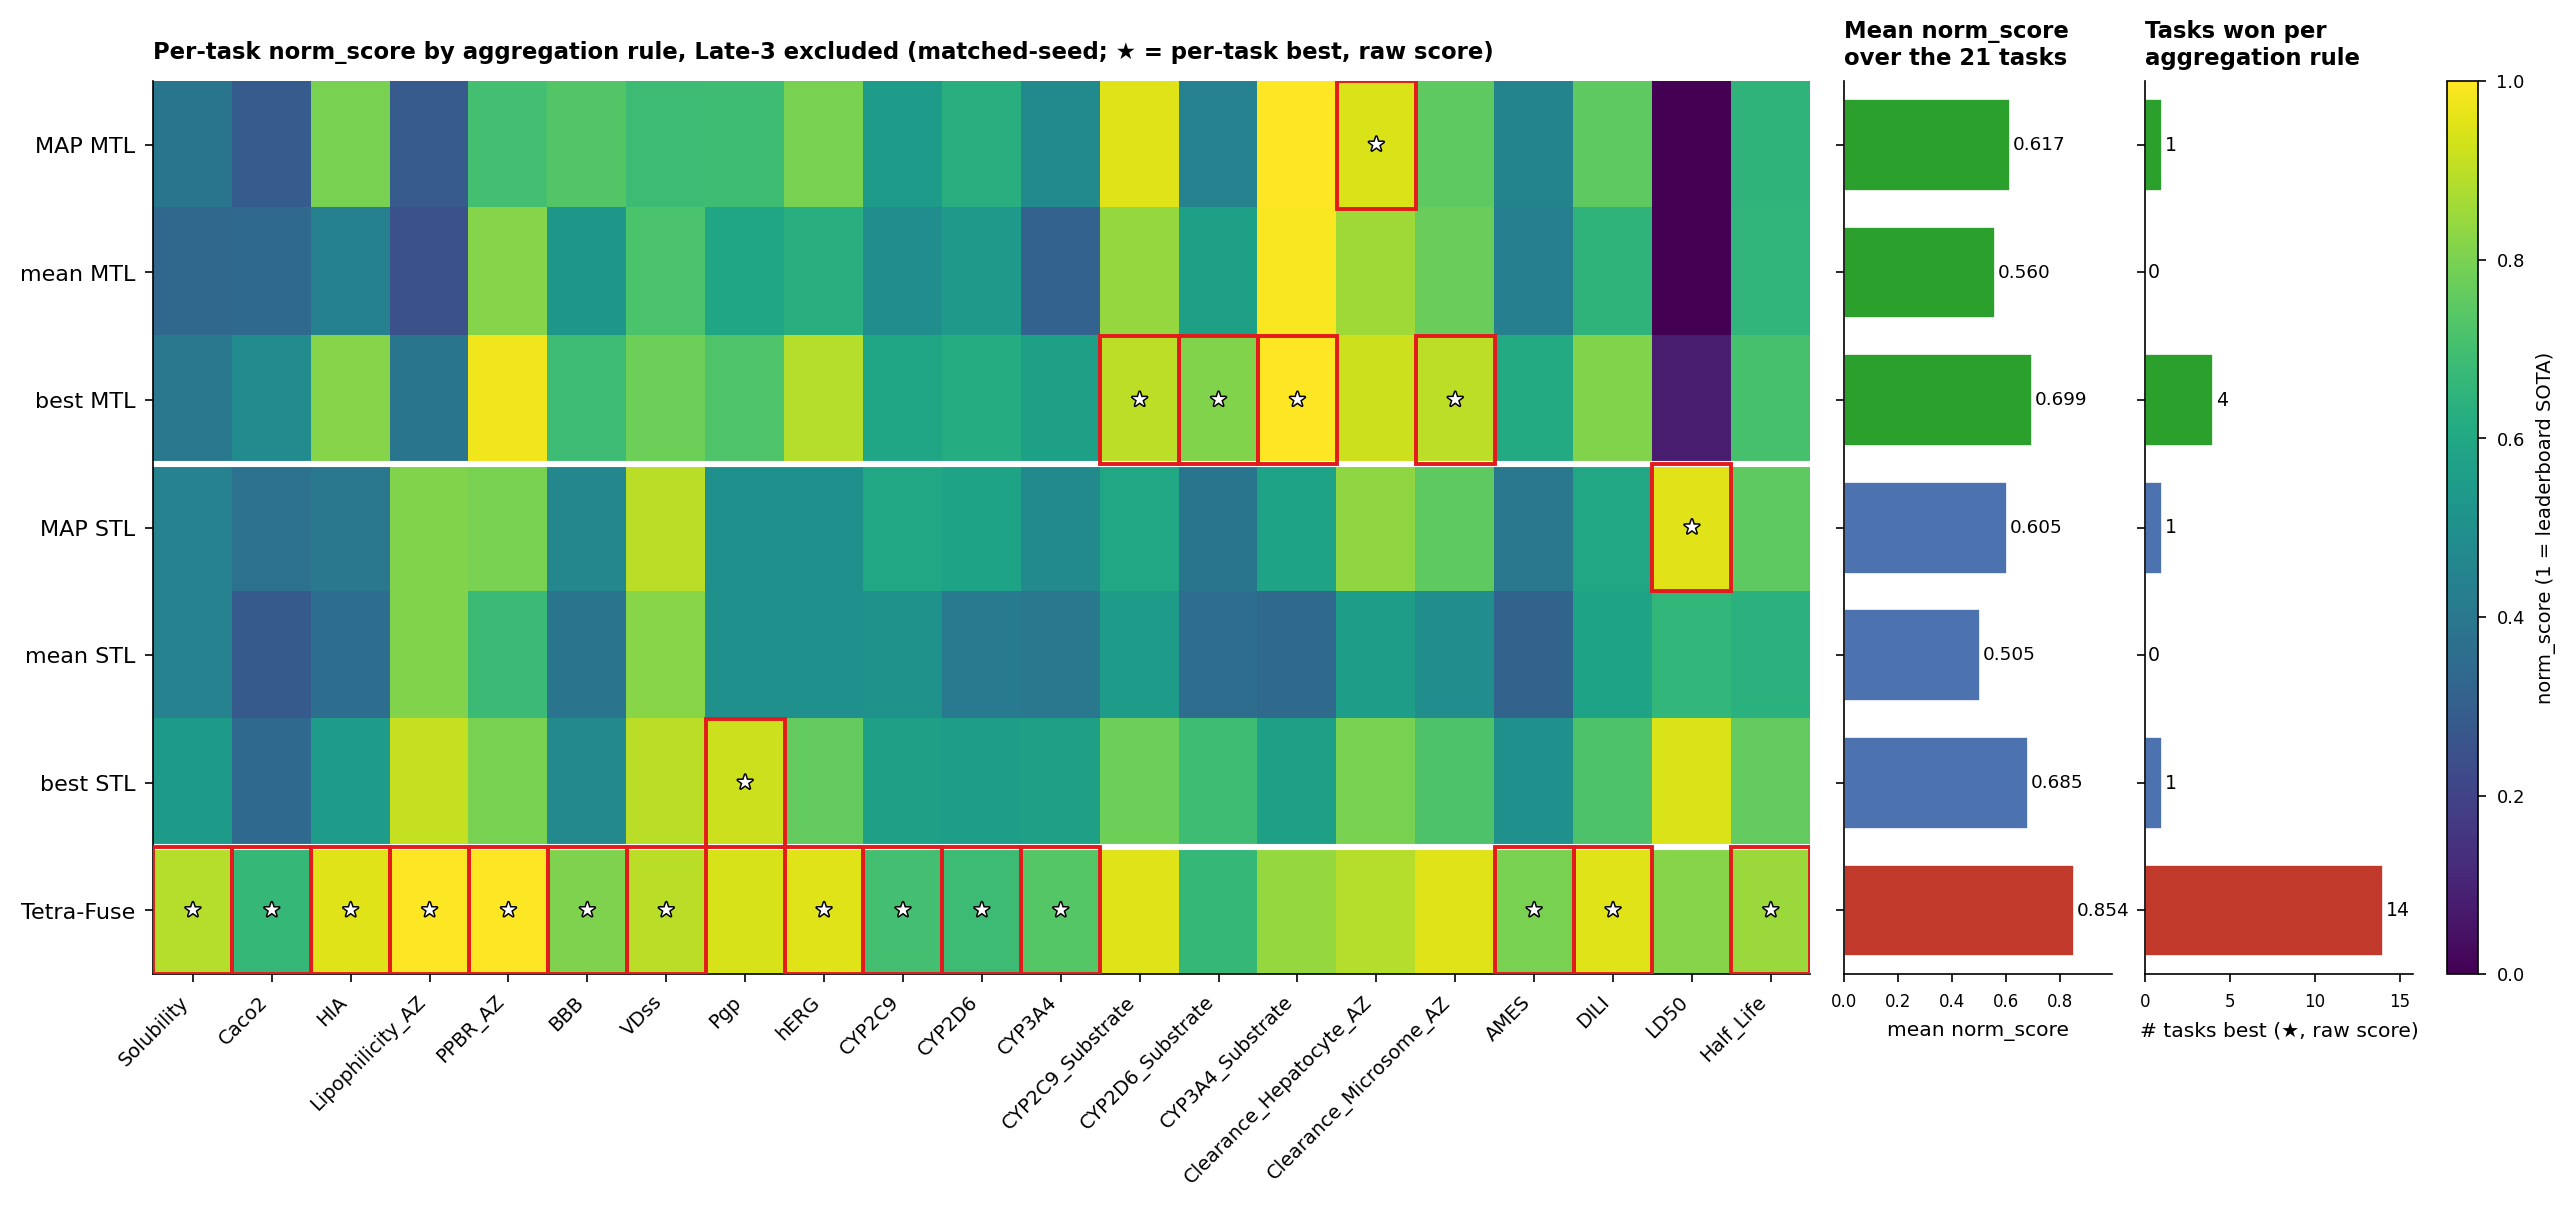

In [15]:
# === figureS3.png (Supplementary: aggregation comparison WITHOUT Late-3, Fig.1a style) ===
# Identical to Figure S2 but with the prediction-level Late-3 columns removed, so only the
# representation-level aggregation rules remain (MAP / naive latent mean / latent best, under
# MTL and STL) plus the final Tetra-Fuse ensemble. This isolates the joint-fusion (MAP) vs
# naive-aggregation contrast without the composition-matched late-fusion column.
import numpy as np, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
apply_figure_style(sizes=(8,7,6))

# --- columns: Table S2 aggregation set MINUS Late-3 (MTL block, STL block, then Tetra-Fuse) ---
_S5_SPECS=[("MAP MTL",["mtl_map"]),("mean MTL","AGG:mtl_mean"),("best MTL","AGG:mtl_best"),
           ("MAP STL",["stl_map"]),("mean STL","AGG:stl_mean"),("best STL","AGG:stl_best"),
           ("Tetra-Fuse",list(_GT["final_ensemble"]))]
_S5_LABELS=[s[0] for s in _S5_SPECS]
_t3={e["dataset"]:e for e in _PT["t3"]}                       # MAP/mean/best per-task {raw,norm}
_task_order=[t for g in _FIG1["groups"].values() for t in g]  # mechanism-group task order (21)

def _col_norm_raw(spec):
    """Return {task:(raw,norm)} for one aggregation column."""
    kind=spec[1]
    if isinstance(kind,str) and kind.startswith("AGG:"):        # mtl_mean/mtl_best/... from _PT['t3']
        key=kind.split(":")[1]
        return {t:(_t3[t][key]["raw"], _t3[t][key]["norm"]) for t in _task_order}
    if spec[0] in ("MAP MTL","MAP STL"):                         # single MAP model from _PT['t3']
        key="mtl_map" if spec[0]=="MAP MTL" else "stl_map"
        return {t:(_t3[t][key]["raw"], _t3[t][key]["norm"]) for t in _task_order}
    ms=kind                                                      # Tetra: uniform-mean fusion
    raw=pertask_raw(ms,True); nrm=pertask_norm(ms,True)
    return {t:(raw[t],nrm[t]) for t in _task_order}

_cols_data=[_col_norm_raw(s) for s in _S5_SPECS]
Nmat=np.array([[_cols_data[j][t][1] for j in range(len(_S5_SPECS))] for t in _task_order])  # norm, tasks x cols
Rmat=np.array([[_cols_data[j][t][0] for j in range(len(_S5_SPECS))] for t in _task_order])  # raw
n_t,n_c=Nmat.shape
mean_norm=Nmat.mean(axis=0)

# per-task best column by RAW (direction-aware; single winner, matches Fig.1a)
best_mask=np.zeros_like(Nmat,dtype=bool)
for i,t in enumerate(_task_order):
    met=REG[t]["metric"]; vals=Rmat[i,:]
    tgt=vals.min() if met=="mae" else vals.max()
    best_mask[i, np.abs(vals-tgt)<=1e-9]=True
ntask_best=best_mask.sum(axis=0)                               # per-column # tasks best (sum=21)

SHORT={"Solubility_AqSolDB":"Solubility","Caco2_Wang":"Caco2","HIA_Hou":"HIA","Lipophilicity_AstraZeneca":"Lipophilicity_AZ",
 "PPBR_AZ":"PPBR_AZ","BBB_Martins":"BBB","VDss_Lombardo":"VDss","Pgp_Broccatelli":"Pgp","hERG":"hERG",
 "CYP2C9_Veith":"CYP2C9","CYP2D6_Veith":"CYP2D6","CYP3A4_Veith":"CYP3A4","CYP2C9_Substrate_CarbonMangels":"CYP2C9_Substrate",
 "CYP2D6_Substrate_CarbonMangels":"CYP2D6_Substrate","CYP3A4_Substrate_CarbonMangels":"CYP3A4_Substrate",
 "Clearance_Hepatocyte_AZ":"Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ":"Clearance_Microsome_AZ",
 "AMES":"AMES","DILI":"DILI","LD50_Zhu":"LD50","Half_Life_Obach":"Half_Life"}
# 3 MTL (green) + 3 STL (blue) + Tetra (red)
_bcol=["#2ca02c","#2ca02c","#2ca02c","#4c72b0","#4c72b0","#4c72b0","#c0392b"]

plt.close('all')
# landscape: tasks along x, aggregation columns along y; two summary bars to the right share the y-axis
fig=plt.figure(figsize=(15.0,5.8))
outer=GridSpec(1,4,width_ratios=[n_t,3.4,3.4,0.4],wspace=0.06)
axH=fig.add_subplot(outer[0])
axM=fig.add_subplot(outer[1], sharey=axH)
axN=fig.add_subplot(outer[2], sharey=axH)
axC=fig.add_subplot(outer[3])
star_pe=[pe.withStroke(linewidth=1.1,foreground="black")]

im=axH.imshow(Nmat.T,aspect="auto",cmap="viridis",vmin=0,vmax=1)   # cols x tasks
axH.set_yticks(range(n_c)); axH.set_yticklabels(_S5_LABELS,fontsize=8)
axH.set_xticks(range(n_t)); axH.set_xticklabels([SHORT[t] for t in _task_order],rotation=45,ha="right",fontsize=7)
for i in range(n_t):
    for j in range(n_c):
        if best_mask[i,j]:
            axH.add_patch(Rectangle((i-0.5,j-0.5),1,1,fill=False,edgecolor="#e41a1c",lw=1.4,zorder=4))
            axH.text(i,j,"\u2605",ha="center",va="center",color="white",fontsize=6.8,zorder=5,path_effects=star_pe)
axH.axhline(2.5,color="white",lw=2.2)   # MTL (3 rows) | STL (3 rows) divider
axH.axhline(5.5,color="white",lw=2.2)   # STL | Tetra-Fuse divider
cb=fig.colorbar(im,cax=axC); cb.set_label("norm_score (1 = leaderboard SOTA)",fontsize=7); cb.ax.tick_params(labelsize=6.5)
axH.set_title("Per-task norm_score by aggregation rule, Late-3 excluded (matched-seed; \u2605 = per-task best, raw score)",
              loc="left",fontweight="bold",fontsize=8.2,pad=8)

y=np.arange(n_c)
axM.barh(y,mean_norm,color=_bcol,edgecolor="white",height=0.72)
for yi,v in zip(y,mean_norm): axM.text(v+0.01,yi,f"{v:.3f}",va="center",ha="left",fontsize=6.6)
axM.set_xlim(0,max(mean_norm)+0.14); axM.tick_params(labelleft=False)
axM.set_xlabel("mean norm_score",fontsize=7.3)
axM.set_title("Mean norm_score\nover the 21 tasks",loc="left",fontweight="bold",fontsize=8.2)
axN.barh(y,ntask_best,color=_bcol,edgecolor="white",height=0.72)
for yi,v in zip(y,ntask_best): axN.text(v+0.15,yi,str(int(v)),va="center",ha="left",fontsize=6.8)
axN.set_xlim(0,ntask_best.max()+1.8); axN.tick_params(labelleft=False)
axN.set_xlabel("# tasks best (\u2605, raw score)",fontsize=7.3)
axN.set_title("Tasks won per\naggregation rule",loc="left",fontweight="bold",fontsize=8.2)

fig.savefig(os.path.join(OUTDIR,"figureS3.png"),dpi=300,bbox_inches="tight")
assert abs(mean_norm[-1]-0.854)<0.01, mean_norm[-1]
assert int(ntask_best.sum())==21, int(ntask_best.sum())
assert "Late-3" not in " ".join(_S5_LABELS)
print("figureS3.png written (landscape) | cols", _S5_LABELS, "| Tetra mean", round(float(mean_norm[-1]),3),
      "| # tasks best", dict(zip(_S5_LABELS,[int(v) for v in ntask_best])))
plt.show()


# 3.3 Held-out-test performance


In [16]:
# --- Table 3: held-out-test summary of the final k=5 Tetra-Fuse ensemble (21 tasks) ---
# Per-track mean norm_score, mean TDC rank, and count of tasks at rank<=1/3/5, from _PT["t4"].
_t4e=[e for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]
def _agg(ns,rk):
    norms=[e[ns] for e in _t4e]; ranks=[e[rk] for e in _t4e]
    return [round(float(np.mean(norms)),3), round(float(np.mean(ranks)),2),
            sum(r<=1 for r in ranks), sum(r<=3 for r in ranks), sum(r<=5 for r in ranks)]
T3_rows=[["matched-seed track"]+_agg("within_norm","within_rank"),
         ["seed-averaged track"]+_agg("cross_norm","cross_rank")]
T3=pd.DataFrame(T3_rows, columns=["Evaluation track","Mean norm_score","Mean rank","# rank-1","# top-3","# top-5"])
register("table3_ensemble_summary", T3)
assert T3.iloc[0].tolist()==["matched-seed track",0.854,3.95,2,11,15], T3.iloc[0].tolist()
assert T3.iloc[1].tolist()==["seed-averaged track",0.897,3.10,6,14,19], T3.iloc[1].tolist()
print("Table 3 OK", T3.shape); T3

Table 3 OK (2, 6)


,Evaluation track,Mean norm_score,Mean rank,# rank-1,# top-3,# top-5
0,matched-seed track,0.854,3.95,2,11,15
1,seed-averaged track,0.897,3.10,6,14,19


*Table 3. Held-out-test summary of the final five-model (k = 5) Tetra-Fuse ensemble across the 21 TDC ADMET tasks, reported for both evaluation tracks. For each track we give the mean norm_score, the mean TDC leaderboard rank, and the number of tasks reaching rank ≤ 1, ≤ 3, and ≤ 5. The matched-seed track scores each seed separately and averages; the seed-averaged track pools the five-seed predictions before scoring.*

## Fig. S6 (Supplementary) — Per-task raw-score comparison, by metric family

figureS6.png written | sig tasks (Holm p<0.05): 5 /21 | matched>best (blue): 0 | best>matched (red): 5 | seed-avg outside ±2sd: 1
blue (matched>best): []
red  (best>matched): ['CYP2C9_Veith', 'CYP2D6_Veith', 'CYP3A4_Veith', 'AMES', 'Clearance_Hepatocyte_AZ']


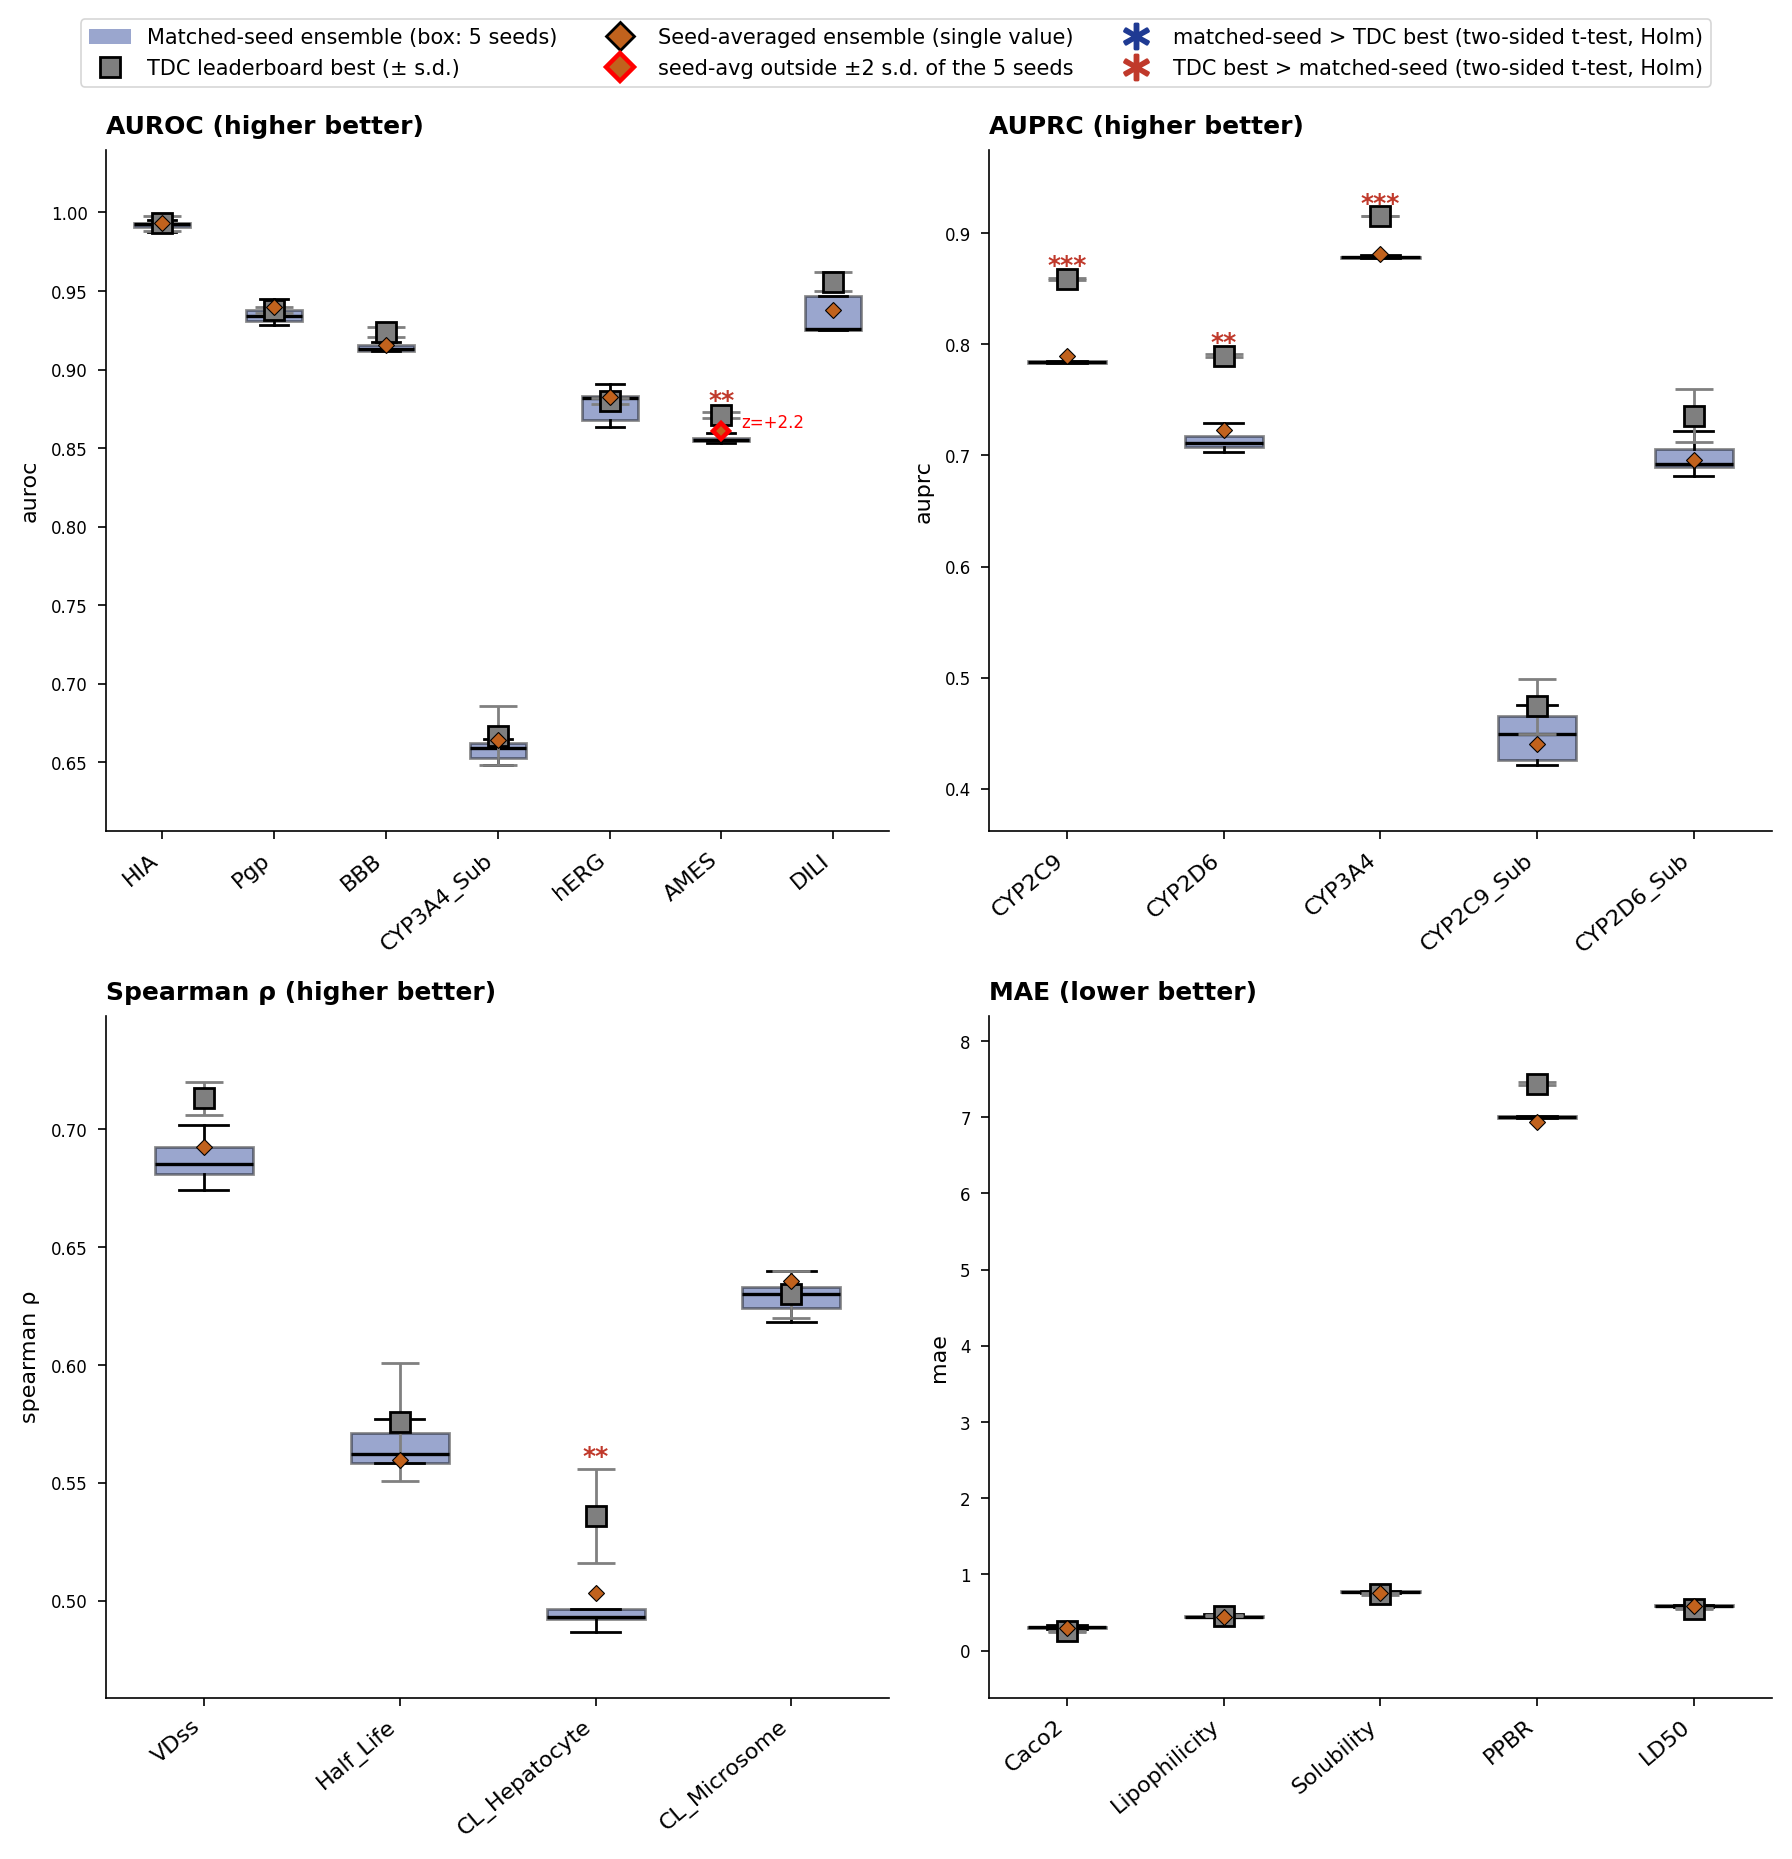

In [17]:
# === figureS6.png (Supplementary: per-task box plots vs TDC leaderboard best, faceted by metric) ===
# Per-task, three-way RAW-score comparison shown as box plots of the five matched-seed scores,
# overlaid with the TDC leaderboard best (grey square + s.d. error bar) and the seed-averaged
# ensemble (orange diamond, single pooled value). Two questions are answered per task:
#  (1) Is the matched-seed ensemble different from the TDC leaderboard best, and in which direction?
#      -> one-sample, TWO-sided t-test of the five per-seed scores against the fixed leaderboard
#         best value (df = 4, so power is limited). Stars use the Holm-adjusted p across all 21
#         tasks; the sign of the mean gap sets the colour: blue star = matched-seed > TDC best,
#         red star = TDC best > matched-seed.
#  (2) Does the seed-averaged value fall inside the matched-seed 5-seed distribution?
#      -> z = (seedavg - matched_mean)/matched_sd; |z| > 2 (outside ~95% of the seed spread)
#         is flagged with a ringed marker and the z value.
import numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
apply_figure_style(sizes=(8,7,6))

def _tdc_best(task):
    e=SNAP.get(task)
    if not e or not e.get("models"): return (None,None,None)
    md=e["models"]; direc=e.get("direction","higher")
    bm=(min if direc=="lower" else max)(md, key=lambda k: md[k]["score"])
    return bm, md[bm]["score"], md[bm].get("std")

# per-seed matched scores for every task (same recipe as table_t4: merge_uniform within, group by seed)
_bw = merge_uniform(ENSEMBLE, True)
def _seed_scores(task):
    met=REG[task]["metric"]
    tw=_bw[(_bw.task==task)&(_bw.split=="test")].dropna(subset=["y_true"])
    return met, np.array([metric(met, g.y_true, g.yhat) for _,g in tw.groupby("seed")], dtype=float)

recs=[]
for e in _t4e:
    t=e["task"]; met,seeds=_seed_scores(t)
    bm,bs,bstd=_tdc_best(t)
    if bs is None or len(seeds)<2: continue
    sign = -1.0 if met=="mae" else 1.0                    # + = better
    # (1) TWO-sided one-sample t-test: do the 5 seed scores differ from the fixed best?
    #     direction-aligned mean gap (+ = matched-seed better; - = TDC best better)
    tstat,p2 = ttest_1samp(sign*seeds, sign*bs)
    gap = float((sign*seeds).mean() - sign*bs)            # + matched better, - best better
    # (2) seed-avg position within the matched 5-seed distribution
    m_mean=float(seeds.mean()); m_sd=float(seeds.std(ddof=0)); sa=e["cross_score"]
    z = (sa-m_mean)/m_sd if m_sd>0 else 0.0
    recs.append(dict(task=t, metric=met, seeds=seeds, best=bs, best_sd=(bstd or 0.0),
                     seedavg=sa, m_mean=m_mean, m_sd=m_sd, p_raw=float(p2), gap=gap, z=z, tstat=tstat))
D=pd.DataFrame(recs); n=len(D)
# Holm across all 21 tasks (one-sided ensemble>best)
rej,pholm,_,_=multipletests(D.p_raw.to_numpy(), method="holm")
D["p_holm"]=pholm
def _stars(p): return "***" if p<1e-3 else "**" if p<1e-2 else "*" if p<0.05 else ""

SHORT={"Solubility_AqSolDB":"Solubility","Caco2_Wang":"Caco2","HIA_Hou":"HIA","Lipophilicity_AstraZeneca":"Lipophilicity",
 "PPBR_AZ":"PPBR","BBB_Martins":"BBB","VDss_Lombardo":"VDss","Pgp_Broccatelli":"Pgp","hERG":"hERG",
 "CYP2C9_Veith":"CYP2C9","CYP2D6_Veith":"CYP2D6","CYP3A4_Veith":"CYP3A4","CYP2C9_Substrate_CarbonMangels":"CYP2C9_Sub",
 "CYP2D6_Substrate_CarbonMangels":"CYP2D6_Sub","CYP3A4_Substrate_CarbonMangels":"CYP3A4_Sub",
 "Clearance_Hepatocyte_AZ":"CL_Hepatocyte","Clearance_Microsome_AZ":"CL_Microsome",
 "AMES":"AMES","DILI":"DILI","LD50_Zhu":"LD50","Half_Life_Obach":"Half_Life"}
FAC=[("auroc","AUROC (higher better)"),("auprc","AUPRC (higher better)"),
     ("spearman","Spearman \u03c1 (higher better)"),("mae","MAE (lower better)")]
COL_BEST="#7f7f7f"; COL_M="#1f3a93"; COL_S="#c1621d"

plt.close('all')
fig,axes=plt.subplots(2,2,figsize=(9,9))
for ax,(met,title) in zip(axes.ravel(),FAC):
    sub=D[D.metric==met].reset_index(drop=True); m=len(sub); x=np.arange(m)
    # matched-seed box plots (5 seeds each)
    bp=ax.boxplot([r.seeds for _,r in sub.iterrows()], positions=x, widths=0.5,
                  patch_artist=True, medianprops=dict(color="black",lw=1.2), showfliers=False)
    for patch in bp["boxes"]: patch.set_facecolor(COL_M); patch.set_alpha(0.45)
    # TDC best: grey square + sd error bar
    ax.errorbar(x-0.0, sub.best, yerr=sub.best_sd, fmt="s", color=COL_BEST, ms=7,
                capsize=7, elinewidth=1.0, ecolor="grey", mec="black", mew=1, zorder=6, label="TDC best")
    # seed-averaged: orange diamond; ring if |z|>2 (outside 5-seed distribution)
    for xi,(_,r) in zip(x,sub.iterrows()):
        out = abs(r.z)>2
        ax.plot(xi, r.seedavg, marker="D", ms=4, color=COL_S,
                mec=("red" if out else "black"), mew=(1.6 if out else 0.4), zorder=7)
        if out: ax.annotate(f"z={r.z:+.1f}", (xi,r.seedavg), textcoords="offset points",
                            xytext=(7,3), fontsize=6.0, color="red", va="center")
    # significance stars (matched vs TDC best), coloured by direction of the gap
    for xi,(_,r) in zip(x,sub.iterrows()):
        st=_stars(r.p_holm)
        if st:
            top=max(r.seeds.max(), r.best+r.best_sd, r.seedavg)
            scol = COL_M if r.gap>0 else "#c0392b"       # blue: matched>best ; red: best>matched
            ax.text(xi, top, st, ha="center", va="bottom", fontsize=9, color=scol, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels([SHORT[t] for t in sub.task],rotation=40,ha="right",fontsize=8)
    ax.set_title(title,loc="left",fontweight="bold",fontsize=9)
    ax.set_ylabel(met if met!="spearman" else "spearman \u03c1",fontsize=8)
    ax.margins(x=0.04, y=0.12)

handles=[Patch(facecolor=COL_M,alpha=0.45,label="Matched-seed ensemble (box: 5 seeds)"),
         Line2D([0],[0],marker="s",color="none",mfc=COL_BEST,mec="black",ms=7,label="TDC leaderboard best (\u00b1 s.d.)"),
         Line2D([0],[0],marker="D",color="none",mfc=COL_S,mec="black",ms=7,label="Seed-averaged ensemble (single value)"),
         Line2D([0],[0],marker="D",color="none",mfc=COL_S,mec="red",mew=1.6,ms=7,label="seed-avg outside \u00b12 s.d. of the 5 seeds"),
         Line2D([0],[0],marker="$*$",color=COL_M,ms=9,lw=0,label="matched-seed > TDC best (two-sided t-test, Holm)"),
         Line2D([0],[0],marker="$*$",color="#c0392b",ms=9,lw=0,label="TDC best > matched-seed (two-sided t-test, Holm)")]
fig.legend(handles=handles,loc="upper center",ncol=3,fontsize=7.5,frameon=True,bbox_to_anchor=(0.5,1.03))
# fig.suptitle("Per-task matched-seed ensemble vs TDC leaderboard best, with seed-averaged position",
#              fontweight="bold",fontsize=10,y=1.06)
fig.tight_layout(rect=[0,0,1,0.985])
fig.savefig(os.path.join(OUTDIR,"figureS6.png"),dpi=300,bbox_inches="tight")
assert n==21
_sig=D[D.p_holm<0.05]
_blue=list(_sig[_sig.gap>0].task); _red=list(_sig[_sig.gap<0].task); _nout=int((D.z.abs()>2).sum())
print("figureS6.png written | sig tasks (Holm p<0.05):", len(_sig), "/21",
      "| matched>best (blue):", len(_blue), "| best>matched (red):", len(_red),
      "| seed-avg outside ±2sd:", _nout)
print("blue (matched>best):", _blue)
print("red  (best>matched):", _red)
plt.show()


*Figure S6. Per-task raw held-out-test scores across the 21 TDC ADMET tasks, grouped into one panel per metric family (AUROC, AUPRC, Spearman ρ — higher is better; MAE — lower is better). For each task the box shows the five matched-seed ensemble scores (blue); the grey square with error bar is the TDC leaderboard best model (score ± s.d. from the leaderboard snapshot); the orange diamond is the seed-averaged ensemble (single pooled value, no seed-level s.d.). Two questions are annotated. (1) Whether the matched-seed ensemble differs from the leaderboard best is tested with a one-sample, two-sided t-test of the five per-seed scores against the fixed leaderboard-best value (df = 4, so power is limited); asterisks (*, **, *** at p < 0.05, 0.01, 0.001) use the Holm-adjusted p across all 21 tasks and are coloured by direction — blue when the matched-seed ensemble exceeds the leaderboard best, red when the leaderboard best exceeds the matched-seed ensemble. (2) Whether the seed-averaged value falls inside the matched-seed distribution is summarised by z = (seed-averaged − matched mean)/matched s.d.; a red-ringed diamond with its z value flags |z| > 2 (outside roughly the central 95% of the five-seed spread). The same scores, with leaderboard ranks, are listed in Table 4.*

## Fig. S7 (Supplementary) — Leaderboard coverage versus mean rank

figureS7.png written | distinct models 41 | full-21 models 14 | Tetra-Fuse mean rank 3.95 | full-cov models better than Tetra-Fuse: ['MapLight + GNN']


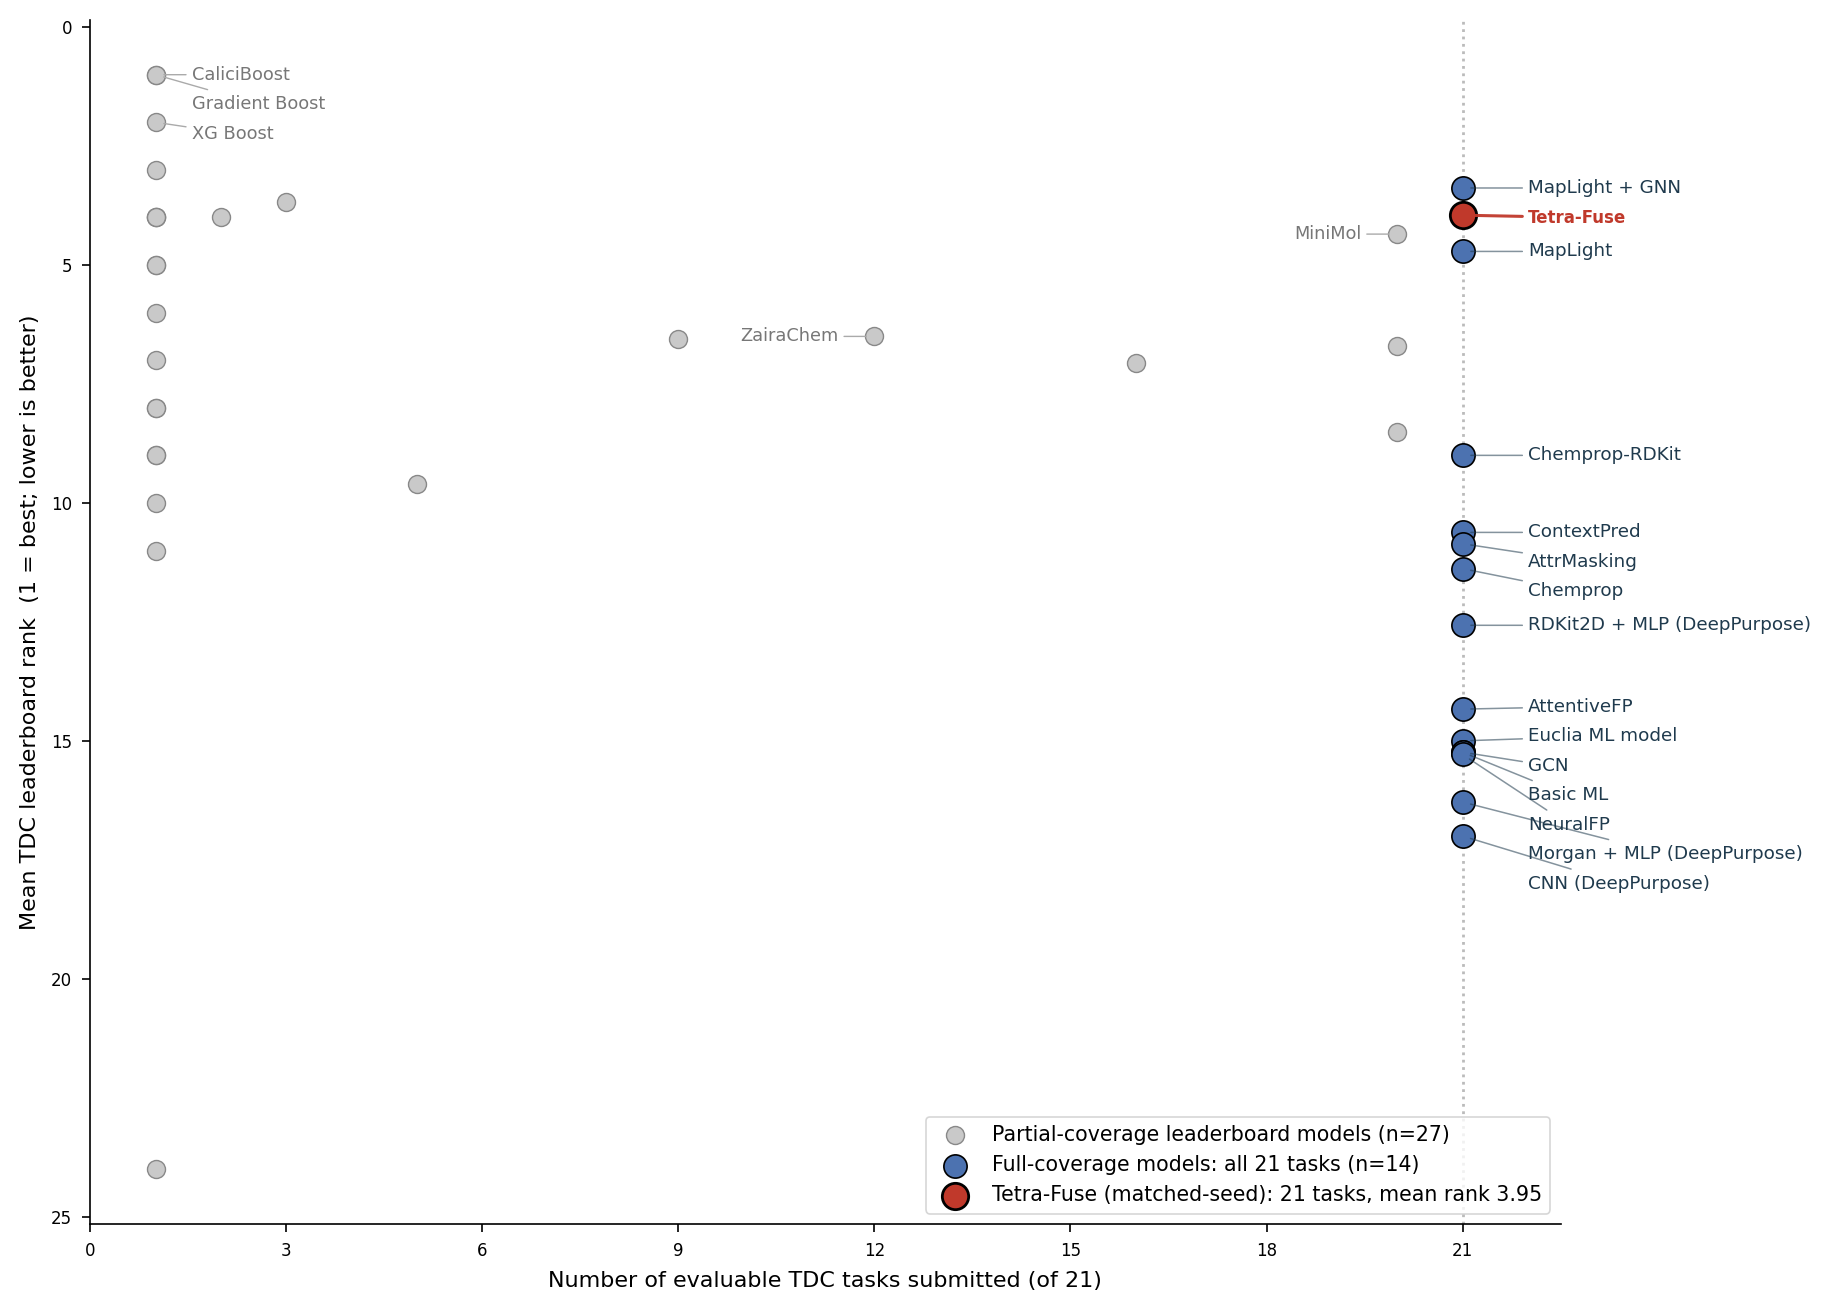

In [18]:
# === figureS7.png (Supplementary: leaderboard coverage vs mean rank) ===
# How the final Tetra-Fuse ensemble compares to every other model on the TDC ADMET leaderboard
# in terms of BREADTH (how many of the 21 evaluable tasks a model submitted to) and DEPTH
# (its mean leaderboard rank over the tasks it entered). Many leaderboard models submit to only
# a handful of tasks, which can give a deceptively low mean rank; a fair comparison must read
# coverage and mean rank together. Bioavailability_Ma is excluded (21 evaluable tasks).
import numpy as np, matplotlib.pyplot as plt
from collections import defaultdict
from matplotlib.ticker import MaxNLocator
apply_figure_style(sizes=(8,7,6))

# 21 evaluable tasks (skip the _timestamp metadata key and Bioavailability_Ma)
EVAL=[t for t,v in SNAP.items() if isinstance(v,dict) and "models" in v and t!="Bioavailability_Ma"]
assert len(EVAL)==21, len(EVAL)
def _ranks(task):
    e=SNAP[task]; md=e["models"]; direc=e.get("direction","higher")
    items=[(m,v["score"]) for m,v in md.items()]
    return {m: sum(1 for _,s2 in items if (s2<s if direc=="lower" else s2>s))+1 for m,s in items}
mr=defaultdict(list)
for t in EVAL:
    for m,rk in _ranks(t).items(): mr[m].append(rk)
lb=pd.DataFrame([(m,len(v),float(np.mean(v))) for m,v in mr.items()],
                columns=["model","n_tasks","mean_rank"]).sort_values(["mean_rank","n_tasks"]).reset_index(drop=True)

# Tetra-Fuse: matched-seed mean rank over the 21 evaluable tasks (from _PT["t4"], excl Bioavailability_Ma)
tetra_ranks=[e["within_rank"] for e in _t4e if e["task"]!="Bioavailability_Ma"]
assert len(tetra_ranks)==21
TETRA_N=21; TETRA_MR=float(np.mean(tetra_ranks))

plt.close('all')
fig,ax=plt.subplots(figsize=(9.2,6.6))
# split partial- vs full-coverage leaderboard models
full=lb[lb.n_tasks==21]; part=lb[lb.n_tasks<21]
ax.scatter(part.n_tasks, part.mean_rank, s=42, facecolor="#c9c9c9", edgecolor="#888", lw=0.5,
           zorder=3, label=f"Partial-coverage leaderboard models (n={len(part)})")
ax.scatter(full.n_tasks, full.mean_rank, s=70, facecolor="#4c72b0", edgecolor="black", lw=0.6,
           zorder=4, label=f"Full-coverage models: all 21 tasks (n={len(full)})")
# Tetra-Fuse star
ax.scatter([TETRA_N],[TETRA_MR], s=90, marker="o", color="#c0392b", edgecolor="black", lw=1,
           zorder=6, label=f"Tetra-Fuse (matched-seed): 21 tasks, mean rank {TETRA_MR:.2f}")
ax.invert_yaxis()   # rank 1 (best) at the top
ax.set_xlabel("Number of evaluable TDC tasks submitted (of 21)")
ax.set_ylabel("Mean TDC leaderboard rank  (1 = best; lower is better)")
# ax.set_title("Leaderboard breadth vs mean rank: Tetra-Fuse covers all 21 tasks at a top-tier mean rank",
#              loc="left", fontweight="bold", fontsize=9)
ax.axvline(21, color="#bbb", ls=":", lw=1, zorder=1)

# ── 겹침 없는 라벨 배치: 전용 라벨 컬럼 + 자동 수직 분산 + 리더선 ──────────────
def _spread(ys, min_gap, lo, hi):
    """ys를 원래 순서 유지한 채 최소 간격 min_gap 이상으로 벌림 (lo~hi 범위 내)."""
    order = np.argsort(ys)
    v = np.array(ys, float)[order]
    # 1차: 아래에서 위로 밀기
    for i in range(1, len(v)):
        if v[i] - v[i-1] < min_gap:
            v[i] = v[i-1] + min_gap
    # 2차: 상한 초과분을 위에서 아래로 되밀기
    if len(v) and v[-1] > hi:
        v[-1] = hi
        for i in range(len(v)-2, -1, -1):
            if v[i+1] - v[i] < min_gap:
                v[i] = v[i+1] - min_gap
    v = np.clip(v, lo, hi)
    out = np.empty_like(v)
    out[order] = v
    return out

LAB_X = 22.0          # 라벨 컬럼 x 위치 (축 우측 여백)
ax.set_xlim(0, 26.5)  # 라벨 컬럼을 담을 여백 확보

# --- 1) full-coverage(x=21) + Tetra-Fuse: 우측 라벨 컬럼에 일괄 배치 ---
right = [(rw.n_tasks, rw.mean_rank, rw.model, "#1f3a4d", 6.6, False)
         for _, rw in full.iterrows()]
right.append((TETRA_N, TETRA_MR, "Tetra-Fuse", "#c0392b", 6.0, True))
right.sort(key=lambda t: t[1])                      # 순위(=y) 오름차순

ys_r = _spread([t[1] for t in right], min_gap=0.62,
               lo=min(t[1] for t in right) - 1.0,
               hi=max(t[1] for t in right) + 1.0)

for (x, y, txt, col, fs, is_star), ty in zip(right, ys_r):
    ax.annotate(
        txt, xy=(x, y), xytext=(LAB_X, ty),
        textcoords="data", ha="left", va="center",
        fontsize=fs, color=col, fontweight="bold" if is_star else "normal",
        zorder=8,
        arrowprops=dict(arrowstyle="-", color=col,
                        lw=1.1 if is_star else 0.55,
                        alpha=0.95 if is_star else 0.55,
                        shrinkA=0, shrinkB=3,
                        connectionstyle="arc3,rad=0"),
    )

# --- 2) partial-coverage 주석 대상: 마커 왼쪽에 배치해 우측 컬럼과 분리 ---
# --- 2) partial-coverage 주석 대상 ---
_partnames_right = ["CaliciBoost", "Gradient Boost", "XG Boost"]   # 마커 오른쪽
_partnames_left  = ["MiniMol", "ZairaChem"]                        # 마커 왼쪽

def _collect(names):
    out = [(part[part.model == n].iloc[0].n_tasks,
            part[part.model == n].iloc[0].mean_rank, n)
           for n in names if n in set(part.model)]
    out.sort(key=lambda t: t[1])
    return out

def _draw(items, side):
    if not items:
        return
    ys = _spread([t[1] for t in items], min_gap=0.62,
                 lo=min(t[1] for t in items) - 1.0,
                 hi=max(t[1] for t in items) + 1.0)
    for (x, y, txt), ty in zip(items, ys):
        dx, ha = (0.55, "left") if side == "right" else (-0.55, "right")
        ax.annotate(
            txt, xy=(x, y), xytext=(x + dx, ty),
            textcoords="data", ha=ha, va="center",
            fontsize=6.4, color="#777", zorder=8,
            arrowprops=dict(arrowstyle="-", color="#aaa", lw=0.5,
                            shrinkA=0, shrinkB=3),
        )

_draw(_collect(_partnames_right), "right")
_draw(_collect(_partnames_left),  "left")

ax.legend(loc="lower right", fontsize=7.4, frameon=True)
ax.set_xlim(0,22.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # ← 이 줄 추가
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR,"figureS7.png"),dpi=300,bbox_inches="tight")
# checks: 14 full-coverage models; among them only MapLight+GNN beats Tetra-Fuse mean rank
n_full=int((lb.n_tasks==21).sum())
beat=list(full[full.mean_rank<TETRA_MR].model)
print("figureS7.png written | distinct models", len(lb), "| full-21 models", n_full,
      "| Tetra-Fuse mean rank", round(TETRA_MR,2), "| full-cov models better than Tetra-Fuse:", beat)
assert abs(TETRA_MR-3.95)<0.02, TETRA_MR
plt.show()


*Figure S7. Breadth–depth view of the TDC ADMET leaderboard over the 21 evaluable tasks (Bioavailability_Ma excluded). Each point is a leaderboard model, positioned by the number of tasks it submitted to (x-axis) and its mean leaderboard rank over those tasks (y-axis, inverted so rank 1 is at the top). Grey points are partial-coverage models — many attain a low mean rank only because they entered one or a few tasks — while blue points are the models that submitted to all 21 tasks. The red star is our final Tetra-Fuse ensemble (matched-seed track): it covers all 21 tasks at a mean rank of 3.95, second only to MapLight + GNN (3.38) among full-coverage models. This shows that Tetra-Fuse's strength is uniform breadth at a top-tier rank, not a low mean rank bought by narrow task coverage.*

In [19]:
# --- Table 4: per-task held-out-test performance of the final k=5 ensemble (21 tasks) ---
# Prespecified primary test evaluation, straight from _PT["t4"]. Bioavailability_Ma excluded.
# Column order (as laid out for the manuscript): Task, Metric, the TDC leaderboard best model
# and its score, then our matched-seed and seed-averaged results with leaderboard ranks.
# Matched score = mean ± s.d. over the five seeds (per-seed scoring, ddof=0, TDC ours_std
# convention). The seed-averaged track pools the five seeds into one prediction vector scored
# once, so it has no seed-level s.d. (single value).
# TDC leaderboard best model / score come from the frozen snapshot ruler
# (tdc_leaderboard_snapshot.json), chosen direction-aware (auroc/auprc/spearman -> max, mae -> min);
# the best score is shown as score ± s.d. using that model's leaderboard s.d.
def _tdc_best(task):
    e=SNAP.get(task)
    if not e or not e.get("models"): return ("\u2014", None, None)
    md=e["models"]; direc=e.get("direction","higher")
    bm=(min if direc=="lower" else max)(md, key=lambda k: md[k]["score"])
    return bm, md[bm].get("score"), md[bm].get("std")
T4_rows=[]
for e in _t4e:
    matched=f'{e["within_score"]:.3f} ± {e["within_std"]:.3f}'
    bm,bs,bstd=_tdc_best(e["task"])
    if bs is None: best_str="\u2014"
    elif bstd is None: best_str=f"{bs:.3f}"
    else: best_str=f"{bs:.3f} ± {bstd:.3f}"
    T4_rows.append([e["task"], e["metric"], bm, best_str,
                    matched, int(e["within_rank"]),
                    round(e["cross_score"],3), int(e["cross_rank"])])
T4=pd.DataFrame(T4_rows, columns=["Task","Metric","TDC leaderboard best model","TDC leaderboard best score",
    "Matched score (mean ± s.d.)","Matched rank","Seed-avg score","Seed-avg rank"])
register("table4_ensemble_pertask", T4)
assert len(T4)==21 and T4.iloc[0]["Task"]=="HIA_Hou" and T4.shape[1]==8
assert T4.iloc[0]["TDC leaderboard best model"]=="MiniMol" and T4.iloc[0]["TDC leaderboard best score"]=="0.993 ± 0.005", T4.iloc[0].to_dict()
assert T4.iloc[0]["Matched score (mean ± s.d.)"].startswith("0.992 ±")
print("Table 4 OK", T4.shape, "| cols:", list(T4.columns)); T4.head(4)


Table 4 OK (21, 8) | cols: ['Task', 'Metric', 'TDC leaderboard best model', 'TDC leaderboard best score', 'Matched score (mean ± s.d.)', 'Matched rank', 'Seed-avg score', 'Seed-avg rank']


,Task,Metric,TDC leaderboard best model,TDC leaderboard best score,Matched score (mean ± s.d.),Matched rank,Seed-avg score,Seed-avg rank
0,HIA_Hou,auroc,MiniMol,0.993 ± 0.005,0.992 ± 0.003,2,0.993,1
1,Pgp_Broccatelli,auroc,MapLight + GNN,0.938 ± 0.002,0.935 ± 0.006,2,0.940,1
2,BBB_Martins,auroc,MiniMol,0.924 ± 0.003,0.913 ± 0.004,6,0.915,4
3,CYP2C9_Veith,auprc,MapLight + GNN,0.859 ± 0.001,0.785 ± 0.005,7,0.790,5


*Table 4. Per-task held-out-test performance of the final k = 5 ensemble across the 21 TDC ADMET tasks. For each task we list the metric and the current TDC leaderboard best model with its published score (mean ± s.d. from the leaderboard snapshot), then our ensemble's matched-seed score (mean ± s.d. over the five seeds, per-seed scoring, the TDC convention) with its leaderboard rank, and the seed-averaged score with its rank; the seed-averaged track pools the five-seed predictions into a single prediction scored once, so it carries no seed-level s.d. by construction. Bioavailability_Ma is excluded.*

## Table S8 — Ensemble vs baseline significance (8 prespecified comparisons)

Mean/median Δnorm_score, win/tie/loss, one-sided paired Wilcoxon statistic, raw and Holm-corrected p, for the k=5 late-fusion ensemble against three deployable single models and the per-task oracle, on both tracks. These are the values plotted in Figure 4.

In [20]:
# --- Table S8: ensemble vs baseline significance (8 prespecified comparisons, both tracks) ---
# Self-contained: recomputes the one-sided paired Wilcoxon statistics (over 21 per-task norm_scores,
# Holm-corrected across all eight comparisons) directly here, so this cell does not depend on the
# figure4 cell's `_FIG4_STATS`. Same numbers plotted in Figure 4. Basis: matched-seed (within) /
# seed-averaged (cross) per-task norm from _SOLO_PT and the k=5 ensemble from _PT["t4"].
import numpy as np
from scipy.stats import wilcoxon

_t4  = {e["task"]: e for e in _PT["t4"] if e["task"] != "Bioavailability_Ma"}
_solo = _SOLO_PT
_models = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer","mtl_map",
           "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer","stl_map"]
_tasks = sorted(t for t in _solo.task.unique() if t in _t4)
_pw = {m: _solo[_solo.model==m].set_index("task")["within_norm"] for m in _models}
_pc = {m: _solo[_solo.model==m].set_index("task")["cross_norm"]  for m in _models}
_ens_w = np.array([_t4[d]["within_norm"] for d in _tasks])
_ens_c = np.array([_t4[d]["cross_norm"]  for d in _tasks])
_best_w = np.array([max(_pw[m][d] for m in _models) for d in _tasks])   # per-task oracle (matched-seed)
_best_c = np.array([max(_pc[m][d] for m in _models) for d in _tasks])   # per-task oracle (seed-averaged)

def _ptn(model, track): 
    piv = _pw if track=="within" else _pc
    return np.array([piv[model][d] for d in _tasks])

_res={}
for bn,bm in [("CheMeleon·STL","stl_chemeleon"),("MAP·STL","stl_map"),("D-MPNN·MTL","mtl_dmpnn")]:
    for track,ens in [("within",_ens_w),("cross",_ens_c)]:
        b=_ptn(bm,track); diff=ens-b
        stat,p=wilcoxon(ens,b,alternative="greater")
        w=int((diff>1e-9).sum()); t=int((abs(diff)<=1e-9).sum()); l=int((diff<-1e-9).sum())
        _res[(bn,track)]=dict(median=float(np.median(diff)),mean=float(diff.mean()),W=float(stat),p=float(p),
                              wtl=f"{w}/{t}/{l}",base_mean=float(b.mean()),ens_mean=float(ens.mean()))
_orc={}
for track,ens,bt in [("within",_ens_w,_best_w),("cross",_ens_c,_best_c)]:
    diff=ens-bt; stat,p=wilcoxon(ens,bt,alternative="greater")
    w=int((diff>1e-9).sum()); t=int((abs(diff)<=1e-9).sum()); l=int((diff<-1e-9).sum())
    _orc[track]=dict(median=float(np.median(diff)),mean=float(diff.mean()),W=float(stat),p=float(p),
                     wtl=f"{w}/{t}/{l}",base_mean=float(bt.mean()),ens_mean=float(ens.mean()))
_order=[("CheMeleon·STL","within"),("CheMeleon·STL","cross"),("MAP·STL","within"),("MAP·STL","cross"),
        ("D-MPNN·MTL","within"),("D-MPNN·MTL","cross"),("per-task oracle","within"),("per-task oracle","cross")]
_rows=[(_orc[tr] if base=="per-task oracle" else _res[(base,tr)]) | {"base":base,"track":tr} for base,tr in _order]
# Holm across all 8 comparisons
_p=np.asarray([rw["p"] for rw in _rows],float); _o=np.argsort(_p); _mm=len(_p); _holm=np.empty(_mm); _prev=0.0
for _rk,_ix in enumerate(_o):
    _v=(_mm-_rk)*_p[_ix]; _prev=max(_prev,_v); _holm[_ix]=min(_prev,1.0)
for rw,hp in zip(_rows,_holm): rw["p_holm"]=float(hp)

_trk={"within":"matched-seed","cross":"seed-averaged"}
rows=[]
for rw in _rows:
    rows.append([rw["base"], _trk[rw["track"]],
        round(rw["base_mean"],4), round(rw["ens_mean"],4), round(rw["mean"],4), round(rw["median"],4),
        rw["wtl"], round(rw["W"],1), f"{rw['p']:.2e}", f"{rw['p_holm']:.2e}",
        "***" if rw["p_holm"]<0.001 else "**" if rw["p_holm"]<0.01 else "*" if rw["p_holm"]<0.05 else "n.s."])
cols=["Baseline","Track","Baseline norm_score","Ensemble norm_score","Mean Δ","Median Δ",
      "Wins/ties/losses","Wilcoxon W","p (raw)","p (Holm)","Significance"]
S8=pd.DataFrame(rows,columns=cols)
register("tableS8_ensemble_vs_baselines", S8)
_dep=S8[S8.Baseline!="per-task oracle"]
assert (_dep["Significance"]!="n.s.").all(), _dep.to_dict("records")
assert len(S8)==8 and S8["Ensemble norm_score"].nunique()<=2
print("S8 OK (self-contained)", S8.shape); S8


S8 OK (self-contained) (8, 11)


,Baseline,Track,Baseline norm_score,Ensemble norm_score,Mean Δ,Median Δ,Wins/ties/losses,Wilcoxon W,p (raw),p (Holm),Significance
0,CheMeleon·STL,matched-seed,0.6331,0.8540,0.2209,0.2000,20/0/1,226.0,6.12e-05,4.90e-04,***
1,CheMeleon·STL,seed-averaged,0.7298,0.8971,0.1673,0.1500,17/2/2,178.0,4.17e-04,1.67e-03,**
2,MAP·STL,matched-seed,0.6045,0.8540,0.2495,0.2633,20/0/1,225.0,7.04e-05,4.93e-04,***
3,MAP·STL,seed-averaged,0.7745,0.8971,0.1226,0.1000,14/4/3,139.0,1.55e-03,4.64e-03,**
4,D-MPNN·MTL,matched-seed,0.6047,0.8540,0.2493,0.2779,17/3/1,169.0,1.38e-04,8.29e-04,***
5,D-MPNN·MTL,seed-averaged,0.6851,0.8971,0.2120,0.1578,16/3/2,164.0,3.14e-04,1.57e-03,**
6,per-task oracle,matched-seed,0.8110,0.8540,0.0430,0.0420,14/3/4,129.0,2.91e-02,5.81e-02,n.s.
7,per-task oracle,seed-averaged,0.9318,0.8971,-0.0347,0.0000,2/9/10,8.0,9.92e-01,9.92e-01,n.s.


## Fig. 4 Statistical validation of the ensemble gain.

saved figure4.png (single panel); 8 comparisons


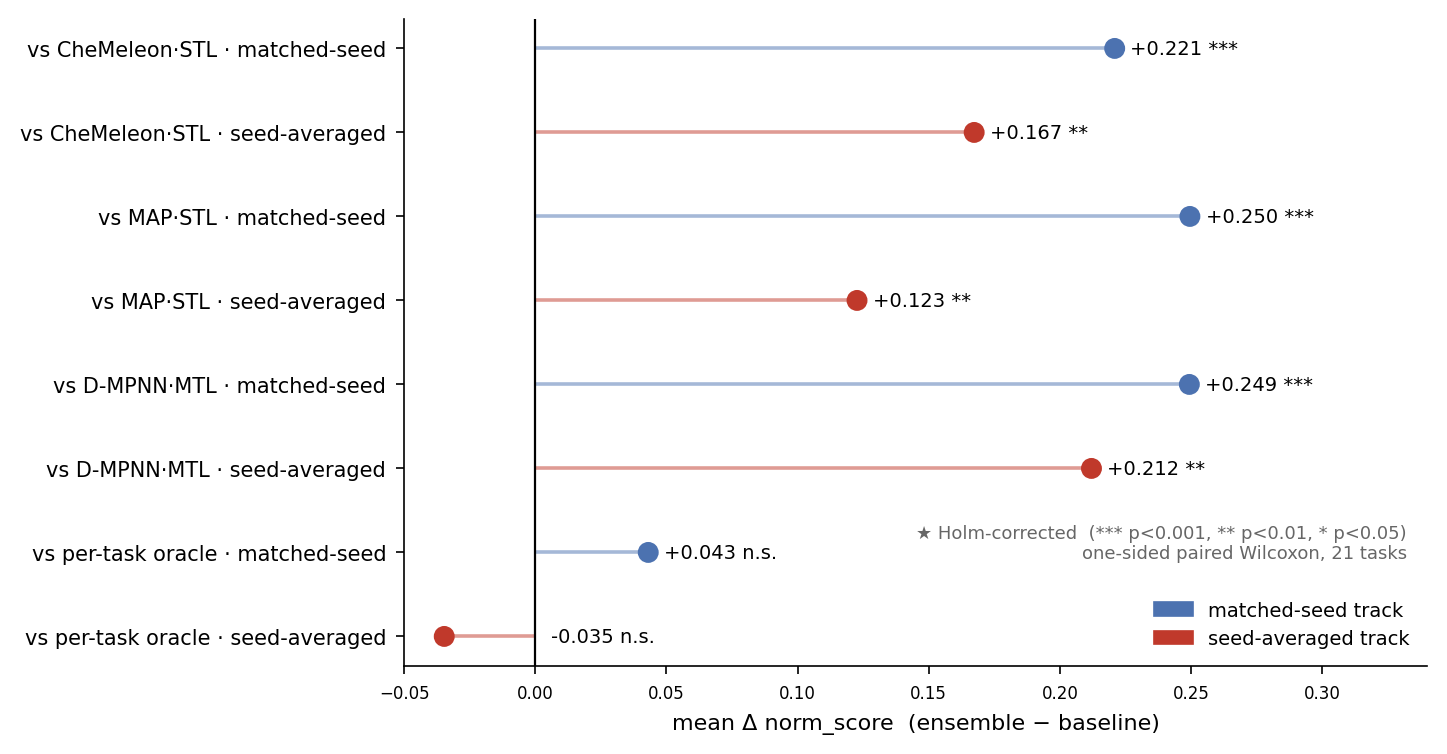

In [21]:
# === figure4.png (statistical significance of the ensemble gain — single forest panel) ===
import json
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import wilcoxon

apply_figure_style(sizes=(8, 7, 6))
GT = _GT; PT = _PT

# Single-model per-task norm on the SAME matched-seed(within)/seed-averaged(cross) basis as
# Table 3 and the ensemble (t4). _SOLO_PT (recomputed) provides both tracks consistently.
t4 = {e["task"]: e for e in PT["t4"] if e["task"] != "Bioavailability_Ma"}
_solo = _SOLO_PT
models = ["mtl_dmpnn", "mtl_chemeleon", "mtl_graphmvp", "mtl_molformer", "mtl_map",
          "stl_dmpnn", "stl_chemeleon", "stl_graphmvp", "stl_molformer", "stl_map"]
tasks = sorted(t for t in _solo.task.unique() if t in t4)
_piv_w = {m: _solo[_solo.model == m].set_index("task")["within_norm"] for m in models}
_piv_c = {m: _solo[_solo.model == m].set_index("task")["cross_norm"] for m in models}
ens_w = np.array([t4[d]["within_norm"] for d in tasks])
ens_c = np.array([t4[d]["cross_norm"] for d in tasks])
best_w = np.array([max(_piv_w[m][d] for m in models) for d in tasks])   # per-task oracle best single (matched-seed)
best_c = np.array([max(_piv_c[m][d] for m in models) for d in tasks])   # per-task oracle best single (seed-averaged)

def per_task_norm(model, track="within"):
    piv = _piv_w if track == "within" else _piv_c
    return np.array([piv[model][d] for d in tasks])

# --- eight prespecified comparisons: 3 deployable single models x 2 tracks + per-task oracle x 2 tracks ---
results = {}
for base_name, base_model in [("CheMeleon·STL", "stl_chemeleon"), ("MAP·STL", "stl_map"), ("D-MPNN·MTL", "mtl_dmpnn")]:
    for track, ens in [("within", ens_w), ("cross", ens_c)]:
        b = per_task_norm(base_model, track)
        diff = ens - b
        stat, p = wilcoxon(ens, b, alternative="greater")
        wins = int((diff > 1e-9).sum()); ties = int((abs(diff) <= 1e-9).sum()); losses = int((diff < -1e-9).sum())
        results[(base_name, track)] = dict(median=float(np.median(diff)), mean=float(diff.mean()),
                                           W=float(stat), p=float(p), wtl=f"{wins}/{ties}/{losses}",
                                           base_mean=float(b.mean()), ens_mean=float(ens.mean()))
oracle = {}
for track, ens, best_t in [("within", ens_w, best_w), ("cross", ens_c, best_c)]:
    diff = ens - best_t
    stat, p = wilcoxon(ens, best_t, alternative="greater")
    wins = int((diff > 1e-9).sum()); ties = int((abs(diff) <= 1e-9).sum()); losses = int((diff < -1e-9).sum())
    oracle[track] = dict(median=float(np.median(diff)), mean=float(diff.mean()),
                         W=float(stat), p=float(p), wtl=f"{wins}/{ties}/{losses}",
                         base_mean=float(best_t.mean()), ens_mean=float(ens.mean()))

# --- assemble ordered list + Holm-Bonferroni across all 8 prespecified comparisons ---
order = [("CheMeleon·STL", "within"), ("CheMeleon·STL", "cross"),
         ("MAP·STL", "within"), ("MAP·STL", "cross"),
         ("D-MPNN·MTL", "within"), ("D-MPNN·MTL", "cross"),
         ("per-task oracle", "within"), ("per-task oracle", "cross")]
rows = [ (oracle[tr] if base == "per-task oracle" else results[(base, tr)]) | {"base": base, "track": tr}
         for base, tr in order ]
_p = np.asarray([rw["p"] for rw in rows], float)
_ord = np.argsort(_p); _m = len(_p); _holm = np.empty(_m); _prev = 0.0
for _rank, _idx in enumerate(_ord):
    _val = (_m - _rank) * _p[_idx]; _prev = max(_prev, _val); _holm[_idx] = min(_prev, 1.0)
for rw, hp in zip(rows, _holm): rw["p_holm"] = float(hp)
_FIG4_STATS = rows   # per-comparison stats for the forest plot below

# --- single-panel forest plot: mean Δ norm_score with Holm-corrected significance ---
labels = [f"vs {rw['base']} · {'matched-seed' if rw['track']=='within' else 'seed-averaged'}" for rw in rows]
meds   = [rw["mean"] for rw in rows]
cols   = ["#c0392b" if rw["track"] == "cross" else "#4c72b0" for rw in rows]
stars  = ["***" if rw["p_holm"] < 0.001 else "**" if rw["p_holm"] < 0.01 else "*" if rw["p_holm"] < 0.05 else "n.s." for rw in rows]

plt.close('all')
fig, ax = plt.subplots(figsize=(6.6, 4.2))
y = np.arange(len(labels))[::-1]
ax.scatter(meds, y, s=48, color=cols, zorder=3)
ax.hlines(y, 0, meds, color=cols, lw=1.3, alpha=0.5)
ax.axvline(0, color="black", lw=0.8)
for yi, m_, st in zip(y, meds, stars):
    ax.text(max(m_, 0.0) + 0.006, yi, f"{m_:+.3f} {st}", va="center", fontsize=7)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=7.5)
ax.set_xlabel("mean Δ norm_score  (ensemble − baseline)")
ax.set_xlim(-0.05, 0.34)
# ax.set_title("k=5 late-fusion gain is significant vs three strong deployable single models",
#              loc="left", fontweight="bold", fontsize=9.5)
ax.legend(handles=[Patch(color="#4c72b0", label="matched-seed track"),
                   Patch(color="#c0392b", label="seed-averaged track")],
          loc="lower right", bbox_to_anchor=(1.0,0), fontsize=7, frameon=False)
ax.text(0.98, 0.16, "★ Holm-corrected  (*** p<0.001, ** p<0.01, * p<0.05)\none-sided paired Wilcoxon, 21 tasks",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=6.5, color="#666")
fig.savefig(os.path.join(OUTDIR, "figure4.png"), dpi=300, bbox_inches="tight")
print("saved figure4.png (single panel);", len(_FIG4_STATS), "comparisons")


*Fig. 4. Statistical validation of the ensemble gain. Forest plot of mean Δnorm_score (Tetra-Fuse − baseline) for each deployable single-model baseline (CheMeleon·STL, MAP·STL, D-MPNN·MTL) and evaluation track, with paired one-sided Wilcoxon significance (Holm-corrected across all eight comparisons; *** p < 0.001, ** p < 0.01, n.s. = not significant). Also shown is a per-task oracle (best single model chosen per task using test labels): a non-deployable reference, not a mathematical upper bound on ensemble performance — indeed the ensemble exceeds it on the matched-seed track. Per-comparison statistics are given in Supplementary Table S8.*

# 3.4 Analysis and validation of the late-fusion gain

## Fig. 5 Source and robustness of the late-fusion gain.

saved figure5.png (2-panel: a scatter, b raw-score winners {'mtl_dmpnn': 7, 'mtl_molformer': 6, 'stl_chemeleon': 3, 'stl_graphmvp': 1, 'stl_map': 4} )


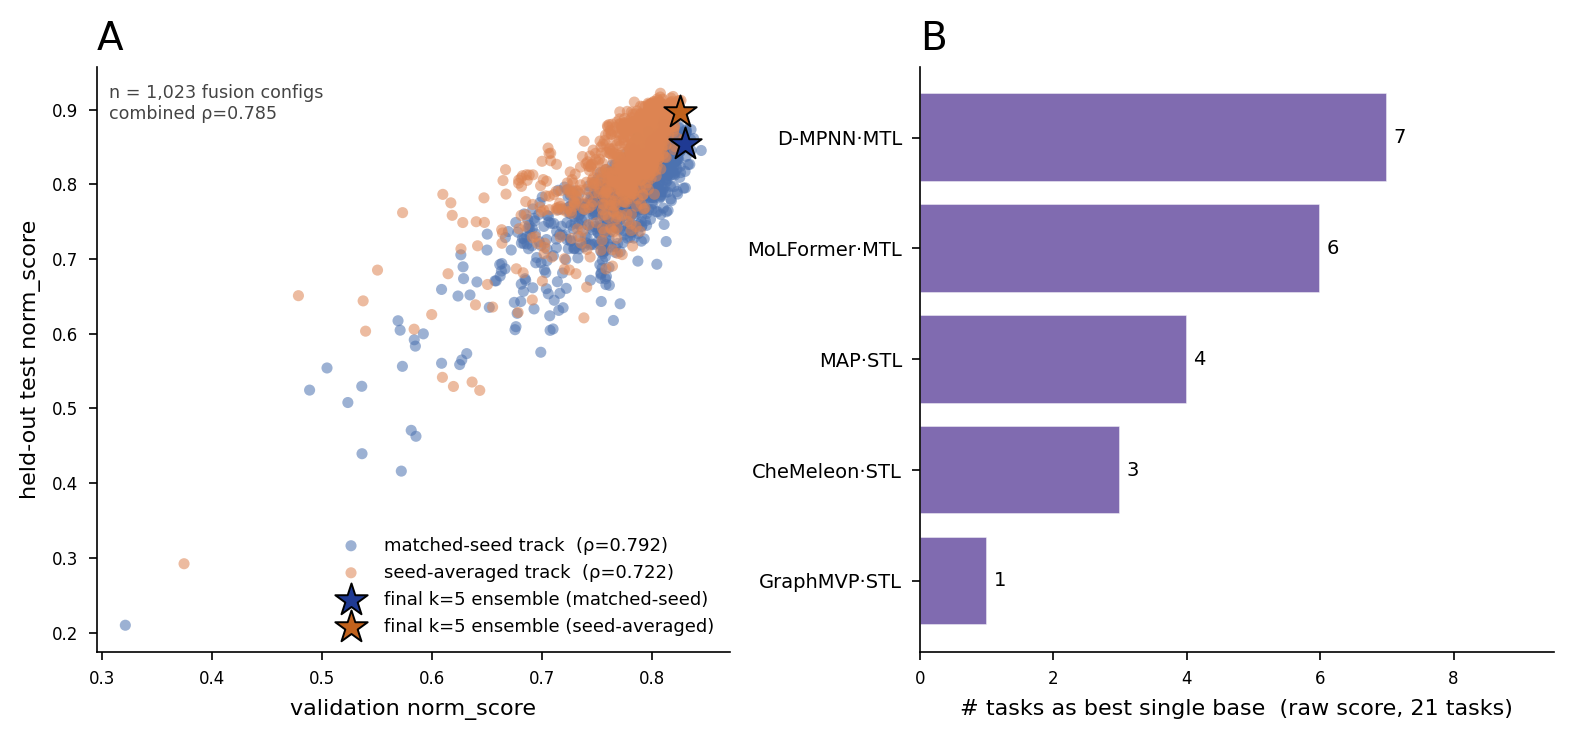

In [22]:
# === figure5.png (validation→test reliability + task-wise specialization) ===
import json, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import spearmanr, kendalltau

apply_figure_style(sizes=(8,7,6))
GT = _GT; PT = _PT
PRETTY = {
 "stl_chemeleon":"CheMeleon·STL","mtl_chemeleon":"CheMeleon·MTL",
 "stl_map":"MAP·STL","mtl_map":"MAP·MTL",
 "stl_dmpnn":"D-MPNN·STL","mtl_dmpnn":"D-MPNN·MTL",
 "stl_graphmvp":"GraphMVP·STL","mtl_graphmvp":"GraphMVP·MTL",
 "stl_molformer":"MoLFormer·STL","mtl_molformer":"MoLFormer·MTL",
}
STLc="#4c72b0"; MTLc="#dd8452"

# Panel A uses ALL 1,023 non-empty subsets (matches Section 3.4 body text).
vt=pd.read_csv(f"{DATA}/all1023.csv")
rw,_=spearmanr(vt.val_within, vt.test_within)   # matched-seed track
rc,_=spearmanr(vt.val_cross, vt.test_cross)     # seed-averaged track
rcomb2,_=spearmanr(vt.val_comb, vt.test_comb)
FINAL_KEY=",".join(sorted(GT["final_ensemble"]))

plt.close('all')
fig=plt.figure(figsize=(9.4,3.8))
gs=fig.add_gridspec(1,2, wspace=0.30)

# Panel a: validation vs held-out-test norm_score, both tracks
axA=fig.add_subplot(gs[0,0])
axA.scatter(vt.val_within, vt.test_within, s=16, color=STLc, alpha=0.55, edgecolor="none", label=f"matched-seed track  (\u03c1={rw:.3f})")
axA.scatter(vt.val_cross, vt.test_cross, s=16, color=MTLc, alpha=0.55, edgecolor="none", label=f"seed-averaged track  (\u03c1={rc:.3f})")
fk=vt[vt.combo_key==FINAL_KEY].iloc[0]
# final k=5 ensemble star, coloured by track (dark tones + black edge to stand out from the clouds)
STAR_W="#1f3a93"; STAR_C="#c1621d"   # matched-seed (dark blue), seed-averaged (dark orange)
axA.scatter([fk.val_within],[fk.test_within], s=150, marker="*", color=STAR_W, edgecolor="black", lw=0.7, zorder=5, label="final k=5 ensemble (matched-seed)")
axA.scatter([fk.val_cross],[fk.test_cross], s=150, marker="*", color=STAR_C, edgecolor="black", lw=0.7, zorder=5, label="final k=5 ensemble (seed-averaged)")
axA.set_xlabel("validation norm_score"); axA.set_ylabel("held-out test norm_score")
axA.set_title("A", fontsize=14)
# axA.set_title("a  Validation reliably ranks test performance", loc="left", fontweight="bold", fontsize=9)
axA.legend(fontsize=6.5, frameon=False, loc="lower right")
axA.text(0.02,0.97, f"n = {len(vt):,} fusion configs\ncombined \u03c1={rcomb2:.3f}",
         transform=axA.transAxes, va="top", fontsize=6.3, color="#444")

# Panel b: task-wise winner distribution among the k=5 members, ranked by RAW score
# (direction-aware: mae -> lowest raw wins, else highest raw wins). raw_score avoids the
# norm_score tie-boundary ambiguity; each of the 21 tasks has exactly one winner (no ties).
axB=fig.add_subplot(gs[0,1])
_wm=["mtl_dmpnn","mtl_molformer","stl_chemeleon","stl_graphmvp","stl_map"]
def _raw_within(model):
    base=merge_uniform([model], True); out={}
    for task in TASKS:
        met=REG[task]["metric"]
        t=base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        out[task]=float(np.mean([metric(met, gg.y_true, gg.yhat) for _,gg in t.groupby("seed")]))
    return out
_raw={m:_raw_within(m) for m in _wm}
win={m:0 for m in _wm}
for task in TASKS:
    met=REG[task]["metric"]; vals=[(_raw[m][task],m) for m in _wm]
    win[(min if met=="mae" else max)(vals)[1]] += 1
_WIN_RAW = dict(win)   # stashed (sum=21, no ties)
wmembers=["mtl_dmpnn","mtl_molformer","stl_map","stl_chemeleon","stl_graphmvp"]
wvals=[win[m] for m in wmembers]; wlab=[PRETTY[m] for m in wmembers]
yb=np.arange(len(wmembers))[::-1]
axB.barh(yb, wvals, color="#6a51a3", alpha=0.85, edgecolor="white")
axB.set_yticks(yb); axB.set_yticklabels(wlab, fontsize=7)
for y_,v in zip(yb,wvals): axB.text(v+0.1, y_, str(v), va="center", fontsize=7)
axB.set_xlabel("# tasks as best single base  (raw score, 21 tasks)")
axB.set_title("B", fontsize=14)
# axB.set_title("b  Gain comes from task-wise specialization", loc="left", fontweight="bold", fontsize=9)
axB.set_xlim(0,9.5)
corr=GT["corr"]["within"]
# axB.text(0.985,0.46,
#          f"Member predictions highly correlated\n(pred r={corr['pred_offdiag']:.3f},  residual r={corr['resid_offdiag']:.3f})\n\u2192 gain \u2260 error decorrelation",
#          transform=axB.transAxes, ha="right", va="top", fontsize=5.9, color="#c0392b",
#          bbox=dict(boxstyle="round,pad=0.4", fc="#fdf2f0", ec="#c0392b", lw=0.6))
# axB.text(0.985,0.06, f"best single (CheMeleon·STL) mean rank {GT['best_single']['within']['mean_rank']:.2f}\n\u2192 ensemble mean rank {GT['best_single']['within']['ens_rank']:.2f}",
#          transform=axB.transAxes, ha="right", va="bottom", fontsize=6, color="#333")

fig.savefig(os.path.join(OUTDIR,"figure5.png"), dpi=300, bbox_inches="tight")
print("saved figure5.png (2-panel: a scatter, b raw-score winners", _WIN_RAW, ")")


*Fig. 5. Source and robustness of the late-fusion gain. (a) Validation versus held-out-test norm_score for all 1,023 non-empty subsets of the 10 base models (each scored by uniform mean); ensemble size and membership were fixed on validation alone before the test set was accessed, and the test scores shown here were computed post-hoc for this transfer check. Rank correlations (descriptive): matched-seed ρ = 0.792, seed-averaged ρ = 0.722, combined ρ = 0.785. The final k = 5 ensemble is marked with a star in each track. (b) Number of tasks on which each of the five ensemble members is the single best member, ranked by the task's raw metric (matched-seed track): D-MPNN·MTL 7, MoLFormer·MTL 6, MAP·STL 4, CheMeleon·STL 3, GraphMVP·STL 1.*

In [23]:
# --- Table 5: per-member solo performance, leave-one-out effect, and Shapley contribution ---
# Solo norm is rounded from the un-rounded per-member mean (_SOLO_PT), NOT from the already-3sf
# _GT["loo_shapley"] snapshot, to avoid double-rounding (e.g. MAP·STL 0.60446 -> 0.604, matching the
# manuscript, rather than 0.6045 -> 0.605). LOO / Shapley come from _GT["loo_shapley"]:
# {model: [within_solo, loo_within, cross_solo, loo_cross, shap_within, shap_cross]}.
# Positive LOO Δ = removal hurts the ensemble. Row order = k=5 members as in the manuscript.
_T4_ORDER=["mtl_dmpnn","mtl_molformer","stl_chemeleon","stl_map","stl_graphmvp"]
_T4_PRETTY={"mtl_dmpnn":"D-MPNN·MTL","mtl_molformer":"MoLFormer·MTL","stl_chemeleon":"CheMeleon·STL",
            "stl_map":"MAP·STL","stl_graphmvp":"GraphMVP·STL"}
_ls=_GT["loo_shapley"]
_solo_w={m: float(_SOLO_PT[_SOLO_PT.model==m].within_norm.mean()) for m in _T4_ORDER}
_solo_c={m: float(_SOLO_PT[_SOLO_PT.model==m].cross_norm.mean())  for m in _T4_ORDER}
T4_rows=[]
for m in _T4_ORDER:
    v=_ls[m]
    T4_rows.append([_T4_PRETTY[m], round(_solo_w[m],3), round(_solo_c[m],3),
                    f"{v[1]:+.4f}", f"{v[3]:+.4f}", round(v[4],3), round(v[5],3)])
T4=pd.DataFrame(T4_rows, columns=["Member","Solo norm (matched-seed)","Solo norm (seed-averaged)",
    "LOO Δ (matched-seed)","LOO Δ (seed-averaged)","Shapley (matched-seed)","Shapley (seed-averaged)"])
register("table5_member_roles", T4)
# assert against manuscript Table 5 values (MAP·STL matched-seed solo = 0.604, not 0.605)
assert T4.iloc[0]["Member"]=="D-MPNN·MTL" and T4.iloc[0]["Solo norm (seed-averaged)"]==0.685
assert T4.iloc[3]["Member"]=="MAP·STL" and T4.iloc[3]["Solo norm (matched-seed)"]==0.604, T4.iloc[3].to_dict()
assert T4.iloc[4]["Member"]=="GraphMVP·STL" and T4.iloc[4]["LOO Δ (matched-seed)"]=="-0.0051"
print("Table 5 OK", T4.shape); T4


Table 5 OK (5, 7)


,Member,Solo norm (matched-seed),Solo norm (seed-averaged),LOO Δ (matched-seed),LOO Δ (seed-averaged),Shapley (matched-seed),Shapley (seed-averaged)
0,D-MPNN·MTL,0.605,0.685,+0.0577,+0.0605,0.208,0.209
1,MoLFormer·MTL,0.554,0.644,+0.0592,+0.0468,0.185,0.189
2,CheMeleon·STL,0.633,0.730,+0.0417,+0.0182,0.196,0.197
3,MAP·STL,0.604,0.774,+0.0220,+0.0088,0.176,0.203
4,GraphMVP·STL,0.416,0.524,-0.0051,-0.0130,0.088,0.099


*Table 5. Per-member roles within the k = 5 ensemble. For each of the five members we report the solo held-out-test norm_score, the leave-one-out effect (LOO Δ; the drop in ensemble norm_score when that member is removed, so positive = removal hurts), and the Shapley contribution (mean marginal value over all member coalitions), each on both the matched-seed and seed-averaged tracks. LOO reflects one fixed coalition whereas Shapley averages over all coalitions, so a member with a small or negative LOO can still carry a positive Shapley value.*

## Fig. S5 (Supplementary) — Ensemble-member roles: leave-one-out and Shapley

Per-member leave-one-out norm_score drop and Shapley contribution for the five k=5 ensemble members, on both the matched-seed and seed-averaged tracks. (Moved from the former main Figure 5 panels b–c.)

saved figureS5.png (LOO + Shapley)


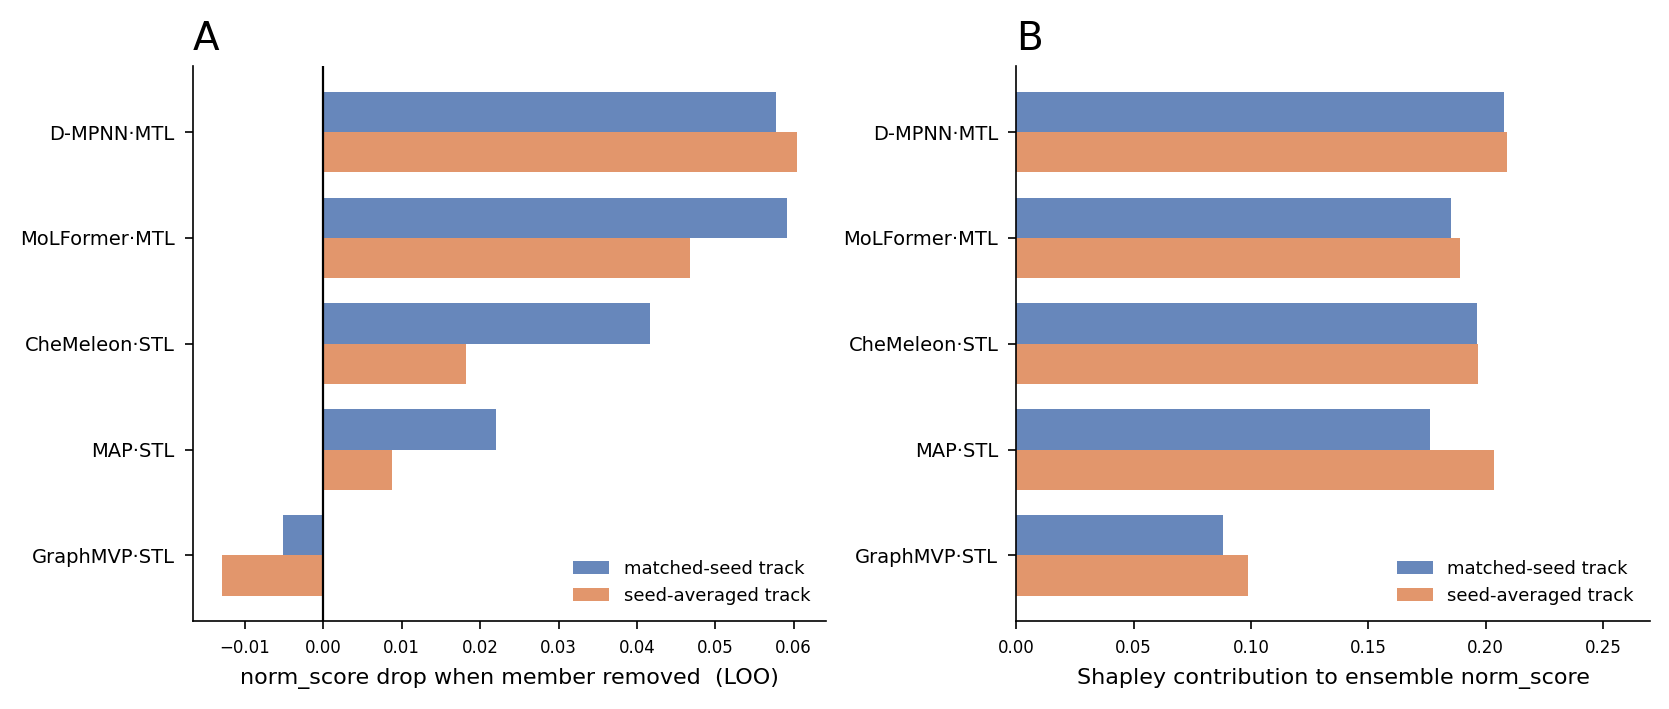

In [24]:
# === figureS5.png (Supplementary: ensemble-member roles — leave-one-out & Shapley) ===
import numpy as np, matplotlib.pyplot as plt
apply_figure_style(sizes=(8,7,6))
GT = _GT
PRETTY = {
 "stl_chemeleon":"CheMeleon·STL","mtl_chemeleon":"CheMeleon·MTL",
 "stl_map":"MAP·STL","mtl_map":"MAP·MTL",
 "stl_dmpnn":"D-MPNN·STL","mtl_dmpnn":"D-MPNN·MTL",
 "stl_graphmvp":"GraphMVP·STL","mtl_graphmvp":"GraphMVP·MTL",
 "stl_molformer":"MoLFormer·STL","mtl_molformer":"MoLFormer·MTL",
}
ls=GT["loo_shapley"]
members=["mtl_dmpnn","mtl_molformer","stl_chemeleon","stl_map","stl_graphmvp"]  # k=5, plot order
mpretty=[PRETTY[m] for m in members]
y=np.arange(len(members))[::-1]; bw=0.38

plt.close('all')
fig=plt.figure(figsize=(9.4,3.6))
gs=fig.add_gridspec(1,2, wspace=0.30)

# Panel a: leave-one-out norm_score drop per member (ls[m] = [within_solo,loo_within,cross_solo,loo_cross,shap_within,shap_cross])
axA=fig.add_subplot(gs[0,0])
loo_w=[ls[m][1] for m in members]; loo_c=[ls[m][3] for m in members]
axA.barh(y+bw/2, loo_w, height=bw, color="#4c72b0", label="matched-seed track", alpha=0.85)
axA.barh(y-bw/2, loo_c, height=bw, color="#dd8452", label="seed-averaged track", alpha=0.85)
axA.axvline(0, color="black", lw=0.8)
axA.set_yticks(y); axA.set_yticklabels(mpretty, fontsize=7)
axA.set_xlabel("norm_score drop when member removed  (LOO)")
axA.set_title("A", fontsize=14)
# axA.set_title("a  Leave-one-out: complementary roles", loc="left", fontweight="bold", fontsize=9)
axA.legend(fontsize=6.5, frameon=False, loc="lower right")
gy=np.arange(len(members))[::-1][members.index("stl_graphmvp")]
# axA.text(0.004, gy, "removal improves\nconsensus (\u0394<0)", fontsize=6, color="#3a7d44", ha="left", va="center")

# Panel b: Shapley contributions per member (both tracks)
axB=fig.add_subplot(gs[0,1])
sh_w=[ls[m][4] for m in members]; sh_c=[ls[m][5] for m in members]
axB.barh(y+bw/2, sh_w, height=bw, color="#4c72b0", label="matched-seed track", alpha=0.85)
axB.barh(y-bw/2, sh_c, height=bw, color="#dd8452", label="seed-averaged track", alpha=0.85)
axB.set_yticks(y); axB.set_yticklabels(mpretty, fontsize=7)
axB.set_xlabel("Shapley contribution to ensemble norm_score")
axB.set_title("B", fontsize=14)
# axB.set_title("b  Shapley: all members contribute", loc="left", fontweight="bold", fontsize=9)
axB.legend(fontsize=6.5, frameon=False, loc="lower right")
# for yi,(w_,c_) in zip(y,zip(sh_w,sh_c)):
#     axB.text(max(w_,c_)+0.004, yi, f"{w_:.3f}/{c_:.3f}", va="center", fontsize=5.5, color="#444")
axB.set_xlim(0, 0.27)

fig.savefig(os.path.join(OUTDIR,"figureS5.png"), dpi=300, bbox_inches="tight")
print("saved figureS5.png (LOO + Shapley)")


## Table S4 — Inter-model correlation among the five k=5 members

Inter-member dependence among the five k = 5 ensemble members: the mean absolute off-diagonal correlation of their standardized predictions and of their residuals (errors), on each track. High values indicate the members are strongly correlated, so the ensemble gain is not driven by error decorrelation.

In [25]:
# --- Table S4: inter-model correlation among the five k=5 ensemble members ---
corr=_GT["corr"]  # {'within':{'pred_offdiag','resid_offdiag'}, 'cross':{...}}
rows=[["matched-seed track", f'{corr["within"]["pred_offdiag"]:.3f}', f'{corr["within"]["resid_offdiag"]:.3f}'],
      ["seed-averaged track", f'{corr["cross"]["pred_offdiag"]:.3f}', f'{corr["cross"]["resid_offdiag"]:.3f}']]
S4=pd.DataFrame(rows, columns=["Track","Prediction corr (mean |off-diag|)","Residual/error corr (mean |off-diag|)"])
register("tableS4_inter_model_corr", S4)
assert S4.iloc[0]["Prediction corr (mean |off-diag|)"]=="0.767" and S4.iloc[0]["Residual/error corr (mean |off-diag|)"]=="0.837", S4.iloc[0].to_dict()
print("S4 OK", S4.shape); S4


S4 OK (2, 3)


,Track,Prediction corr (mean |off-diag|),Residual/error corr (mean |off-diag|)
0,matched-seed track,0.767,0.837
1,seed-averaged track,0.878,0.899


## Fig. S4 Inter-member correlation heatmaps (predictions and errors)

figureS4.png written | within pred/resid off-diag 0.767 0.837 | cross 0.878 0.899


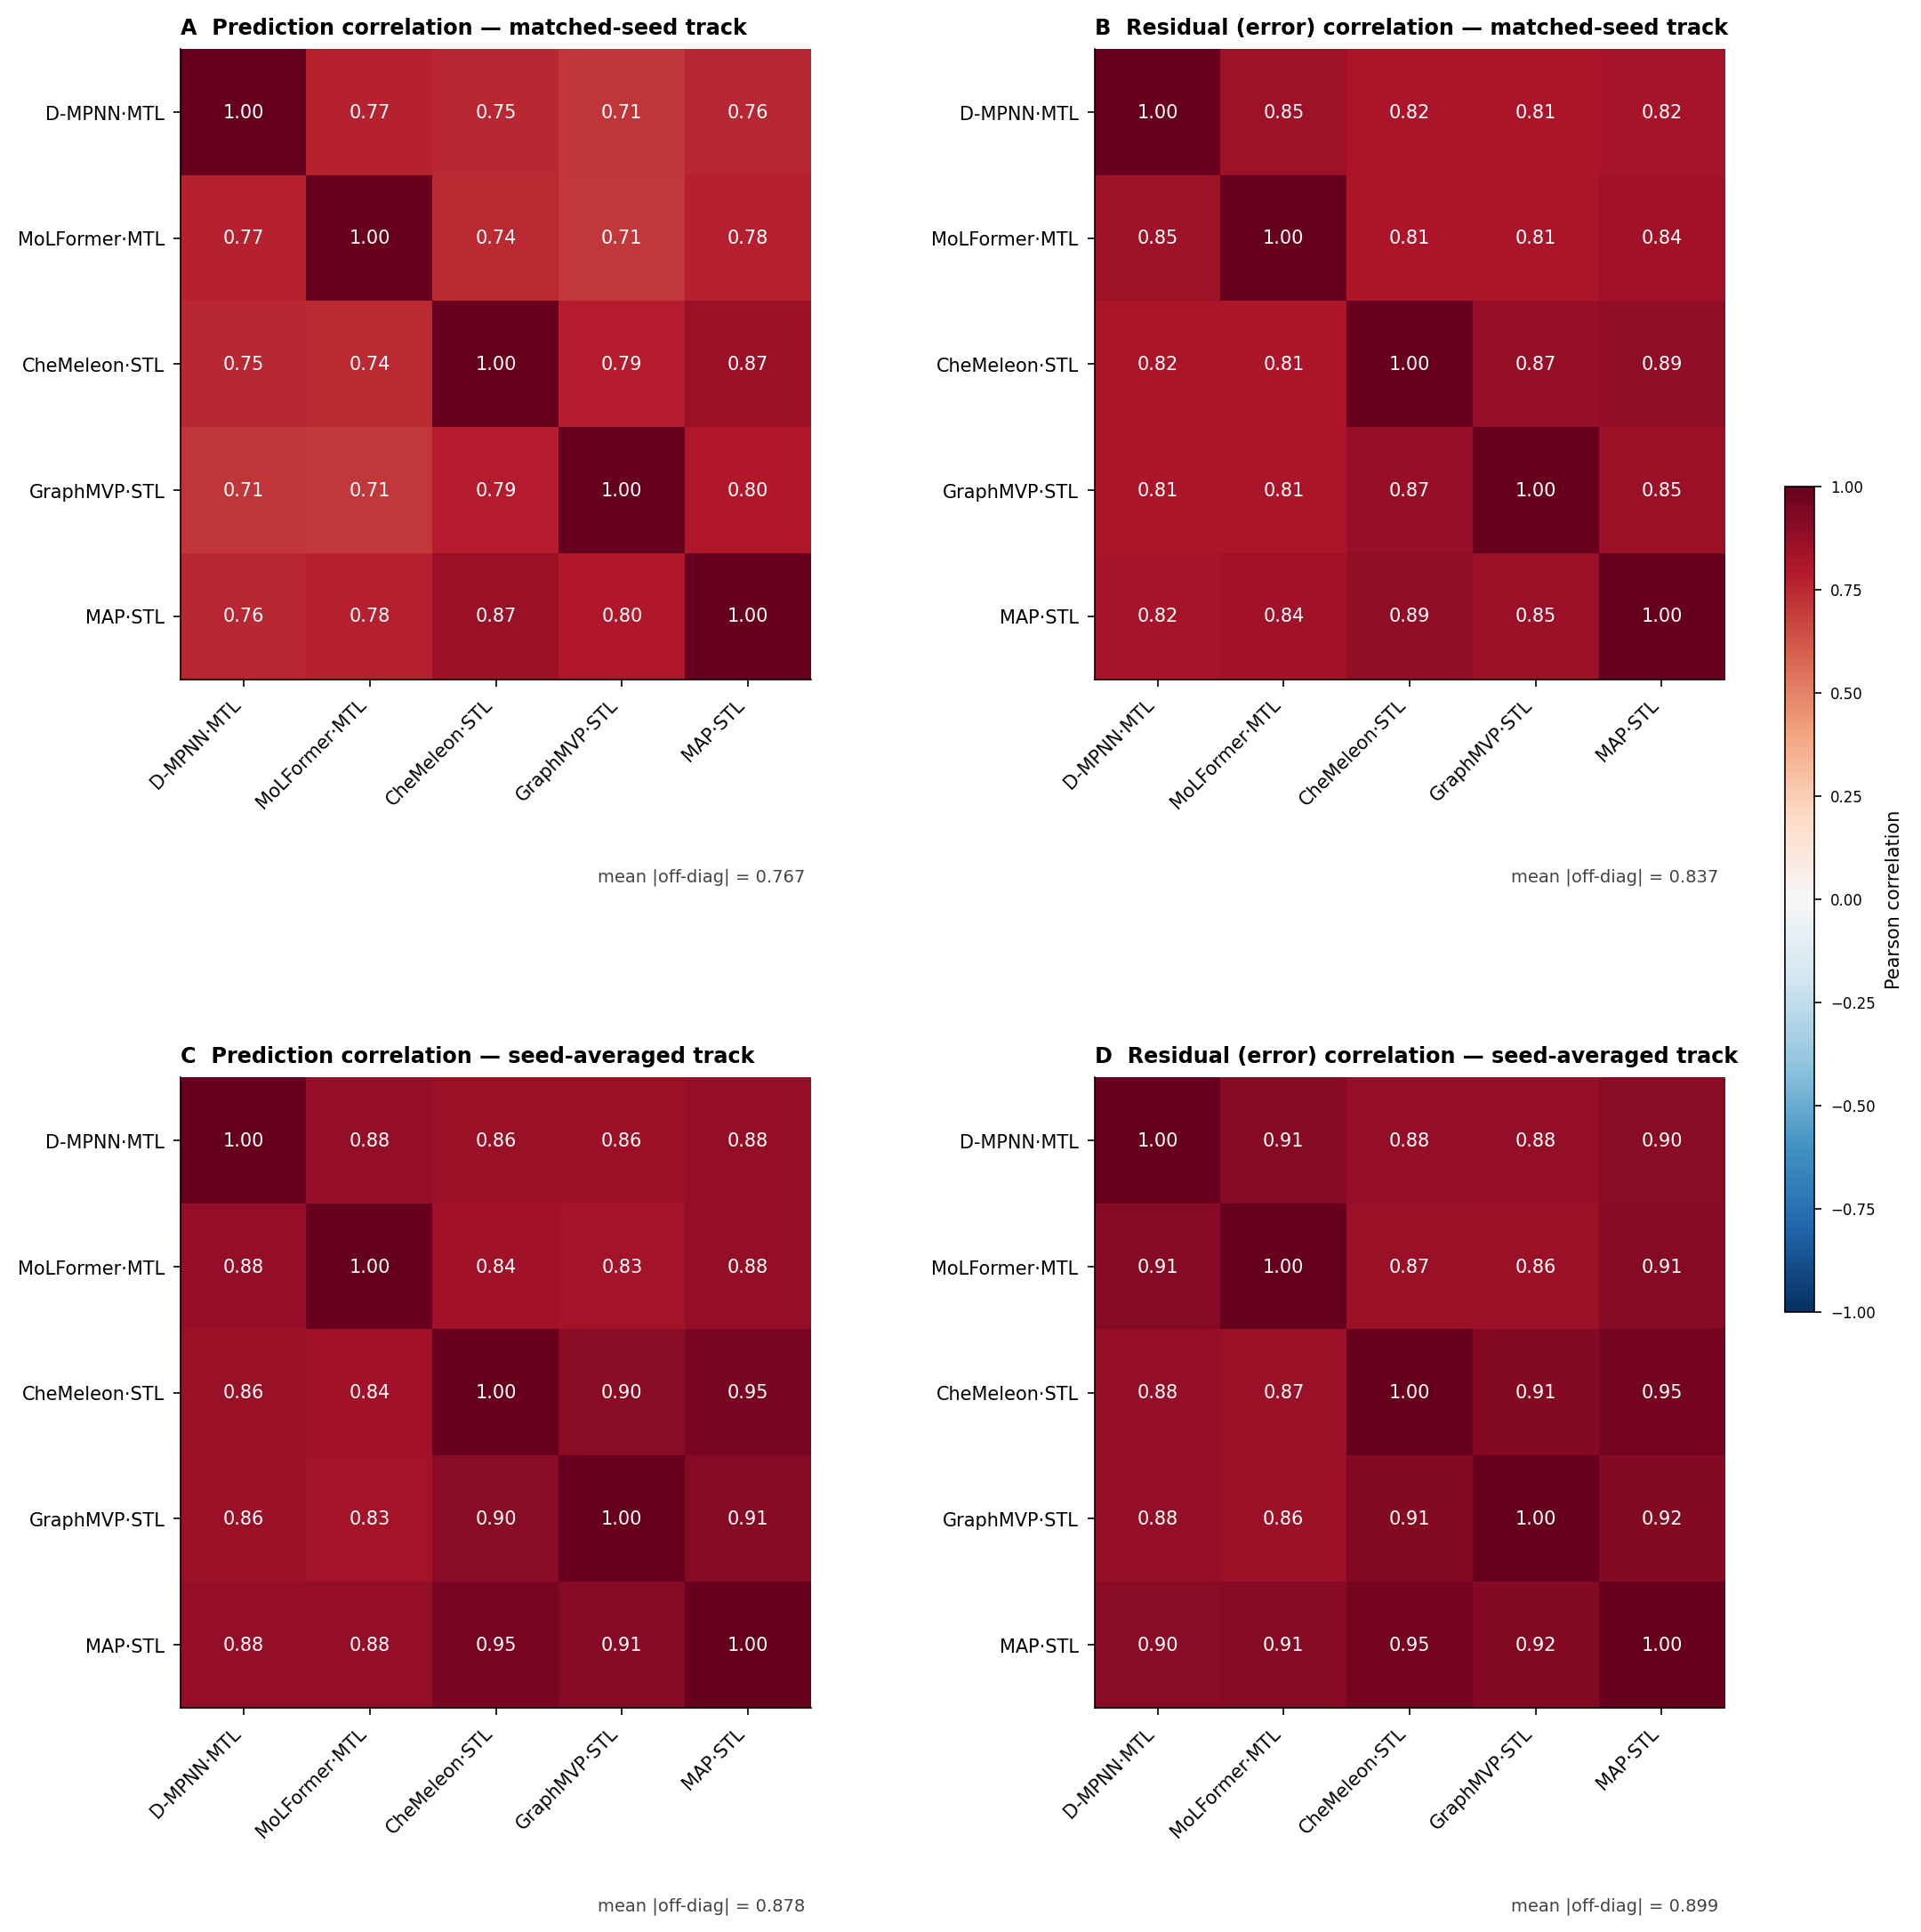

In [26]:
# === figureS4.png (Supplementary: inter-member correlation heatmaps, diagonal included) ===
# Full 5x5 correlation matrices among the k=5 ensemble members, for both standardized
# PREDICTIONS and standardized RESIDUALS (errors), on both tracks. Same recipe as Table S4
# (corr_matrices in setup) but returning the full matrix instead of the off-diagonal mean.
# The mean |off-diagonal| of each matrix equals the corresponding Table S4 entry (asserted).
import numpy as np, matplotlib.pyplot as plt

def _corr_full(within):
    """Full (pred_corr_mat, resid_corr_mat) 5x5 for the k=5 members — same standardization
    and averaging as setup's corr_matrices(), but returning the matrices (diagonal = 1)."""
    pred_cols=[f"p_{m}" for m in ENSEMBLE]; base=merge_uniform(ENSEMBLE, within)
    if not within:
        pz={m:[] for m in ENSEMBLE}; rz={m:[] for m in ENSEMBLE}
        for task in TASKS:
            rows=base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y=rows.y_true.to_numpy(float); P=rows[pred_cols].to_numpy(float)
            for j,m in enumerate(ENSEMBLE):
                p=P[:,j]; pz[m].append((p-p.mean())/(p.std()+1e-9))
                r=p-y; rz[m].append((r-r.mean())/(r.std()+1e-9))
        pz={m:np.concatenate(v) for m,v in pz.items()}; rz={m:np.concatenate(v) for m,v in rz.items()}
        Pm=np.corrcoef([pz[m] for m in ENSEMBLE]); Rm=np.corrcoef([rz[m] for m in ENSEMBLE])
    else:
        seeds=sorted(base.seed.unique()); pmats=[]; rmats=[]
        for task in TASKS:
            tr=base[base.task==task]
            for seed in seeds:
                sr=tr[(tr.seed==seed)&(tr.split=="test")].dropna(subset=["y_true"])
                if len(sr)<3: continue
                y=sr.y_true.to_numpy(float); P=sr[pred_cols].to_numpy(float)
                pzs=[]; rzs=[]
                for j,m in enumerate(ENSEMBLE):
                    p=P[:,j]; pzs.append((p-p.mean())/(p.std()+1e-9))
                    rzs.append((p-y)-(p-y).mean()/((p-y).std()+1e-9))
                pmats.append(np.corrcoef(pzs)); rmats.append(np.corrcoef(rzs))
        Pm=np.nanmean(pmats,0); Rm=np.nanmean(rmats,0)
    return Pm, Rm

PRETTY={"stl_chemeleon":"CheMeleon\u00b7STL","mtl_dmpnn":"D-MPNN\u00b7MTL","mtl_molformer":"MoLFormer\u00b7MTL",
        "stl_graphmvp":"GraphMVP\u00b7STL","stl_map":"MAP\u00b7STL"}
_labels=[PRETTY[m] for m in ENSEMBLE]
Pw,Rw=_corr_full(True)    # matched-seed track
Pc,Rc=_corr_full(False)   # seed-averaged track

# verify against Table S4 off-diagonal means
_off=np.triu_indices(len(ENSEMBLE),1)
for mat,exp in [(Pw,0.767),(Rw,0.837),(Pc,0.878),(Rc,0.899)]:
    assert abs(float(np.abs(mat[_off]).mean())-exp)<0.005, (float(np.abs(mat[_off]).mean()),exp)

apply_figure_style(sizes=(8,7,6))
plt.close('all')
fig,axes=plt.subplots(2,2,figsize=(11.2,11.6))
fig.subplots_adjust(hspace=0.55, wspace=0.45, top=0.92, bottom=0.10, right=0.90)
panels=[(axes[0,0],Pw,"A  Prediction correlation \u2014 matched-seed track"),
        (axes[0,1],Rw,"B  Residual (error) correlation \u2014 matched-seed track"),
        (axes[1,0],Pc,"C  Prediction correlation \u2014 seed-averaged track"),
        (axes[1,1],Rc,"D  Residual (error) correlation \u2014 seed-averaged track")]
n=len(ENSEMBLE)
for ax,M,title in panels:
    im=ax.imshow(M,cmap="RdBu_r",vmin=-1,vmax=1,aspect="equal")
    ax.set_xticks(range(n)); ax.set_xticklabels(_labels,rotation=45,ha="right",fontsize=7.5)
    ax.set_yticks(range(n)); ax.set_yticklabels(_labels,fontsize=7.5)
    for i in range(n):
        for j in range(n):
            v=M[i,j]
            ax.text(j,i,f"{v:.2f}",ha="center",va="center",fontsize=7.5,
                    color="white" if abs(v)>0.6 else "black")
    ax.set_title(title,loc="left",fontweight="bold",fontsize=8.6)
    off=float(np.abs(M[_off]).mean())
    ax.text(0.99,-0.30,f"mean |off-diag| = {off:.3f}",transform=ax.transAxes,ha="right",va="top",fontsize=7,color="#444")
cax=fig.add_axes([0.93,0.30,0.015,0.4]); cb=fig.colorbar(im,cax=cax); cb.set_label("Pearson correlation",fontsize=7.5)
# fig.suptitle("Inter-member correlation among the five k=5 ensemble members (diagonal = self-correlation = 1)",
#              fontweight="bold",fontsize=9.5,y=0.985)
fig.savefig(os.path.join(OUTDIR,"figureS4.png"),dpi=300,bbox_inches="tight")
print("figureS4.png written | within pred/resid off-diag",
      round(float(np.abs(Pw[_off]).mean()),3), round(float(np.abs(Rw[_off]).mean()),3),
      "| cross", round(float(np.abs(Pc[_off]).mean()),3), round(float(np.abs(Rc[_off]).mean()),3))
plt.show()


*Figure S4. Full 5×5 correlation matrices among the five k = 5 ensemble members, for the standardized predictions (left) and the standardized residuals/errors (right), on the matched-seed (top) and seed-averaged (bottom) tracks. The diagonal is the self-correlation (= 1); the mean absolute off-diagonal value of each matrix, printed below each panel, is the corresponding entry of Supplementary Table S4. The uniformly high off-diagonal values show that the members are strongly correlated in both their predictions and their errors, so the ensemble gain is not driven by error decorrelation.*

# 3.5 External validation on the Polaris ADME-Fang benchmark

## Fig. 6. Tetra-Fuse on the official Polaris ADME-Fang leaderboards.

figure6.png written (matches manuscript)


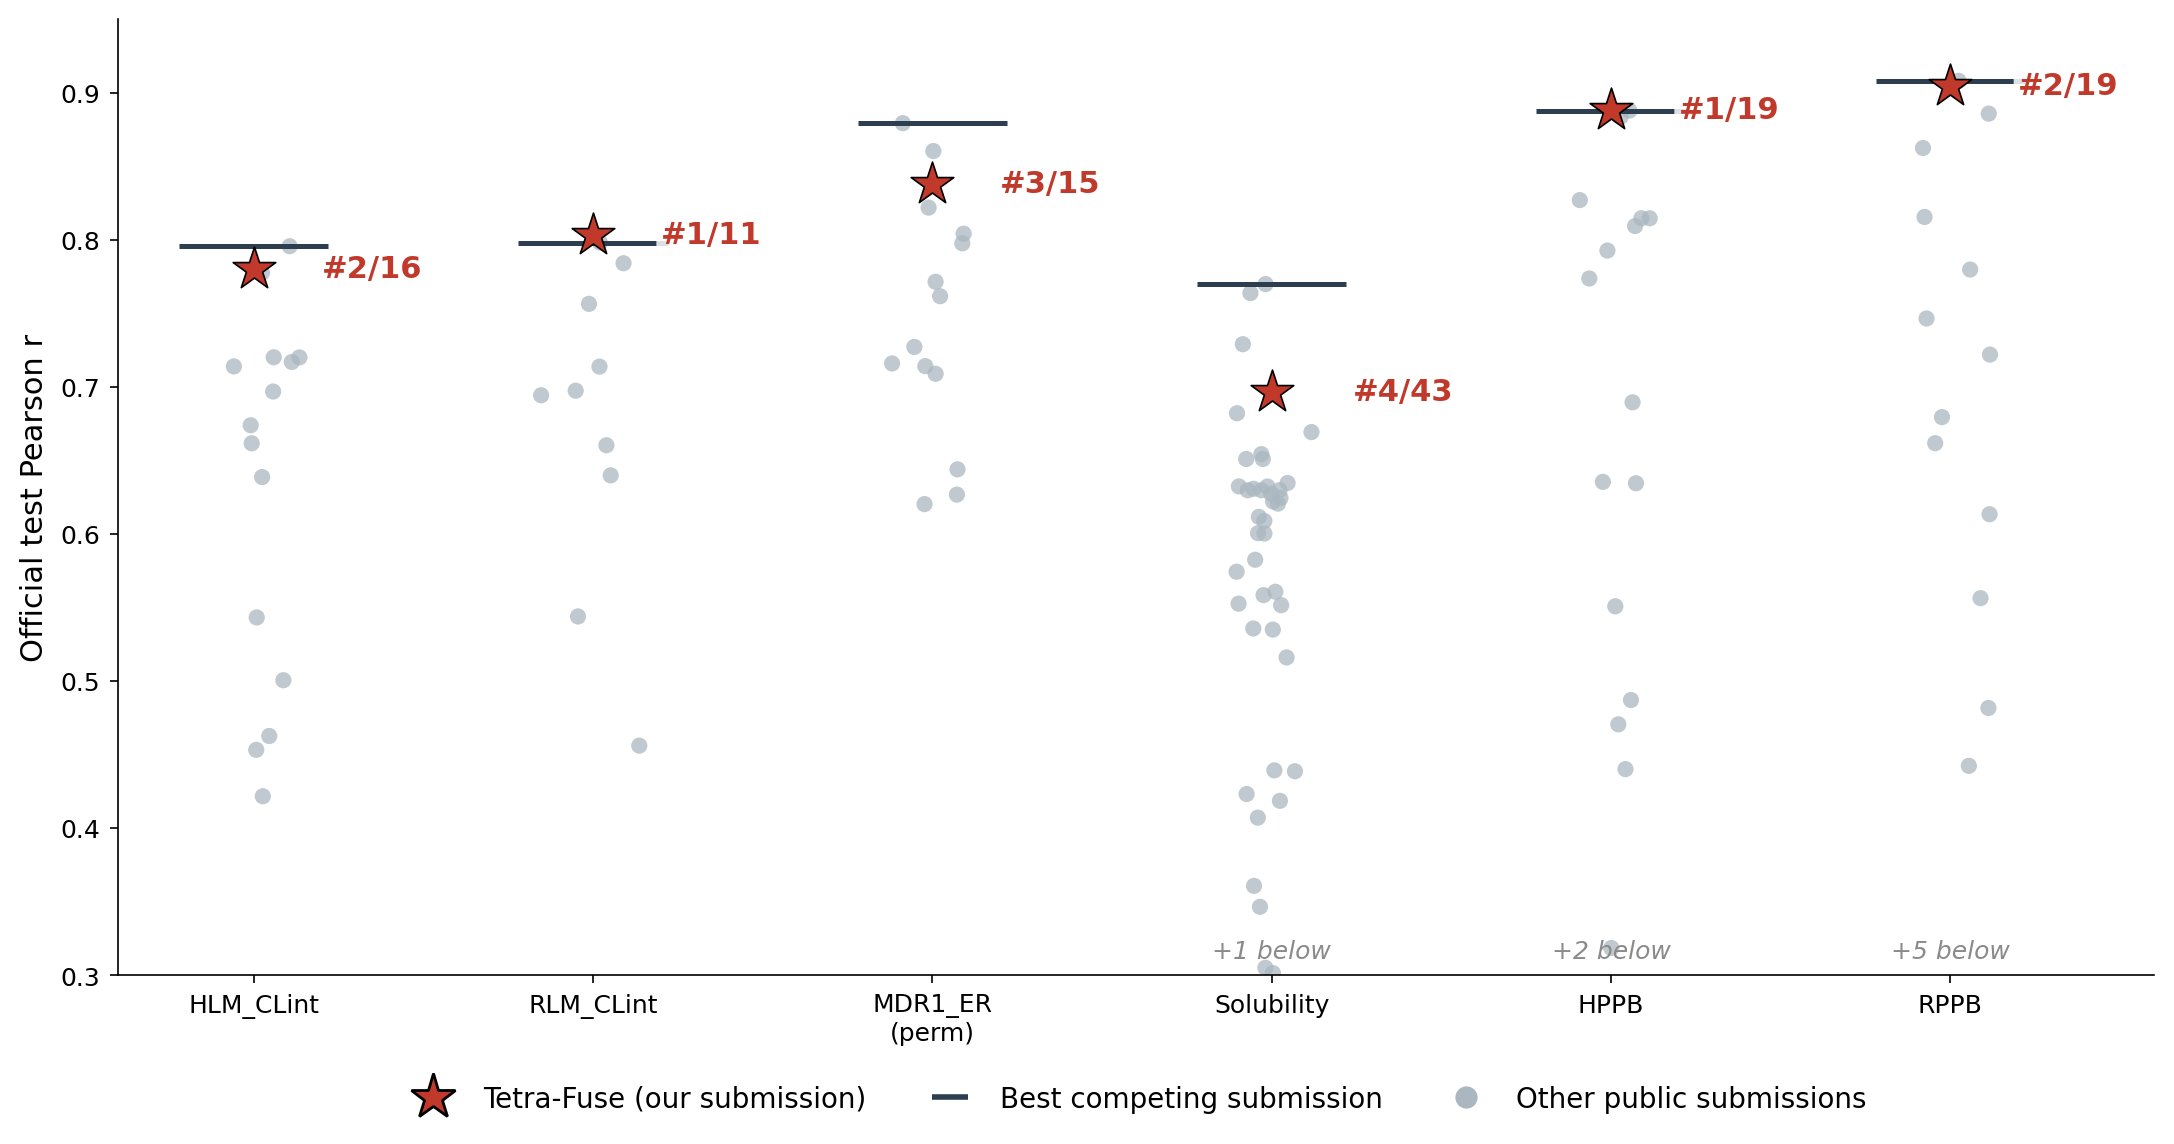

In [27]:
# === figure6.png (external validation: Polaris ADME-Fang leaderboards) ===
import json, numpy as np, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
apply_figure_style(sizes=(11,10,9))

with open(os.path.join(DATA, "polaris_leaderboard_full.json")) as f:
    full = json.load(f)   # {key: [[name, pearson],...]}
RED, GREY, DARK = "#c0392b", "#aab7c0", "#2c3e50"
order  = ["hclint","rclint","perm","solu","hppb","rppb"]
labmap = {"hclint":"HLM_CLint","rclint":"RLM_CLint","perm":"MDR1_ER\n(perm)",
          "solu":"Solubility","hppb":"HPPB","rppb":"RPPB"}
YLO, YHI = 0.3, 0.95
np.random.seed(0)

fig, ax = plt.subplots(figsize=(11, 5.8))
for i, key in enumerate(order):
    entries = full[key]
    others  = [(n,p) for n,p in entries if n!="LateFusion-k5"]
    our     = [p for n,p in entries if n=="LateFusion-k5"][0]
    ordered = sorted(entries, key=lambda x:-x[1])
    rank    = [j+1 for j,(n,p) in enumerate(ordered) if n=="LateFusion-k5"][0]
    total   = len(entries)
    ys=[p for _,p in others]; xs=np.random.normal(i,0.06,size=len(ys))
    ax.scatter(xs, ys, s=34, color=GREY, alpha=0.75, edgecolor="none", zorder=2)
    best_excl = max(p for n,p in others)   # leaderboard best EXCLUDING our own entry
    ax.hlines(best_excl, i-0.22, i+0.22, color=DARK, lw=1.8, zorder=3)
    ax.scatter([i],[our], s=260, marker="*", color=RED, edgecolor="black", lw=0.6, zorder=6)
    dx = 0.20 if key!="solu" else 0.24
    ax.text(i+dx, our, f"#{rank}/{total}", ha="left", va="center", fontsize=11,
            color=RED, fontweight="bold", zorder=7,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    nbc=sum(1 for _,p in entries if p<YLO)
    if nbc: ax.text(i, YLO+0.008, f"+{nbc} below", ha="center", va="bottom",
                   fontsize=9, color="#8a8a8a", style="italic", zorder=4)
ax.set_xticks(range(len(order))); ax.set_xticklabels([labmap[k] for k in order])
ax.set_ylabel("Official test Pearson r"); ax.set_ylim(YLO,YHI); ax.set_xlim(-0.4,5.6)
# ax.set_title("Tetra-Fuse vs all public submissions on Polaris ADME-Fang leaderboards")
leg=[Line2D([0],[0],marker="*",color="w",markerfacecolor=RED,markeredgecolor="black",markersize=17,label="Tetra-Fuse (our submission)"),
     Line2D([0],[0],marker="_",color=DARK,markersize=13,markeredgewidth=2.0,label="Best competing submission",linestyle="None"),
     Line2D([0],[0],marker="o",color="w",markerfacecolor=GREY,markersize=9,label="Other public submissions")]
ax.legend(handles=leg, frameon=False, loc="lower center", ncol=3, bbox_to_anchor=(0.5,-0.17))
fig.tight_layout(); fig.savefig(os.path.join(OUTDIR,"figure6.png"), dpi=300, bbox_inches="tight")
# plt.close(fig);
print("figure6.png written (matches manuscript)")


*Fig. 6. Tetra-Fuse on the official Polaris ADME-Fang leaderboards. Each point is a public submission scored by the Polaris Hub on the held-out test set (Pearson r); across the six endpoints, the red star marks our seed-averaged uniform-mean ensemble and the horizontal bar the best competing submission (the highest-scoring public entry other than our own; on endpoints where we rank first this is therefore the runner-up). Submissions with Pearson r below 0.3 are summarized by a per-column count ("+N below") rather than plotted. Ranks shown next to each star are among publicly listed submissions.*

## Table S6 — Polaris ADME-Fang external benchmark: endpoints and Tetra-Fuse performance

The six Polaris ADME-Fang external benchmark endpoints. For each endpoint the table lists the dataset descriptors — Polaris slug, target variable, and the number of training-plus-validation and test molecules — together with Tetra-Fuse's seed-averaged performance on the official Polaris leaderboard: our Pearson r on the held-out test set, our rank among publicly listed submissions, the best competing submission (highest-scoring public entry other than our own) with its model, and the signed gap (ours − best competing; positive where Tetra-Fuse leads). On RLM_CLint and HPPB, where Tetra-Fuse ranks first, this best-competing score is the runner-up. (This table consolidates the external-validation dataset and performance information; our public entry is labelled LateFusion-k5.)

In [28]:
# --- Table S6: Polaris ADME-Fang external benchmark — dataset descriptors + Tetra-Fuse performance ---
# Consolidated table combining the former main Table 6 (seed-averaged Polaris leaderboard performance)
# with the endpoint/dataset descriptors. Rows are the six ADME-Fang endpoints (fixed order). Dataset
# descriptors (dataset slug, target variable, n train+val, n test) are the benchmark's metadata;
# performance (our Pearson r, rank, leaderboard best, gap) is reproduced from
# polaris_leaderboard_full.json = {slug: [[model, pearson], ...]}; our public entry is "LateFusion-k5".
with open(os.path.join(DATA, "polaris_leaderboard_full.json")) as f: _pol=json.load(f)
_S6_META = [
    ("hclint","HLM_CLint", "adme-fang-hclint-reg-v1","LOG_HLM_CLint",   "2230","576"),
    ("rclint","RLM_CLint", "adme-fang-rclint-reg-v1","LOG_RLM_CLint",   "2220","559"),
    ("perm",  "MDR1_ER",   "adme-fang-perm-reg-v1",  "LOG_MDR1-MDCK_ER","1920","483"),
    ("solu",  "Solubility","adme-fang-solu-reg-v1",  "LOG_SOLUBILITY",  "1578","400"),
    ("hppb",  "HPPB",      "adme-fang-hppb-reg-v1",  "LOG_HPPB",        "126", "34"),
    ("rppb",  "RPPB",      "adme-fang-rppb-reg-v1",  "LOG_RPPB",        "111", "24"),
]
S6_rows=[]
for slug,nm,dslug,target,ntr,nte in _S6_META:
    board=sorted(_pol[slug], key=lambda x:-x[1])                       # descending Pearson r
    rank,(mm,ss)=[(i,b) for i,b in enumerate(board,1) if b[0]=="LateFusion-k5"][0]
    _others=[b for b in board if b[0]!="LateFusion-k5"]   # exclude our own entry
    best_m,best_s=_others[0]                               # best COMPETING submission
    _gap=ss-best_s                                        # ours - best_competitor (+ = we lead)
    S6_rows.append([nm, dslug, target, ntr, nte,
                    round(ss,4), f"{rank}/{len(board)}", f"{best_s:.4f} ({best_m})", f"{_gap:+.4f}"])
S6=pd.DataFrame(S6_rows, columns=["Endpoint","Polaris slug","Target variable","n (train+val)","n (test)",
                                  "Our Pearson r","Rank","Best competing submission","Gap (ours − best)"])
register("tableS6_polaris_datasets", S6)
assert len(S6)==6 and S6.iloc[0]["Endpoint"]=="HLM_CLint"
assert S6.iloc[0]["Our Pearson r"]==0.7804 and S6.iloc[1]["Rank"]=="1/11" and S6.iloc[4]["Rank"]=="1/19"
assert S6.iloc[1]["Gap (ours − best)"].startswith("+") and S6.iloc[4]["Gap (ours − best)"].startswith("+"), "RLM_CLint/HPPB should lead"
assert not S6.iloc[0]["Best competing submission"].startswith("0.0000") and "LateFusion-k5" not in "".join(S6["Best competing submission"])
print("Table S6 (merged: datasets + performance) OK", S6.shape); S6


Table S6 (merged: datasets + performance) OK (6, 9)


,Endpoint,Polaris slug,Target variable,n (train+val),n (test),Our Pearson r,Rank,Best competing submission,Gap (ours − best)
0,HLM_CLint,adme-fang-hclint-reg-v1,LOG_HLM_CLint,2230,576,0.7804,2/16,0.7957 (seqera-gradient),-0.0153
1,RLM_CLint,adme-fang-rclint-reg-v1,LOG_RLM_CLint,2220,559,0.8033,1/11,0.7983 (1B_MPNN_MolGPS-ens_LargeMix),+0.0050
2,MDR1_ER,adme-fang-perm-reg-v1,LOG_MDR1-MDCK_ER,1920,483,0.8381,3/15,0.8794 (1B_MPNN_MolGPS-ens_LargeMix),-0.0413
3,Solubility,adme-fang-solu-reg-v1,LOG_SOLUBILITY,1578,400,0.6966,4/43,0.7700 (1B_MPNN_MolGPS-ens_LargeMix),-0.0734
4,HPPB,adme-fang-hppb-reg-v1,LOG_HPPB,126,34,0.8884,1/19,0.8879 (1B_MPNN_LargeMix-and-Phenomics),+0.0005
5,RPPB,adme-fang-rppb-reg-v1,LOG_RPPB,111,24,0.9049,2/19,0.9082 (1B_MPNN_LargeMix-and-Phenomics),-0.0033


# Consolidated workbook

In [29]:
# --- write consolidated multi-sheet workbook ---
sheetmap={"table1_positioning":"T1_positioning","table2_mechanism_grouping":"T2_grouping","table3_ensemble_summary":"T3_summary","table4_ensemble_pertask":"T4_pertask","table5_member_roles":"T5_members",
    "tableS1_per_backbone_pertask":"S1_per_backbone","tableS2_representation_aggregation":"S2_aggregation",
    "tableS3_ksweep":"S3_ksweep","tableS4_inter_model_corr":"S4_corr","tableS5_reproducibility":"S5_reproducibility",
    "tableS6_polaris_datasets":"S6_datasets","tableS7_dataset_provenance":"S7_provenance","tableS8_ensemble_vs_baselines":"S8_significance"}
with pd.ExcelWriter(os.path.join(OUT,"supplementary_tables.xlsx"), engine="openpyxl") as xw:
    for name,(df,idx) in TABLES.items():
        df.to_excel(xw, sheet_name=sheetmap.get(name,name)[:31], index=idx)
print("wrote", len(TABLES), "tables ->", sorted(os.listdir(OUT)))


wrote 13 tables -> ['supplementary_tables.xlsx', 'table1_positioning.csv', 'table2_mechanism_grouping.csv', 'table3_ensemble_summary.csv', 'table4_ensemble_pertask.csv', 'table5_member_roles.csv', 'tableS1_per_backbone_pertask.csv', 'tableS2_representation_aggregation.csv', 'tableS3_ksweep.csv', 'tableS4_inter_model_corr.csv', 'tableS5_reproducibility.csv', 'tableS6_polaris_datasets.csv', 'tableS7_dataset_provenance.csv', 'tableS8_ensemble_vs_baselines.csv']
